# Previous applications: EDA and feature engineering

This notebook studies `previous_application.csv`, the record of every earlier application each applicant made to Home Credit itself, and turns it into features, one row per applicant.

It follows the same method as `03_bureau_eda_features.ipynb`, which did this for the credit bureau table. That table went on to raise the model's cross-validated ROC AUC from 0.7685 to 0.7779, and its Kaggle private score from 0.7638 to 0.7753 (`04_model_with_bureau.ipynb`).

## Why this table

The bureau table describes an applicant's credit at **other** lenders. This one describes their history with **Home Credit**: what they applied for before, whether they were approved or refused and why, on what terms, and when those loans ended. Three more tables hang beneath it and record how the approved loans were actually repaid, month by month.

```
application (1 row per applicant)
   ├── bureau (credits at other lenders)                                   <- done, notebooks 03 and 04
   └── previous_application (0 to many earlier applications to Home Credit) <- this notebook
          ├── installments_payments   (each payment made)
          ├── POS_CASH_balance        (monthly state of cash and point-of-sale loans)
          └── credit_card_balance     (monthly state of credit cards)
```

This notebook covers `previous_application` only. It looks at the three child tables far enough to see how they link and whether they are supplied on the same terms in train and test, because that question decided what could be used from the bureau tables. Their contents are for later notebooks.

## Inputs

| File | Rows | One row is | Key |
|---|---:|---|---|
| `data/raw/previous_application.csv` | about 1.7 million | One earlier application to Home Credit | `SK_ID_PREV`, linked to the applicant by `SK_ID_CURR` |
| `data/processed/application_split.parquet` | 307,511 | The frozen development and holdout split | `SK_ID_CURR` |

## What this notebook does

| # | Stage | Question it answers |
|---|---|---|
| 1 | Structure and keys | Is `SK_ID_PREV` unique, how many earlier applications does an applicant have, and how do the tables link? |
| 2 | Coverage and target | Do applicants with no earlier application default at a different rate? Is coverage the same in train and test? |
| 3 | Column-by-column audit | Is each value believable, and is each column supplied on the same terms in train and test? |
| 4 | Time audit | Does any column describe something after the current application? |
| 5 | Row-level signal | Which columns relate to default? |
| 6 | Aggregation design | Which summaries per applicant are worth building? |
| 7 | Candidate features | Build them for train and test, and verify them by an independent calculation |
| 8 | Screening | Shift, redundancy and signal, and a first cut of the list |
| 9 | Save | Write the feature tables and verify them from disk |

Each stage ends with a findings cell and the decisions taken.

## Rules followed throughout

These are the rules of notebook 03, unchanged.

- **The holdout stays closed.** Whenever this notebook looks at `TARGET`, it uses the 246,008 development applicants only. Holdout applicants get features, and their outcomes are never loaded.
- **A feature uses only the applicant's own rows.** No summary is computed across applicants.
- **Nothing is learned from the target here.** A feature that needs the target belongs inside the model pipeline, where it can be fitted on training folds.
- **Only information available at the application date is used.** Stage 4 checks every date.
- **Every column is audited twice:** is the value believable, and is the column supplied on the same terms in train and test? The second question removed `bureau_balance` and `AMT_ANNUITY` from the bureau work. Both would have looked excellent in cross-validation.
- **Rare events are not judged by AUC alone.** A feature that is zero for almost everyone can matter a great deal to the few it describes. The bureau work met this three times.

## What is different about this table

- **The outcome of an earlier application is itself information of a new kind.** A refusal is Home Credit's own earlier judgement of the applicant. That is legitimate history, known at the time of the new application. But it needs care in stage 4: it must be the outcome of an *earlier* application, never anything that reflects the current one.
- **Many columns only make sense for some rows.** A refused application has no payment dates. A cash loan has no goods price. Missing values here are often structure, not gaps.

## What this notebook produces

- Cleaning rules for `previous_application`.
- A feature table, one row per applicant, for train and test, saved under `data/processed/`.
- A module under `src/features/` so the table can be rebuilt without the notebook.

## Out of scope

- Whether the features improve the model. That is a later notebook, on the same frozen folds.
- The contents of `installments_payments`, `POS_CASH_balance` and `credit_card_balance`.

## Stage 1: Structure and keys

What is in `previous_application.csv`, what identifies a row, how many earlier applications an applicant has, and how the table links to the application table above it and to the three tables below it.

No target is used in this stage.

In [1]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 220)

SEED = 42
RAW = '../data/raw'
PROCESSED = '../data/processed'

started = time.time()
prev = pd.read_csv(f'{RAW}/previous_application.csv')
print(f"previous_application.csv: {prev.shape[0]:,} rows, {prev.shape[1]} columns, {prev.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory, read in {time.time() - started:.1f} seconds")
prev.head(3).T

previous_application.csv: 1,670,214 rows, 37 columns, 704 MB in memory, read in 16.6 seconds


,0,1,2
SK_ID_PREV,2030495,2802425,2523466
SK_ID_CURR,271877,108129,122040
NAME_CONTRACT_TYPE,Consumer loans,Cash loans,Cash loans
AMT_ANNUITY,1730.43,25188.615,15060.735
AMT_APPLICATION,17145.0,607500.0,112500.0
AMT_CREDIT,17145.0,679671.0,136444.5
AMT_DOWN_PAYMENT,0.0,NaN,NaN
AMT_GOODS_PRICE,17145.0,607500.0,112500.0
WEEKDAY_APPR_PROCESS_START,SATURDAY,THURSDAY,TUESDAY
HOUR_APPR_PROCESS_START,15,11,11


### 1.1 Columns and types

The 37 columns are grouped by what they describe. The descriptions come from `HomeCredit_columns_description.csv`.

In [2]:
COLUMN_GROUPS = {
    'keys': ['SK_ID_PREV', 'SK_ID_CURR'],
    'what was applied for': ['NAME_CONTRACT_TYPE', 'NAME_CASH_LOAN_PURPOSE', 'NAME_GOODS_CATEGORY', 'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'PRODUCT_COMBINATION', 'NAME_YIELD_GROUP'],
    'amounts and terms': ['AMT_APPLICATION', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'AMT_DOWN_PAYMENT', 'RATE_DOWN_PAYMENT', 'RATE_INTEREST_PRIMARY', 'RATE_INTEREST_PRIVILEGED',
                          'CNT_PAYMENT', 'NFLAG_INSURED_ON_APPROVAL'],
    'the decision': ['NAME_CONTRACT_STATUS', 'CODE_REJECT_REASON', 'DAYS_DECISION', 'NAME_PAYMENT_TYPE'],
    'how and where it was made': ['WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'FLAG_LAST_APPL_PER_CONTRACT', 'NFLAG_LAST_APPL_IN_DAY', 'NAME_TYPE_SUITE', 'NAME_CLIENT_TYPE',
                                  'CHANNEL_TYPE', 'SELLERPLACE_AREA', 'NAME_SELLER_INDUSTRY'],
    'dates of the loan that followed (days relative to the current application)': ['DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION'],
}
group_of = {c: g for g, cols in COLUMN_GROUPS.items() for c in cols}
assert sorted(group_of) == sorted(prev.columns), set(prev.columns) ^ set(group_of)

descriptions = pd.read_csv(f'{RAW}/HomeCredit_columns_description.csv', encoding='latin-1')
described = descriptions[descriptions['Table'] == 'previous_application.csv'].drop_duplicates('Row').set_index('Row')['Description']
is_text = lambda c: not pd.api.types.is_numeric_dtype(prev[c])
overview = pd.DataFrame({
    'group': pd.Series(group_of).str.slice(0, 28),
    'dtype': prev.dtypes.astype(str),
    'missing_pct': prev.isna().mean() * 100,
    'distinct': prev.nunique(),
    'most_common': {c: str(prev[c].mode().iloc[0])[:22] for c in prev.columns},
    'most_common_pct': {c: prev[c].value_counts(normalize=True, dropna=True).iloc[0] * 100 for c in prev.columns},
    'description': described.reindex(prev.columns).str.slice(0, 70),
}).loc[[c for cols in COLUMN_GROUPS.values() for c in cols]]
print(f"columns by type: {prev.dtypes.astype(str).value_counts().to_dict()}; text columns: {sum(is_text(c) for c in prev.columns)}")
print(f"columns with a description in the dictionary: {int(overview['description'].notna().sum())} of {len(overview)}")
overview.round(2)

columns by type: {'str': 16, 'float64': 15, 'int64': 6}; text columns: 16
columns with a description in the dictionary: 36 of 37


,group,dtype,missing_pct,distinct,most_common,most_common_pct,description
SK_ID_PREV,keys,int64,0.00,1670214,1000001,0.00,NaN
SK_ID_CURR,keys,int64,0.00,338857,187868,0.00,ID of loan in our sample
NAME_CONTRACT_TYPE,what was applied for,str,0.00,4,Cash loans,44.76,"Contract product type (Cash loan, consumer loa..."
NAME_CASH_LOAN_PURPOSE,what was applied for,str,0.00,25,XAP,55.24,Purpose of the cash loan
NAME_GOODS_CATEGORY,what was applied for,str,0.00,28,XNA,56.93,What kind of goods did the client apply for in...
NAME_PORTFOLIO,what was applied for,str,0.00,5,POS,41.37,"Was the previous application for CASH, POS, CA..."
NAME_PRODUCT_TYPE,what was applied for,str,0.00,3,XNA,63.68,Was the previous application x-sell o walk-in
PRODUCT_COMBINATION,what was applied for,str,0.02,17,Cash,17.13,Detailed product combination of the previous a...
NAME_YIELD_GROUP,what was applied for,str,0.00,5,XNA,30.97,Grouped interest rate into small medium and hi...
AMT_APPLICATION,amounts and terms,float64,0.00,93885,0.0,23.49,For how much credit did client ask on the prev...


### 1.2 Keys and duplicates

In [3]:
key_checks = {
    'no missing value in either key': bool(prev[['SK_ID_PREV', 'SK_ID_CURR']].notna().all().all()),
    'SK_ID_PREV is unique (one row per earlier application)': bool(prev['SK_ID_PREV'].is_unique),
    'no fully duplicated row': int(prev.duplicated().sum()) == 0,
}
for name, ok in key_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

content = [c for c in prev.columns if c != 'SK_ID_PREV']
twins = prev.duplicated(subset=content, keep=False)
print(f"\nrows identical to another row of the same applicant in every column except SK_ID_PREV: {int(twins.sum()):,} ({twins.mean():.3%} of rows), "
      f"from {prev.loc[twins, 'SK_ID_CURR'].nunique():,} applicants")
if twins.any():
    print('  by status:', prev.loc[twins, 'NAME_CONTRACT_STATUS'].value_counts().to_dict())
    print('  by contract type:', prev.loc[twins, 'NAME_CONTRACT_TYPE'].value_counts().to_dict())
    print(f"  with a requested amount of zero: {(prev.loc[twins, 'AMT_APPLICATION'] == 0).mean():.1%}")

# the table's own two flags about repeated applications
print(f"\nFLAG_LAST_APPL_PER_CONTRACT: {prev['FLAG_LAST_APPL_PER_CONTRACT'].value_counts().to_dict()}")
print(f"NFLAG_LAST_APPL_IN_DAY: {prev['NFLAG_LAST_APPL_IN_DAY'].value_counts().to_dict()}")
same_day = prev.groupby(['SK_ID_CURR', 'DAYS_DECISION']).size()
print(f"applicant-days with more than one application decided: {int((same_day > 1).sum()):,} of {len(same_day):,} ({(same_day > 1).mean():.1%}); largest number on one day: {int(same_day.max())}")
print(f"\nSK_ID_PREV range: {prev['SK_ID_PREV'].min():,} to {prev['SK_ID_PREV'].max():,}; SK_ID_CURR range: {prev['SK_ID_CURR'].min():,} to {prev['SK_ID_CURR'].max():,}")
print(f"file is sorted by applicant: {bool(prev['SK_ID_CURR'].is_monotonic_increasing)}; by SK_ID_PREV: {bool(prev['SK_ID_PREV'].is_monotonic_increasing)}")

PASS  no missing value in either key
PASS  SK_ID_PREV is unique (one row per earlier application)
PASS  no fully duplicated row



rows identical to another row of the same applicant in every column except SK_ID_PREV: 102,152 (6.116% of rows), from 36,798 applicants
  by status: {'Canceled': 86302, 'Refused': 14756, 'Unused offer': 827, 'Approved': 267}
  by contract type: {'Cash loans': 83351, 'Revolving loans': 13923, 'Consumer loans': 4854, 'XNA': 24}
  with a requested amount of zero: 90.2%

FLAG_LAST_APPL_PER_CONTRACT: {'Y': 1661739, 'N': 8475}
NFLAG_LAST_APPL_IN_DAY: {1: 1664314, 0: 5900}


applicant-days with more than one application decided: 224,320 of 1,321,915 (17.0%); largest number on one day: 49

SK_ID_PREV range: 1,000,001 to 2,845,382; SK_ID_CURR range: 100,001 to 456,255
file is sorted by applicant: False; by SK_ID_PREV: False


### 1.3 Link to the application table

Which applicants have an earlier application on record? Only IDs are used here, no outcomes.

In [4]:
split = pd.read_parquet(f'{PROCESSED}/application_split.parquet')
TEST_IDS = pd.read_parquet(f'{PROCESSED}/application_test_features.parquet', columns=[]).index
assert split.index.is_unique and TEST_IDS.is_unique and len(split.index.intersection(TEST_IDS)) == 0
DEV_IDS, HOLDOUT_IDS = split.index[split['split'] == 'dev'], split.index[split['split'] == 'holdout']
TRAIN_IDS = split.index
assert (len(DEV_IDS), len(HOLDOUT_IDS), len(TEST_IDS)) == (246008, 61503, 48744)
PARTS = {'train: development': DEV_IDS, 'train: holdout': HOLDOUT_IDS, 'test': TEST_IDS}

part_of = pd.Series('neither file', index=pd.Index(prev['SK_ID_CURR'].unique(), name='SK_ID_CURR'))
for label, ids in PARTS.items():
    part_of[part_of.index.isin(ids)] = label
prev_part = prev['SK_ID_CURR'].map(part_of)
n_prev = prev.groupby('SK_ID_CURR').size()

coverage = {}
for label, ids in PARTS.items():
    counts = n_prev.reindex(ids).fillna(0)
    coverage[label] = {'applicants': len(ids), 'with_an_earlier_application': int((counts > 0).sum()), 'with_one_pct': (counts > 0).mean() * 100,
                       'rows': int((prev_part == label).sum()), 'mean_if_any': counts[counts > 0].mean(), 'median_if_any': counts[counts > 0].median()}
print(pd.DataFrame(coverage).T.to_string(float_format=lambda v: f'{v:,.2f}'))
orphan_rows = prev_part == 'neither file'
print(f"\napplicants in previous_application that are in neither application file: {int((part_of == 'neither file').sum()):,}, holding {int(orphan_rows.sum()):,} rows ({orphan_rows.mean():.2%})")
print(f"applicants with an earlier application: train {TRAIN_IDS.isin(n_prev.index).mean():.2%}, test {TEST_IDS.isin(n_prev.index).mean():.2%}")

# for comparison with the bureau table: who has which kind of history?
bureau_train = pd.read_parquet(f'{PROCESSED}/bureau_train_features.parquet', columns=['BUREAU_N_CREDITS'])['BUREAU_N_CREDITS'] > 0
has_prev_train = pd.Series(TRAIN_IDS.isin(n_prev.index), index=TRAIN_IDS)
both = pd.crosstab(bureau_train.reindex(TRAIN_IDS).map({True: 'has a bureau record', False: 'no bureau record'}), has_prev_train.map({True: 'has an earlier application', False: 'no earlier application'}), normalize='all') * 100
print('\ntrain applicants by the two kinds of history (% of all train applicants):')
print(both.round(2).to_string())

                    applicants  with_an_earlier_application  with_one_pct         rows  mean_if_any  median_if_any
train: development  246,008.00                   232,834.00         94.64 1,131,338.00         4.86           4.00
train: holdout       61,503.00                    58,223.00         94.67   282,363.00         4.85           4.00
test                 48,744.00                    47,800.00         98.06   256,513.00         5.37           4.00

applicants in previous_application that are in neither application file: 0, holding 0 rows (0.00%)
applicants with an earlier application: train 94.65%, test 98.06%



train applicants by the two kinds of history (% of all train applicants):
col_0                has an earlier application  no earlier application
BUREAU_N_CREDITS                                                       
has a bureau record                       81.14                    4.55
no bureau record                          13.51                    0.80


### 1.4 Earlier applications per applicant

How much history there is, and of what kind. An earlier application can have been approved, refused, cancelled by the applicant, or approved and then not taken up.

applicants with at least one earlier application (train and test):
                      count  mean   std   min    5%   25%   50%   75%    95%    99%   max
applications       338857.0  4.93  4.22  1.00  1.00  2.00  4.00  7.00  13.00  20.00  77.0
approved           338857.0  3.06  2.14  0.00  1.00  1.00  3.00  4.00   7.00  10.00  27.0
refused            338857.0  0.86  1.83  0.00  0.00  0.00  0.00  1.00   4.00   8.00  68.0
canceled           338857.0  0.93  1.72  0.00  0.00  0.00  0.00  1.00   4.00   8.00  58.0
unused offer       338857.0  0.08  0.33  0.00  0.00  0.00  0.00  0.00   1.00   1.00  21.0
contract_types     338857.0  1.88  0.78  1.00  1.00  1.00  2.00  3.00   3.00   3.00   4.0
years_since_first  338857.0  4.22  2.37  0.01  0.85  1.99  4.11  6.56   7.73   7.95   8.0
years_since_last   338857.0  1.32  1.47  0.00  0.06  0.41  0.83  1.63   4.81   7.10   8.0



by outcome of the earlier application (shares in % of each part's rows):
                 rows  pct_of_rows  applicants_with_one_pct  train: development  train: holdout   test
Approved      1036781        62.07                    99.66               62.67           62.71  58.74
Canceled       316319        18.94                    39.16               18.33           18.43  22.17
Refused        290678        17.40                    34.90               17.39           17.23  17.66
Unused offer    26436         1.58                     6.52                1.61            1.63   1.43



by contract type:
                      rows  pct_of_rows  approved_pct  train: development  train: holdout   test
NAME_CONTRACT_TYPE                                                                              
Cash loans          747553        44.76         41.81               44.30           44.49  47.09
Consumer loans      729151        43.66         85.92               44.27           44.07  40.50
Revolving loans     193164        11.57         50.62               11.42           11.41  12.40
XNA                    346         0.02          0.00                0.02            0.02   0.01

applicants with no approved earlier application: 0.3%; with at least one refusal: 34.9%
earliest decision: 2,922 days before the current application (8.0 years); latest: 1 days


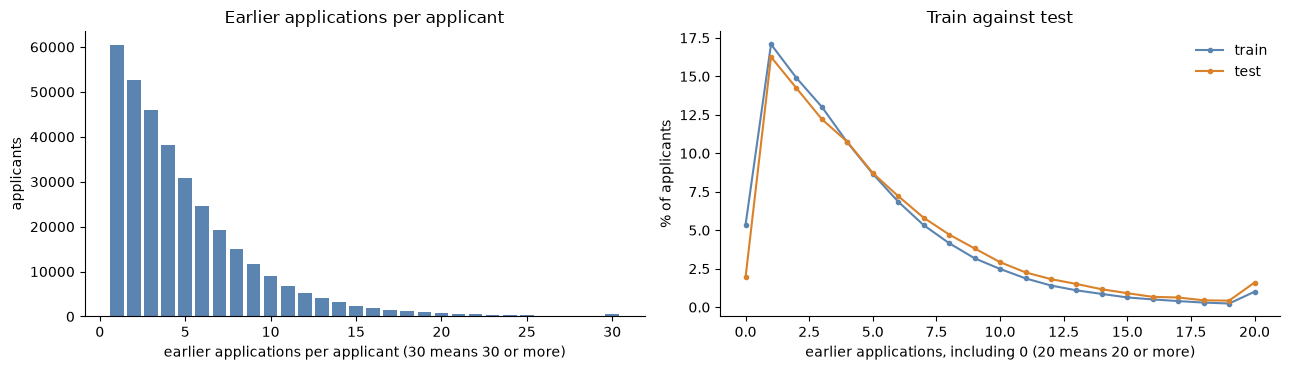

In [5]:
status = prev['NAME_CONTRACT_STATUS']
per_applicant = pd.DataFrame({'applications': n_prev})
for s in ['Approved', 'Refused', 'Canceled', 'Unused offer']:
    per_applicant[s.lower()] = (status == s).groupby(prev['SK_ID_CURR']).sum().reindex(n_prev.index).astype(int)
per_applicant['contract_types'] = prev.groupby('SK_ID_CURR')['NAME_CONTRACT_TYPE'].nunique()
per_applicant['years_since_first'] = -prev.groupby('SK_ID_CURR')['DAYS_DECISION'].min() / 365.25
per_applicant['years_since_last'] = -prev.groupby('SK_ID_CURR')['DAYS_DECISION'].max() / 365.25
known = per_applicant[per_applicant.index.isin(TRAIN_IDS) | per_applicant.index.isin(TEST_IDS)]
print('applicants with at least one earlier application (train and test):')
print(known.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T.round(2).to_string())

by_status = pd.DataFrame({'rows': status.value_counts(), 'pct_of_rows': status.value_counts(normalize=True) * 100,
                          'applicants_with_one_pct': {s: (known[s.lower()] > 0).mean() * 100 for s in ['Approved', 'Refused', 'Canceled', 'Unused offer']}})
for label in PARTS:
    by_status[label] = status[prev_part == label].value_counts(normalize=True) * 100
print('\nby outcome of the earlier application (shares in % of each part\'s rows):')
print(by_status.round(2).to_string())
by_type = pd.DataFrame({'rows': prev['NAME_CONTRACT_TYPE'].value_counts(), 'pct_of_rows': prev['NAME_CONTRACT_TYPE'].value_counts(normalize=True) * 100,
                        'approved_pct': (status == 'Approved').groupby(prev['NAME_CONTRACT_TYPE']).mean() * 100})
for label in PARTS:
    by_type[label] = prev.loc[prev_part == label, 'NAME_CONTRACT_TYPE'].value_counts(normalize=True) * 100
print('\nby contract type:')
print(by_type.round(2).sort_values('rows', ascending=False).to_string())
print(f"\napplicants with no approved earlier application: {(known['approved'] == 0).mean():.1%}; with at least one refusal: {(known['refused'] > 0).mean():.1%}")
print(f"earliest decision: {-prev['DAYS_DECISION'].min():,} days before the current application ({-prev['DAYS_DECISION'].min() / 365.25:.1f} years); latest: {-prev['DAYS_DECISION'].max()} days")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
shown = known['applications'].clip(upper=30)
axes[0].bar(*np.unique(shown, return_counts=True), color='#5b84b1')
axes[0].set_xlabel('earlier applications per applicant (30 means 30 or more)'); axes[0].set_ylabel('applicants'); axes[0].set_title('Earlier applications per applicant')
for label, ids, colour in [('train', TRAIN_IDS, '#5b84b1'), ('test', TEST_IDS, '#d9822b')]:
    share = n_prev.reindex(ids).fillna(0).clip(upper=20).value_counts(normalize=True).sort_index() * 100
    axes[1].plot(share.index, share.values, marker='o', markersize=3, label=label, color=colour)
axes[1].set_xlabel('earlier applications, including 0 (20 means 20 or more)'); axes[1].set_ylabel('% of applicants'); axes[1].set_title('Train against test'); axes[1].legend(frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

### 1.5 Links to the three tables beneath

Each of the three child tables records what happened to loans that followed an earlier application. They are large, so only their key columns are read here.

The question that matters most comes straight from the bureau work. `bureau_balance` looked like a rich source and turned out to exist for a third of bureau credits in train and nearly all of them in test. So for each child table: what share of earlier applications have rows in it, and is that share the same in train and test?

The supply test is the one used in notebook 03. For each applicant with an earlier application, take the share of their earlier applications that appear in the child table, and ask how well that one number tells a test applicant from a train applicant. An AUC of 0.50 means the table is supplied on the same terms in both files. `bureau_balance` scored 0.82.

In [6]:
CHILDREN = {'installments_payments': 'installments_payments.csv', 'POS_CASH_balance': 'POS_CASH_balance.csv', 'credit_card_balance': 'credit_card_balance.csv'}
approved = status == 'Approved'
train_with = TRAIN_IDS[TRAIN_IDS.isin(n_prev.index)]
test_with = TEST_IDS[TEST_IDS.isin(n_prev.index)]
order_ids = train_with.append(test_with)
from_test = np.r_[np.zeros(len(train_with)), np.ones(len(test_with))]

def supply_auc(row_flag, rows=None):
    # how well the per-applicant share of a yes-or-no fact tells test from train
    keys = prev['SK_ID_CURR'] if rows is None else prev.loc[rows, 'SK_ID_CURR']
    flag = row_flag if rows is None else row_flag[rows]
    share = flag.astype(float).groupby(keys).mean().reindex(order_ids)
    ok = share.notna().values
    auc = roc_auc_score(from_test[ok], share.values[ok])
    return max(auc, 1 - auc)

links, child_ids = {}, {}
for name, filename in CHILDREN.items():
    started = time.time()
    keys = pd.read_csv(f'{RAW}/{filename}', usecols=['SK_ID_PREV', 'SK_ID_CURR'])
    per_prev = keys.groupby('SK_ID_PREV').size()
    child_ids[name] = per_prev.index
    in_child = prev['SK_ID_PREV'].isin(per_prev.index)
    not_in_prev = ~per_prev.index.isin(prev['SK_ID_PREV'])
    mismatch = keys.drop_duplicates('SK_ID_PREV').merge(prev[['SK_ID_PREV', 'SK_ID_CURR']], on='SK_ID_PREV', suffixes=('_child', '_prev'))
    links[name] = {
        'rows': len(keys), 'loans_in_it': len(per_prev), 'rows_per_loan_median': per_prev.median(),
        'earlier_applications_in_it_pct': in_child.mean() * 100, 'approved_in_it_pct': in_child[approved].mean() * 100, 'not_approved_in_it_pct': in_child[~approved].mean() * 100,
        'its_loans_missing_from_previous_application_pct': not_in_prev.mean() * 100, 'rows_those_hold_pct': per_prev[not_in_prev].sum() / len(keys) * 100,
        'same_applicant_in_both_tables_pct': (mismatch['SK_ID_CURR_child'] == mismatch['SK_ID_CURR_prev']).mean() * 100,
        **{f'approved in it, {label} (%)': in_child[approved & (prev_part == label)].mean() * 100 for label in PARTS},
        'supply_auc_all_applications': supply_auc(in_child), 'supply_auc_approved_only': supply_auc(in_child, approved),
        'applicants_in_it_train_pct': TRAIN_IDS.isin(keys['SK_ID_CURR'].unique()).mean() * 100, 'applicants_in_it_test_pct': TEST_IDS.isin(keys['SK_ID_CURR'].unique()).mean() * 100,
        'read_seconds': time.time() - started,
    }
    del keys
links = pd.DataFrame(links)
print(links.to_string(float_format=lambda v: f'{v:,.2f}'))

in_any = prev['SK_ID_PREV'].isin(child_ids['installments_payments'].union(child_ids['POS_CASH_balance']).union(child_ids['credit_card_balance']))
print(f"\napproved earlier applications found in at least one child table: {in_any[approved].mean():.1%}; by part: "
      f"{ {label: round(float(in_any[approved & (prev_part == label)].mean() * 100), 1) for label in PARTS} }")
print(f"supply AUC for 'is in at least one child table', approved applications only: {supply_auc(in_any, approved):.3f}")
print('\nwhich child table an approved application appears in, by contract type (%):')
print(pd.DataFrame({name: prev['SK_ID_PREV'].isin(ids)[approved].groupby(prev.loc[approved, 'NAME_CONTRACT_TYPE']).mean() * 100 for name, ids in child_ids.items()}).round(1).to_string())
print('\nfor reference, bureau_balance scored 0.82 on the supply test and AMT_ANNUITY in bureau 0.78')

                                                 installments_payments  POS_CASH_balance  credit_card_balance
rows                                                     13,605,401.00     10,001,358.00         3,840,312.00
loans_in_it                                                 997,752.00        936,325.00           104,307.00
rows_per_loan_median                                             10.00             10.00                21.00
earlier_applications_in_it_pct                                   57.41             53.82                 5.56
approved_in_it_pct                                               92.49             86.70                 8.96
not_approved_in_it_pct                                            0.00              0.00                 0.00
its_loans_missing_from_previous_application_pct                   3.89              4.00                10.90
rows_those_hold_pct                                               9.19              3.41                28.20
same_appli


approved earlier applications found in at least one child table: 95.7%; by part: {'train: development': 95.7, 'train: holdout': 95.7, 'test': 95.6}


supply AUC for 'is in at least one child table', approved applications only: 0.503

which child table an approved application appears in, by contract type (%):


                    installments_payments  POS_CASH_balance  credit_card_balance
NAME_CONTRACT_TYPE                                                              
Cash loans                           92.3              92.3                  0.0
Consumer loans                       97.1              97.4                  0.0
Revolving loans                      63.9               0.0                 95.1

for reference, bureau_balance scored 0.82 on the supply test and AMT_ANNUITY in bureau 0.78


### Stage 1 findings

No target was used in this stage.

**The table**
- `previous_application.csv` has 1,670,214 rows and 37 columns: 2 keys, 16 text columns and 19 numeric ones.
- One row is one earlier application to Home Credit. `SK_ID_PREV` is unique, neither key has a missing value, and no row is fully duplicated. The file is not sorted.
- Much of the table is placeholder. `XNA` and `XAP` are the most common value in several text columns, a requested amount of zero appears on 23% of rows, and the date columns of the first three rows already show `365243`, the placeholder notebook 01 found in the application table. Two interest rate columns are 99.6% missing. Stage 3 sorts out what is information and what is filler.
- The dictionary describes 36 of the 37 columns, missing only `SK_ID_PREV`.

**Near-duplicates are common here, and mostly cancellations**
- 102,152 rows (6.1%) are identical to another row of the same applicant in everything except `SK_ID_PREV`. That is 26 times the share found in `bureau`.
- 84% of them are cancelled applications and 14% refused ones. 90% have a requested amount of zero. Only 267 are approved.
- These look like empty application records created and abandoned, sometimes many in a day: one applicant has 49 decisions on a single day, and 17% of applicant-days hold more than one decision. A count of "earlier applications" would be inflated by them. Stage 3 decides how to treat them.
- The table carries two flags of its own for repeated applications, `FLAG_LAST_APPL_PER_CONTRACT` and `NFLAG_LAST_APPL_IN_DAY`. Both mark under 1% of rows, far fewer than the near-duplicates, so they do not solve this.

**Link to the application table**

| | Applicants | With an earlier application | Mean if any |
|---|---:|---:|---:|
| Train, development | 246,008 | 94.6% | 4.86 |
| Train, holdout | 61,503 | 94.7% | 4.85 |
| Test | 48,744 | 98.1% | 5.37 |

- Every applicant in the table is in one of the two application files.
- Almost everyone has a history with Home Credit: 95% in train, against 86% who had a bureau record. Only 0.8% of train applicants have neither kind of history.
- **Coverage differs between train and test by 3.4 points** (94.6% and 98.1%), and test applicants have more earlier applications. This is larger than the 1.1-point gap seen for the bureau table. It is a difference in who the applicants are, since nothing suggests the table was supplied differently, but it means "has no earlier application" is three times as common in train as in test (5.4% against 1.9%). Stage 2 looks at it.

**What kind of history**
- 62% of earlier applications were approved, 19% cancelled, 17% refused and 2% approved but not taken up.
- 99.7% of applicants with any history have at least one approved application, and 35% have at least one refusal.
- The mix shifts in test: fewer approved (58.7% against 62.7%) and more cancelled (22.2% against 18.3%). Refusals are level.
- Cash loans and consumer loans are 45% and 44% of rows, revolving loans 12%. Consumer loans are approved 86% of the time, cash loans 42%.
- The median applicant has 4 earlier applications. One has 77.
- Like the bureau, the history stops at eight years (2,922 days). The most recent earlier application is typically 0.8 years before the current one.

**The three child tables are supplied on the same terms in train and test**

| | `installments_payments` | `POS_CASH_balance` | `credit_card_balance` |
|---|---:|---:|---:|
| Rows | 13.6 million | 10.0 million | 3.8 million |
| Approved applications found in it, development | 92.6% | 86.8% | 8.9% |
| Approved applications found in it, test | 91.8% | 85.8% | 9.7% |
| Supply test (0.50 = same in both files) | 0.51 | 0.52 | 0.52 |

- This is the result that matters most for the rest of the project. `bureau_balance` scored 0.82 on the same test and had to be left out. All three of these tables score 0.51 to 0.52. **Nothing here repeats the bureau problem**, so the month-by-month repayment record with Home Credit can be used.
- 95.7% of approved applications appear in at least one child table, the same share in every part of the data. No application that was not approved appears in any.
- The tables follow the kind of loan, as they should. Cash and consumer loans appear in `installments_payments` and `POS_CASH_balance`. Revolving loans appear in `credit_card_balance` (95%) and partly in `installments_payments` (64%).
- Where a loan is in both a child table and `previous_application`, the two always name the same applicant.
- **Some child rows have no parent.** 3.9% of the loans in `installments_payments`, 4.0% in `POS_CASH_balance` and 10.9% in `credit_card_balance` are not in `previous_application` at all. For credit cards those loans hold 28% of the table's rows. The child tables carry `SK_ID_CURR` themselves, so those rows can still be tied to an applicant, but nothing is known about the application that produced them. That is a question for the notebooks on those tables.

**Decisions**
- `SK_ID_PREV` and `SK_ID_CURR` are sound keys.
- Carried to stage 2: whether applicants with no earlier application differ in risk, and the 3.4-point coverage gap.
- Carried to stage 3: the near-duplicates, the placeholders (`XNA`, `XAP`, `365243`, zero amounts), and the shift in the mix of outcomes between train and test.
- For the later notebooks: all three child tables pass the supply test.

## Stage 2: Coverage and target

Do applicants with no earlier application default at a different rate? Does the amount and kind of history matter? And how does this history sit beside the bureau record?

**This is the first stage that uses `TARGET`.** Only the 246,008 development applicants are used for anything involving outcomes.

| Section | Question |
|---|---|
| 2.1 | Load the development outcomes |
| 2.2 | Default rate with and without an earlier application |
| 2.3 | Default rate by how many applications, and by how they ended |
| 2.4 | Default rate by how recent the last one was |
| 2.5 | The two kinds of history together |
| 2.6 | Coverage in train and test (no target) |

### 2.1 Development outcomes

In [7]:
dev = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=['TARGET', 'EXT_MEAN', 'NAME_CONTRACT_TYPE']).loc[DEV_IDS]
y_dev = dev['TARGET']
assert len(dev) == 246008 and int(y_dev.sum()) == 19860 and len(dev.index.intersection(HOLDOUT_IDS)) == 0 and len(dev.index.intersection(TEST_IDS)) == 0
BASE_RATE = float(y_dev.mean())
print(f"development applicants: {len(dev):,}, defaults {int(y_dev.sum()):,}, default rate {BASE_RATE:.2%}")
print('holdout outcomes loaded: none')

def rate_table(groups, y=None, order=None):
    # default rate per group with a 95% interval (Wilson), on development applicants
    y = y_dev if y is None else y
    g = pd.DataFrame({'group': np.asarray(groups), 'y': np.asarray(y)}).groupby('group', observed=True)['y'].agg(['size', 'sum', 'mean'])
    n, k, z = g['size'], g['sum'], 1.96
    centre = (k + z * z / 2) / (n + z * z)
    half = z * np.sqrt(g['mean'] * (1 - g['mean']) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    out = pd.DataFrame({'applicants': n, 'pct_of_applicants': n / n.sum() * 100, 'default_pct': g['mean'] * 100, 'low_pct': (centre - half) * 100, 'high_pct': (centre + half) * 100,
                        'ratio_to_overall': g['mean'] / np.asarray(y).mean()})
    return out if order is None else out.reindex([o for o in order if o in out.index])

def alone(values, mask=None):
    # AUC of a per-applicant quantity used alone as a score, on development applicants
    v = pd.Series(np.asarray(values, dtype=float), index=DEV_IDS)
    ok = v.notna().values if mask is None else (v.notna().values & mask)
    a = roc_auc_score(y_dev.values[ok], v.values[ok])
    return max(a, 1 - a), ('more risk' if a > 0.5 else 'less risk')

development applicants: 246,008, defaults 19,860, default rate 8.07%
holdout outcomes loaded: none


### 2.2 With and without an earlier application

In [8]:
dev_counts = per_applicant.reindex(DEV_IDS)
dev_n = dev_counts['applications'].fillna(0).astype(int)
dev_has = (dev_n > 0).values

table = rate_table(np.where(dev_has, 'has an earlier application', 'no earlier application'))
print(table.round(2).to_string())
a, b = table.loc['no earlier application'], table.loc['has an earlier application']
se = np.sqrt(a['default_pct'] / 100 * (1 - a['default_pct'] / 100) / a['applicants'] + b['default_pct'] / 100 * (1 - b['default_pct'] / 100) / b['applicants']) * 100
print(f"\ndifference (none minus some): {a['default_pct'] - b['default_pct']:+.2f} points, standard error {se:.2f}, z = {(a['default_pct'] - b['default_pct']) / se:.1f}")
print(f"'no earlier application' used alone as a score: AUC {alone((~dev_has).astype(float))[0]:.4f}")

# who are the applicants with no history at Home Credit?
profile = pd.DataFrame({'applicants': pd.Series(dev_has).map({True: 'has an earlier application', False: 'no earlier application'}).value_counts(),
                        'median EXT_MEAN': dev['EXT_MEAN'].groupby(np.where(dev_has, 'has an earlier application', 'no earlier application')).median(),
                        'revolving loan now (%)': (dev['NAME_CONTRACT_TYPE'] == 'Revolving loans').groupby(np.where(dev_has, 'has an earlier application', 'no earlier application')).mean() * 100})
print()
print(profile.round(3).to_string())

                            applicants  pct_of_applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                      
has an earlier application      232834              94.64         8.19     8.08      8.30              1.01
no earlier application           13174               5.36         6.00     5.61      6.42              0.74

difference (none minus some): -2.19 points, standard error 0.21, z = -10.2


'no earlier application' used alone as a score: AUC 0.5075



                            applicants  median EXT_MEAN  revolving loan now (%)
has an earlier application      232834            0.523                   9.068
no earlier application           13174            0.547                  17.717


### 2.3 By how many, and by how they ended

Stage 1 found that many rows are empty cancelled records, so a raw count of applications is suspect. The counts are shown by outcome: approved, refused, cancelled. Applicants with no earlier application are a group of their own.


all earlier applications:
                        applicants  pct_of_applicants  default_pct  low_pct  high_pct
group                                                                                
no earlier application       13174               5.36         6.00     5.61      6.42
1                            41947              17.05         8.27     8.01      8.53
2                            36661              14.90         7.85     7.58      8.13
3 to 4                       58468              23.77         7.72     7.51      7.94
5 to 7                       51143              20.79         8.05     7.82      8.29
8 to 12                      32237              13.10         8.73     8.43      9.04
over 12                      12378               5.03        10.34     9.82     10.89

approved:
                        applicants  pct_of_applicants  default_pct  low_pct  high_pct
group                                                                                
no earlier appli


cancelled:
                        applicants  pct_of_applicants  default_pct  low_pct  high_pct
group                                                                                
no earlier application       13174               5.36         6.00     5.61      6.42
0                           144360              58.68         7.93     7.79      8.07
1                            39969              16.25         8.13     7.87      8.40
2                            20827               8.47         8.71     8.33      9.10
3 to 4                       18004               7.32         9.04     8.63      9.47
5 or more                     9674               3.93         9.67     9.09     10.27



each quantity used alone as a score:
                                           auc_among_applicants_with_history  direction
number of earlier applications                                      0.511978  more risk
number approved                                                     0.533811  less risk
number refused                                                       0.55654  more risk
number cancelled                                                    0.513603  more risk
share refused                                                       0.560649  more risk
share approved                                                      0.559183  less risk
refused among decided (approved + refused)                          0.562193  more risk


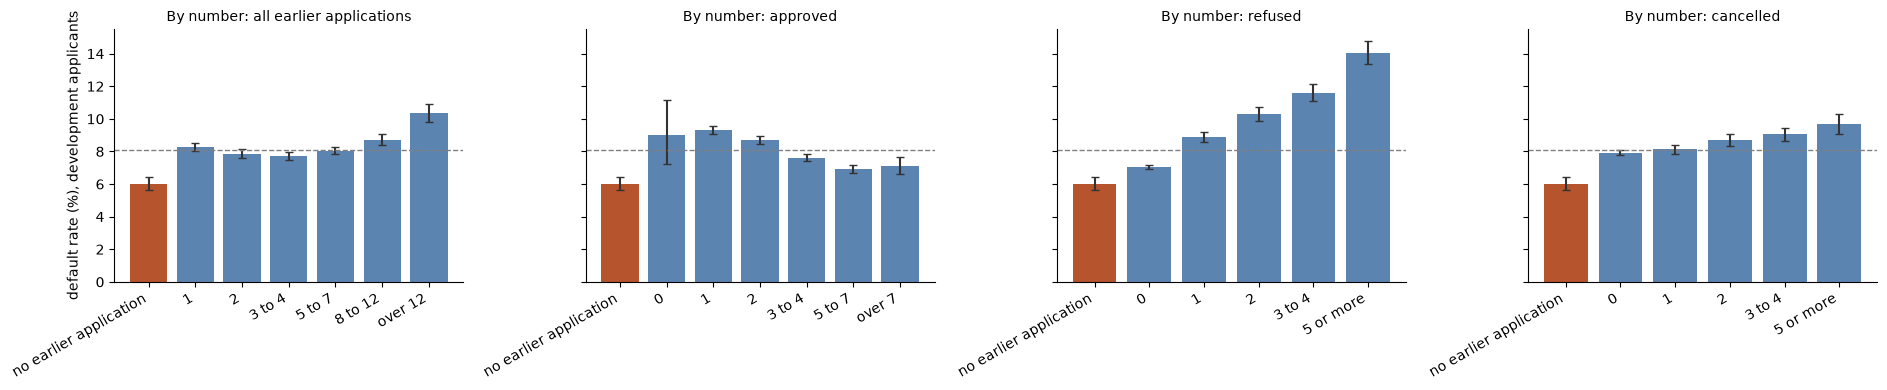

In [9]:
def bucket(counts, edges, labels):
    out = pd.cut(counts.fillna(0), edges, labels=labels).astype(object)
    out[~dev_has] = 'no earlier application'
    return out.values

views = {
    'all earlier applications': (bucket(dev_counts['applications'], [0, 1, 2, 4, 7, 12, 500], ['1', '2', '3 to 4', '5 to 7', '8 to 12', 'over 12']), ['no earlier application', '1', '2', '3 to 4', '5 to 7', '8 to 12', 'over 12']),
    'approved': (bucket(dev_counts['approved'], [-1, 0, 1, 2, 4, 7, 500], ['0', '1', '2', '3 to 4', '5 to 7', 'over 7']), ['no earlier application', '0', '1', '2', '3 to 4', '5 to 7', 'over 7']),
    'refused': (bucket(dev_counts['refused'], [-1, 0, 1, 2, 4, 500], ['0', '1', '2', '3 to 4', '5 or more']), ['no earlier application', '0', '1', '2', '3 to 4', '5 or more']),
    'cancelled': (bucket(dev_counts['canceled'], [-1, 0, 1, 2, 4, 500], ['0', '1', '2', '3 to 4', '5 or more']), ['no earlier application', '0', '1', '2', '3 to 4', '5 or more']),
}
tables = {}
for label, (groups, order) in views.items():
    tables[label] = rate_table(groups, order=order)
    print(f"\n{label}:")
    print(tables[label][['applicants', 'pct_of_applicants', 'default_pct', 'low_pct', 'high_pct']].round(2).to_string())

share_refused = dev_counts['refused'] / dev_counts['applications']
share_approved = dev_counts['approved'] / dev_counts['applications']
signal = {}
for label, values in {'number of earlier applications': dev_counts['applications'], 'number approved': dev_counts['approved'], 'number refused': dev_counts['refused'],
                      'number cancelled': dev_counts['canceled'], 'share refused': share_refused, 'share approved': share_approved,
                      'refused among decided (approved + refused)': dev_counts['refused'] / (dev_counts['approved'] + dev_counts['refused']).where(lambda s: s > 0)}.items():
    auc, direction = alone(values, dev_has)
    signal[label] = {'auc_among_applicants_with_history': auc, 'direction': direction}
print('\neach quantity used alone as a score:')
print(pd.DataFrame(signal).T.to_string())

fig, axes = plt.subplots(1, 4, figsize=(19, 4), sharey=True)
for ax, (label, t) in zip(axes, tables.items()):
    x = np.arange(len(t))
    ax.bar(x, t['default_pct'], color=['#b5542d' if i == 'no earlier application' else '#5b84b1' for i in t.index],
           yerr=[t['default_pct'] - t['low_pct'], t['high_pct'] - t['default_pct']], capsize=3, ecolor='#333333')
    ax.axhline(BASE_RATE * 100, color='grey', linestyle='--', linewidth=1)
    ax.set_xticks(x); ax.set_xticklabels(t.index, rotation=30, ha='right'); ax.set_title(f'By number: {label}', fontsize=10)
axes[0].set_ylabel('default rate (%), development applicants')
sns.despine(); plt.tight_layout(); plt.show()

### 2.4 By how recent

The bureau work found that recent borrowing was the strongest single signal, and that the external scores already held most of it. Here the equivalent is how long ago the applicant last applied to Home Credit, and what the outcome of that most recent application was.

In [10]:
years_last = dev_counts['years_since_last']
recency = pd.cut(years_last, [-0.01, 0.25, 0.5, 1, 2, 4, 8.01], labels=['last 3 months', '3 to 6 months', '6 to 12 months', '1 to 2 years', '2 to 4 years', '4 to 8 years']).astype(object)
recency[~dev_has] = 'no earlier application'
print('by time since the most recent earlier application:')
print(rate_table(recency.values, order=['last 3 months', '3 to 6 months', '6 to 12 months', '1 to 2 years', '2 to 4 years', '4 to 8 years', 'no earlier application'])[
    ['applicants', 'pct_of_applicants', 'default_pct', 'low_pct', 'high_pct']].round(2).to_string())

# the outcome of the single most recent earlier application
latest = prev.sort_values(['SK_ID_CURR', 'DAYS_DECISION', 'SK_ID_PREV']).groupby('SK_ID_CURR').tail(1).set_index('SK_ID_CURR')
last_status = latest['NAME_CONTRACT_STATUS'].reindex(DEV_IDS).fillna('no earlier application')
print('\nby the outcome of the most recent earlier application:')
print(rate_table(last_status.values, order=['Approved', 'Unused offer', 'Canceled', 'Refused', 'no earlier application'])[['applicants', 'pct_of_applicants', 'default_pct', 'low_pct', 'high_pct']].round(2).to_string())

recent_refusal = ((status == 'Refused') & (prev['DAYS_DECISION'] >= -365)).groupby(prev['SK_ID_CURR']).sum().reindex(DEV_IDS).fillna(0)
print('\nby refusals in the year before the current application:')
print(rate_table(np.where(~dev_has, 'no earlier application', np.where(recent_refusal == 0, 'none', np.where(recent_refusal == 1, 'one', 'two or more'))),
                 order=['none', 'one', 'two or more', 'no earlier application'])[['applicants', 'pct_of_applicants', 'default_pct', 'low_pct', 'high_pct']].round(2).to_string())
print('\neach used alone as a score, among applicants with history:')
print(pd.DataFrame({'years since the most recent earlier application': alone(years_last, dev_has), 'years since the first': alone(dev_counts['years_since_first'], dev_has),
                    'refusals in the last year': alone(recent_refusal, dev_has)}, index=['auc', 'direction']).T.to_string())

by time since the most recent earlier application:
                        applicants  pct_of_applicants  default_pct  low_pct  high_pct
group                                                                                
last 3 months                36610              14.88         8.91     8.62      9.20
3 to 6 months                36513              14.84         8.88     8.60      9.18
6 to 12 months               62080              25.23         8.56     8.34      8.78
1 to 2 years                 54257              22.05         7.50     7.28      7.72
2 to 4 years                 27332              11.11         7.23     6.92      7.54
4 to 8 years                 16042               6.52         7.53     7.13      7.95
no earlier application       13174               5.36         6.00     5.61      6.42



by the outcome of the most recent earlier application:
                        applicants  pct_of_applicants  default_pct  low_pct  high_pct
group                                                                                
Approved                    142159              57.79         7.38     7.25      7.52
Unused offer                  4468               1.82         8.71     7.91      9.57
Canceled                     60108              24.43         8.19     7.97      8.41
Refused                      26099              10.61        12.51    12.11     12.91
no earlier application       13174               5.36         6.00     5.61      6.42



by refusals in the year before the current application:
                        applicants  pct_of_applicants  default_pct  low_pct  high_pct
group                                                                                
none                        194951              79.25         7.45     7.33      7.57
one                          19931               8.10        11.11    10.68     11.55
two or more                  17952               7.30        13.00    12.51     13.50
no earlier application       13174               5.36         6.00     5.61      6.42

each used alone as a score, among applicants with history:


                                                      auc  direction
years since the most recent earlier application  0.525391  less risk
years since the first                            0.554738  less risk
refusals in the last year                        0.542285  more risk


### 2.5 The two kinds of history together

An applicant can have a record at other lenders (the bureau), a record with Home Credit (this table), both, or neither.

In [11]:
has_bureau = (pd.read_parquet(f'{PROCESSED}/bureau_train_features.parquet', columns=['BUREAU_N_CREDITS'])['BUREAU_N_CREDITS'].reindex(DEV_IDS) > 0).values
kind = np.select([has_bureau & dev_has, has_bureau & ~dev_has, ~has_bureau & dev_has], ['both', 'bureau record only', 'Home Credit history only'], 'neither')
print(rate_table(kind, order=['both', 'bureau record only', 'Home Credit history only', 'neither']).round(2).to_string())

refused_any = (dev_counts['refused'].fillna(0) > 0).values
cross = rate_table(np.where(has_bureau, 'bureau record', 'no bureau record') + np.where(~dev_has, ', no earlier application', np.where(refused_any, ', refused before', ', never refused')))
print('\nby bureau record and whether Home Credit has refused the applicant before:')
print(cross[['applicants', 'pct_of_applicants', 'default_pct', 'low_pct', 'high_pct']].round(2).to_string())

# is a refusal already known to the application model's strongest feature?
with_score = dev['EXT_MEAN'].notna().values & dev_has
quintile = pd.qcut(dev.loc[with_score, 'EXT_MEAN'], 5, labels=['lowest fifth (riskiest)', 'second', 'third', 'fourth', 'highest fifth (safest)'])
inside = (pd.DataFrame({'q': quintile.values, 'refused': np.where(refused_any[with_score], 'refused before', 'never refused'), 'y': y_dev.values[with_score]}).groupby(['q', 'refused'], observed=True)['y'].mean().unstack() * 100)
inside['ratio'] = inside['refused before'] / inside['never refused']
print('\ndefault rate (%) by fifth of EXT_MEAN and whether the applicant was refused before:')
print(inside.round(2).to_string())
overall_ratio = y_dev.values[dev_has & refused_any].mean() / y_dev.values[dev_has & ~refused_any].mean()
print(f"\nrisk ratio of a past refusal: {overall_ratio:.2f} overall; {inside['ratio'].mean():.2f} on average inside the fifths of EXT_MEAN")
print(f"median EXT_MEAN: refused before {dev.loc[dev_has & refused_any, 'EXT_MEAN'].median():.3f}, never refused {dev.loc[dev_has & ~refused_any, 'EXT_MEAN'].median():.3f}")

                          applicants  pct_of_applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                    
both                          199574              81.13         7.84     7.72      7.96              0.97
bureau record only             11190               4.55         5.77     5.36      6.22              0.72
Home Credit history only       33260              13.52        10.29     9.97     10.62              1.27
neither                         1984               0.81         7.31     6.24      8.54              0.91

by bureau record and whether Home Credit has refused the applicant before:
                                          applicants  pct_of_applicants  default_pct  low_pct  high_pct
group                                                                                                  
bureau record, never refused                  128581              52.27         


default rate (%) by fifth of EXT_MEAN and whether the applicant was refused before:
refused                  never refused  refused before  ratio
q                                                            
lowest fifth (riskiest)          16.75           21.76   1.30
second                            8.62           10.85   1.26
third                             5.84            6.70   1.15
fourth                            3.60            4.70   1.30
highest fifth (safest)            2.29            3.32   1.45

risk ratio of a past refusal: 1.46 overall; 1.29 on average inside the fifths of EXT_MEAN
median EXT_MEAN: refused before 0.498, never refused 0.537


### 2.6 Coverage in train and test

No target is used here. Stage 1 found that 5.4% of train applicants and 1.9% of test applicants have no earlier application, and that the mix of outcomes differs. This section measures how far the per-applicant counts move.

In [12]:
def psi(a, b, edges):
    pa = pd.cut(a, edges).value_counts(normalize=True).sort_index() + 1e-4
    pb = pd.cut(b, edges).value_counts(normalize=True).sort_index() + 1e-4
    return float(((pb - pa) * np.log(pb / pa)).sum())

edges = [-1, 0, 1, 2, 4, 7, 12, 500]
get = lambda column, ids: per_applicant[column].reindex(ids).fillna(0)
shift = {}
for label, column in {'earlier applications': 'applications', 'approved': 'approved', 'refused': 'refused', 'cancelled': 'canceled'}.items():
    both_ids = TRAIN_IDS.append(TEST_IDS)
    auc = roc_auc_score(np.r_[np.zeros(len(TRAIN_IDS)), np.ones(len(TEST_IDS))], get(column, both_ids).values)
    shift[label] = {'mean_development': get(column, DEV_IDS).mean(), 'mean_holdout': get(column, HOLDOUT_IDS).mean(), 'mean_test': get(column, TEST_IDS).mean(),
                    'none_train_pct': (get(column, TRAIN_IDS) == 0).mean() * 100, 'none_test_pct': (get(column, TEST_IDS) == 0).mean() * 100,
                    'psi_development_vs_holdout': psi(get(column, DEV_IDS), get(column, HOLDOUT_IDS), edges), 'psi_development_vs_test': psi(get(column, DEV_IDS), get(column, TEST_IDS), edges),
                    'shift_auc_train_vs_test': max(auc, 1 - auc)}
print(pd.DataFrame(shift).T.round(4).to_string())

dist = pd.DataFrame({label: pd.cut(n_prev.reindex(ids).fillna(0), edges, labels=['0 (none)', '1', '2', '3 to 4', '5 to 7', '8 to 12', 'over 12']).value_counts(normalize=True).sort_index() * 100 for label, ids in PARTS.items()})
print('\n% of applicants by number of earlier applications:')
print(dist.round(2).to_string())

last_all = -prev.groupby('SK_ID_CURR')['DAYS_DECISION'].max() / 365.25
print(f"\nmedian years since the most recent earlier application: development {last_all.reindex(DEV_IDS).median():.2f}, holdout {last_all.reindex(HOLDOUT_IDS).median():.2f}, test {last_all.reindex(TEST_IDS).median():.2f}")
recent = (prev['DAYS_DECISION'] >= -365).groupby(prev['SK_ID_CURR']).sum()
print(f"earlier applications in the last year, per applicant: development {recent.reindex(DEV_IDS).fillna(0).mean():.2f}, holdout {recent.reindex(HOLDOUT_IDS).fillna(0).mean():.2f}, test {recent.reindex(TEST_IDS).fillna(0).mean():.2f}")
cancelled_recent = ((status == 'Canceled') & (prev['DAYS_DECISION'] >= -365)).groupby(prev['SK_ID_CURR']).sum()
print(f"of which cancelled: development {cancelled_recent.reindex(DEV_IDS).fillna(0).mean():.2f}, holdout {cancelled_recent.reindex(HOLDOUT_IDS).fillna(0).mean():.2f}, test {cancelled_recent.reindex(TEST_IDS).fillna(0).mean():.2f}")

                      mean_development  mean_holdout  mean_test  none_train_pct  none_test_pct  psi_development_vs_holdout  psi_development_vs_test  shift_auc_train_vs_test
earlier applications            4.5988        4.5910     5.2625          5.3507         1.9366                      0.0001                   0.0489                   0.5440
approved                        2.8822        2.8788     3.0913          5.6733         2.2793                      0.0001                   0.0349                   0.5296
refused                         0.7997        0.7911     0.9291         67.3852        63.1073                      0.0001                   0.0084                   0.5226
cancelled                       0.8431        0.8461     1.1669         63.9928        54.9319                      0.0000                   0.0407                   0.5506

% of applicants by number of earlier applications:
          train: development  train: holdout   test
0 (none)                5.36   

earlier applications in the last year, per applicant: development 1.63, holdout 1.62, test 1.50
of which cancelled: development 0.74, holdout 0.73, test 0.68


### Stage 2 findings

All figures involving default are from the 246,008 development applicants. The holdout's outcomes were not loaded.

**Having no history with Home Credit is a sign of lower risk, the opposite of the bureau**

| | Applicants | Default rate | 95% interval |
|---|---:|---:|---:|
| Has an earlier application | 232,834 (94.6%) | 8.19% | 8.08% to 8.30% |
| No earlier application | 13,174 (5.4%) | 6.00% | 5.61% to 6.42% |

- Applicants new to Home Credit default less, by 2.2 points and 10 standard errors. With the bureau it was the other way round: no record meant more risk (10.1% against 7.7%).
- The two are different facts. No bureau record means nobody has lent to this person before. No Home Credit history means this lender has not, and such applicants have higher external scores and are twice as likely to be applying for a revolving loan.
- Putting the two together separates them clearly:

| History | Share | Default rate |
|---|---:|---:|
| Bureau record only | 4.5% | 5.8% |
| Neither | 0.8% | 7.3% |
| Both | 81.1% | 7.8% |
| Home Credit history only | 13.5% | 10.3% |

- The riskiest group is applicants who have borrowed from Home Credit before and have no record anywhere else. The safest is those with a record elsewhere and new to Home Credit.

**Refusals are the clearest signal**

| Earlier refusals | Share of applicants | Default rate |
|---|---:|---:|
| None | 62.0% | 7.1% |
| 1 | 15.2% | 8.9% |
| 2 | 7.4% | 10.3% |
| 3 to 4 | 6.1% | 11.6% |
| 5 or more | 4.0% | 14.1% |

- The default rate doubles from no refusals to five or more, in even steps. Home Credit's earlier judgement of an applicant carries over to the next loan.
- The outcome of the most recent earlier application says the same: 7.4% if it was approved, 12.5% if it was refused. Two or more refusals in the last year go with 13.0%.
- The share of applications refused scores 0.561 alone, a little above the count (0.557).
- **It is partly new information.** A past refusal multiplies the risk by 1.46 overall and by 1.29 among applicants with the same external score. About two thirds of the excess risk remains once `EXT_MEAN` is held fixed. For the bureau's recency features only about a fifth remained.

**Approved applications count the other way, and the total hides both**
- More approved applications means less risk: 9.3% with one, 6.9% with five to seven. An approved loan that went on to be repaid is evidence of repayment.
- The total number of applications scores 0.512, because approvals and refusals pull in opposite directions. This is the same pattern as the bureau's live and finished credits.
- Cancelled applications carry little (7.9% with none, 9.7% with five or more, AUC 0.514). Stage 1 found that many of them are empty duplicate records.

**Recency is weaker here than in the bureau**
- 8.9% for applicants whose last application was within three months, 7.2% to 7.5% for two years or more. In the bureau the equivalent range was 13.4% to 5.9%.
- Time since the first application is more informative (0.555) than time since the last (0.525). A long relationship with the lender goes with lower risk.

**Train and test differ more than they did for the bureau**

| | Development | Test | PSI | Shift AUC |
|---|---:|---:|---:|---:|
| Earlier applications, mean | 4.60 | 5.26 | 0.049 | 0.544 |
| Approved, mean | 2.88 | 3.09 | 0.035 | 0.530 |
| Refused, mean | 0.80 | 0.93 | 0.008 | 0.523 |
| Cancelled, mean | 0.84 | 1.17 | 0.041 | 0.551 |

- No PSI reaches 0.10, but the cancelled count crosses the 0.55 mark on the shift test, and the total count is close. For the bureau the largest count shift was 0.524.
- Test applicants have more history of every kind, and noticeably more cancelled applications (1.17 against 0.84).
- Development and holdout are indistinguishable, as a random split should be.
- The refusal counts, which carry the most signal, shift least (0.523). The cancelled counts, which carry the least, shift most. That is a convenient arrangement, and stage 8 will hold each feature to the same rules as before.

**Leakage check for this stage**
- Outcomes were read for development applicants only, with an assertion that no holdout or test applicant is among them.
- Nothing was fitted. Every figure is a count, a rate, or the AUC of a raw count.
- One point to carry to stage 4: a refusal is only safe to use if it is the outcome of an *earlier* application. The most recent earlier application is typically ten months before the current one, but some are days before. Stage 4 checks that none is the current application itself.

**Decisions**
- Applicants with no earlier application get a count of 0 and missing values elsewhere, as for the bureau.
- Counts and shares are built by outcome. The total alone is not worth keeping.
- Refusals get their own family of features, including recency and the stated reason.
- Cancelled applications are treated with suspicion until stage 3 has dealt with the duplicate records.

## Stage 3: Column-by-column audit

What is wrong with each column, and what should be done about it before any feature is built?

As in notebook 03, every column is asked two questions: is the value believable, and is the column supplied on the same terms in train and test? This table needs a third. Many columns only apply to some kinds of row. A refused application has no payment dates, and a cash loan has no goods category. So a blank or an `XNA` may be a gap in the data, or may simply say "not applicable". The two must be told apart, because a feature built on "this is missing" means something quite different in each case.

**No target is used in this stage.**

| Section | What it covers |
|---|---|
| 3.1 | The 16 text columns, and their placeholders |
| 3.2 | Missing values: gaps, or not applicable? |
| 3.3 | Is each column supplied equally in train and test? |
| 3.4 | Dates, and the `365243` placeholder |
| 3.5 | Amounts, rates and terms |
| 3.6 | Contradictions between columns, and the near-duplicates |
| 3.7 | The cleaning rules, as one function |

### 3.1 Text columns and their placeholders

`XNA` and `XAP` appear throughout. The dictionary does not define them, but their use suggests "not available" and "not applicable". For each text column: how many values it has, how much of it is placeholder, and whether the placeholder follows the outcome of the application.

In [13]:
TEXT = [c for c in prev.columns if not pd.api.types.is_numeric_dtype(prev[c])]
NUMERIC = [c for c in prev.columns if c not in TEXT and c not in ('SK_ID_PREV', 'SK_ID_CURR')]
PLACEHOLDERS = ['XNA', 'XAP']
STATUSES = ['Approved', 'Refused', 'Canceled', 'Unused offer']

rows = {}
for c in TEXT:
    is_placeholder = prev[c].isin(PLACEHOLDERS)
    counts = prev[c].value_counts(dropna=True)
    rows[c] = {'values': prev[c].nunique(), 'blank_pct': prev[c].isna().mean() * 100, 'placeholder_pct': is_placeholder.mean() * 100,
               **{f'placeholder_if_{s.lower().replace(" ", "_")}_pct': is_placeholder[status == s].mean() * 100 for s in STATUSES},
               'values_under_0.5pct_of_rows': int((counts / len(prev) < 0.005).sum()), 'most_common_real_value': counts[~counts.index.isin(PLACEHOLDERS)].index[0]}
text_overview = pd.DataFrame(rows).T
print(text_overview.to_string(float_format=lambda v: f'{v:.1f}'))

for c in ['NAME_CONTRACT_STATUS', 'CODE_REJECT_REASON', 'NAME_CLIENT_TYPE', 'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'NAME_YIELD_GROUP', 'NAME_PAYMENT_TYPE', 'CHANNEL_TYPE']:
    t = pd.crosstab(prev[c], prev_part, normalize='columns')[list(PARTS)] * 100
    t.insert(0, 'rows', prev[c].value_counts())
    t['test_to_development'] = t['test'] / t['train: development']
    print(f"\n{c} (% of each part's rows):")
    print(t.sort_values('rows', ascending=False).to_string(float_format=lambda v: f'{v:,.2f}'))

print('\nCODE_REJECT_REASON by outcome (rows):')
print(pd.crosstab(prev['CODE_REJECT_REASON'], status).to_string())
print('\ncolumns with many values:', {c: int(prev[c].nunique()) for c in TEXT if prev[c].nunique() > 10})

                            values blank_pct placeholder_pct placeholder_if_approved_pct placeholder_if_refused_pct placeholder_if_canceled_pct placeholder_if_unused_offer_pct values_under_0.5pct_of_rows   most_common_real_value
NAME_CONTRACT_TYPE               4       0.0             0.0                         0.0                        0.0                         0.1                             0.0                           1               Cash loans
WEEKDAY_APPR_PROCESS_START       7       0.0             0.0                         0.0                        0.0                         0.0                             0.0                           0                  TUESDAY
FLAG_LAST_APPL_PER_CONTRACT      2       0.0             0.0                         0.0                        0.0                         0.0                             0.0                           0                        Y
NAME_CASH_LOAN_PURPOSE          25       0.0            95.8                        


CODE_REJECT_REASON (% of each part's rows):
SK_ID_CURR             rows  train: development  train: holdout  test  test_to_development
CODE_REJECT_REASON                                                                        
XAP                 1353093               81.00           81.13 80.92                 1.00
HC                   175231               10.35           10.24 11.40                 1.10
LIMIT                 55680                3.39            3.33  3.08                 0.91
SCO                   37467                2.31            2.29  1.88                 0.81
CLIENT                26436                1.61            1.63  1.43                 0.89
SCOFR                 12811                0.77            0.78  0.75                 0.99
XNA                    5244                0.31            0.32  0.34                 1.10
VERIF                  3535                0.22            0.23  0.18                 0.82
SYSTEM                  717                0.


NAME_CLIENT_TYPE (% of each part's rows):
SK_ID_CURR           rows  train: development  train: holdout  test  test_to_development
NAME_CLIENT_TYPE                                                                        
Repeater          1231261               73.43           73.30 75.47                 1.03
New                301363               18.34           18.42 16.30                 0.89
Refreshed          135649                8.12            8.17  8.07                 0.99
XNA                  1941                0.11            0.11  0.16                 1.42



NAME_PORTFOLIO (% of each part's rows):
SK_ID_CURR        rows  train: development  train: holdout  test  test_to_development
NAME_PORTFOLIO                                                                       
POS             691011               41.95           41.73 38.42                 0.92
Cash            461563               27.67           27.83 27.25                 0.98
XNA             372230               21.72           21.79 25.35                 1.17
Cards           144985                8.63            8.62  8.97                 1.04
Cars               425                0.03            0.03  0.02                 0.66



NAME_PRODUCT_TYPE (% of each part's rows):
SK_ID_CURR            rows  train: development  train: holdout  test  test_to_development
NAME_PRODUCT_TYPE                                                                        
XNA                1063666               63.70           63.54 63.78                 1.00
x-sell              456287               27.23           27.40 27.64                 1.02
walk-in             150261                9.08            9.05  8.58                 0.95



NAME_YIELD_GROUP (% of each part's rows):
SK_ID_CURR          rows  train: development  train: holdout  test  test_to_development
NAME_YIELD_GROUP                                                                       
XNA               517215               30.35           30.41 34.31                 1.13
middle            385532               22.99           22.98 23.61                 1.03
high              353331               21.67           21.56 18.43                 0.85
low_normal        322095               19.43           19.51 18.40                 0.95
low_action         92041                5.56            5.54  5.24                 0.94



NAME_PAYMENT_TYPE (% of each part's rows):
SK_ID_CURR                                    rows  train: development  train: holdout  test  test_to_development
NAME_PAYMENT_TYPE                                                                                                
Cash through the bank                      1033552               62.42           62.50 58.81                 0.94
XNA                                         627384               37.01           36.91 40.71                 1.10
Non-cash from your account                    8193                0.50            0.52  0.43                 0.85
Cashless from the account of the employer     1085                0.06            0.08  0.06                 0.89



CHANNEL_TYPE (% of each part's rows):
SK_ID_CURR                    rows  train: development  train: holdout  test  test_to_development
CHANNEL_TYPE                                                                                     
Credit and cash offices     719968               42.41           42.70 46.64                 1.10
Country-wide                494690               29.98           29.72 27.92                 0.93
Stone                       212083               12.96           13.07 11.14                 0.86
Regional / Local            108528                6.56            6.46  6.26                 0.95
Contact center               71297                4.17            4.13  4.84                 1.16
AP+ (Cash loan)              57046                3.51            3.50  2.89                 0.82
Channel of corporate sales    6150                0.38            0.39  0.29                 0.78
Car dealer                     452                0.03            0.03  0.02   


columns with many values: {'NAME_CASH_LOAN_PURPOSE': 25, 'NAME_GOODS_CATEGORY': 28, 'NAME_SELLER_INDUSTRY': 11, 'PRODUCT_COMBINATION': 17}


### 3.2 Missing values: gaps, or not applicable?

For each column with blanks, the share blank is shown by the outcome of the application and by the type of contract. A column that is blank for every refused application and filled for every approved one is not missing data. It is the outcome restated.

In [14]:
has_missing = [c for c in prev.columns if prev[c].isna().any()]
ctype = prev['NAME_CONTRACT_TYPE']
missing = pd.DataFrame({'missing_pct': prev[has_missing].isna().mean() * 100})
for s in STATUSES:
    missing[s] = prev.loc[status == s, has_missing].isna().mean() * 100
for t in ['Cash loans', 'Consumer loans', 'Revolving loans']:
    missing[f'approved {t.lower()}'] = prev.loc[(status == 'Approved') & (ctype == t), has_missing].isna().mean() * 100
for label in PARTS:
    missing[label] = prev.loc[prev_part == label, has_missing].isna().mean() * 100
print('share blank (%), by outcome, by contract type among approved applications, and by part of the data:')
print(missing.sort_values('missing_pct', ascending=False).to_string(float_format=lambda v: f'{v:.1f}'))

# among approved applications only, where the columns are supposed to be filled
approved_missing = prev.loc[status == 'Approved', has_missing].isna().mean() * 100
print('\namong approved applications, columns still blank for more than 1%:')
print(approved_missing[approved_missing > 1].sort_values(ascending=False).round(1).to_string())
together = prev.loc[status == 'Approved', ['DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION', 'NFLAG_INSURED_ON_APPROVAL']].isna()
print(f"\nthe five loan dates and the insurance flag are blank together or filled together for {(together.all(axis=1) | ~together.any(axis=1)).mean():.2%} of approved applications")
print(f"approved applications with all six blank: {together.all(axis=1).mean():.2%}; of other applications: {prev.loc[status != 'Approved', ['DAYS_FIRST_DUE']].isna().mean().iloc[0]:.2%}")

share blank (%), by outcome, by contract type among approved applications, and by part of the data:
                           missing_pct  Approved  Refused  Canceled  Unused offer  approved cash loans  approved consumer loans  approved revolving loans  train: development  train: holdout  test
RATE_INTEREST_PRIVILEGED          99.6      99.4    100.0     100.0         100.0                100.0                     99.1                     100.0                99.7            99.7  99.5
RATE_INTEREST_PRIMARY             99.6      99.4    100.0     100.0         100.0                100.0                     99.1                     100.0                99.7            99.7  99.5
AMT_DOWN_PAYMENT                  53.6      36.1     69.9      99.8           9.2                 88.8                      0.0                      99.0                53.0            53.1  57.0
RATE_DOWN_PAYMENT                 53.6      36.1     69.9      99.8           9.2                 88.8              


the five loan dates and the insurance flag are blank together or filled together for 100.00% of approved applications
approved applications with all six blank: 3.82%; of other applications: 100.00%


### 3.3 Is each column supplied equally in train and test?

The supply test from notebook 03. For each applicant with an earlier application, take the share of their applications for which something is true (a value is present, is a placeholder, is of a given kind), and ask how well that number tells a test applicant from a train applicant. 0.50 means the same in both files. `bureau_balance` scored 0.82 and `AMT_ANNUITY` 0.78, and both were removed.

Stage 1 found that the mix of outcomes differs between the files, with more cancelled applications in test. Since many columns are blank for cancelled applications, that alone would make them look differently supplied. So each test is run twice: on all applications, and on approved applications only, where the columns are meant to be filled.

In [15]:
flags = {f'{c}: present': prev[c].notna() for c in has_missing}
flags.update({f'{c}: placeholder': prev[c].isin(PLACEHOLDERS) for c in TEXT if prev[c].isin(PLACEHOLDERS).any()})
flags.update({f'{c}: is 365243': prev[c] == 365243 for c in NUMERIC if (prev[c] == 365243).any()})
flags.update({f'{c}: is zero': prev[c] == 0 for c in ['AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_ANNUITY', 'CNT_PAYMENT', 'AMT_GOODS_PRICE']})
flags.update({f'outcome: {s}': status == s for s in STATUSES})
flags.update({f'contract type: {t}': ctype == t for t in ['Cash loans', 'Consumer loans', 'Revolving loans']})
flags.update({f'client type: {t}': prev['NAME_CLIENT_TYPE'] == t for t in ['Repeater', 'New', 'Refreshed']})
flags.update({f'reject reason: {t}': prev['CODE_REJECT_REASON'] == t for t in ['HC', 'LIMIT', 'SCO', 'SCOFR', 'CLIENT']})
flags['is a near-duplicate row'] = twins
flags['SELLERPLACE_AREA: is -1'] = prev['SELLERPLACE_AREA'] == -1

train_rows, test_rows = prev_part != 'test', prev_part == 'test'
supply = {}
for label, flag in flags.items():
    supply[label] = {'pct_of_train_rows': flag[train_rows].mean() * 100, 'pct_of_test_rows': flag[test_rows].mean() * 100, 'auc_all_applications': supply_auc(flag),
                     'pct_of_train_approved': flag[train_rows & approved].mean() * 100, 'pct_of_test_approved': flag[test_rows & approved].mean() * 100,
                     'auc_approved_only': supply_auc(flag, approved) if flag[approved].nunique() > 1 else np.nan}
supply = pd.DataFrame(supply).T
print('ordered by the test on approved applications only (the fairer of the two):')
print(supply.sort_values('auc_approved_only', ascending=False).head(22).to_string(float_format=lambda v: f'{v:.3f}'))
print('\nordered by the test on all applications:')
print(supply.sort_values('auc_all_applications', ascending=False).head(14).to_string(float_format=lambda v: f'{v:.3f}'))
SUPPLY_FLAGGED = supply.index[(supply['auc_approved_only'] >= 0.55) | (supply['auc_all_applications'] >= 0.55)].tolist()
print(f"\nat 0.55 or above on either test: {len(SUPPLY_FLAGGED)} of {len(supply)}")
print(supply.loc[SUPPLY_FLAGGED, ['auc_all_applications', 'auc_approved_only']].round(3).to_string())

# the same on the values: each applicant's median of every numeric column, approved applications only
levels = {}
for c in NUMERIC:
    values = prev.loc[approved, c].where(prev.loc[approved, c] != 365243)
    med = values.groupby(prev.loc[approved, 'SK_ID_CURR']).median().reindex(order_ids)
    ok = med.notna().values
    if ok.sum() > 1000 and med[ok].nunique() > 1:
        a = roc_auc_score(from_test[ok], med.values[ok])
        levels[c] = {'median_train': med[from_test == 0].median(), 'median_test': med[from_test == 1].median(), 'auc_test_vs_train': max(a, 1 - a), 'higher_in': 'test' if a > 0.5 else 'train'}
print("\nthe same test on the values (each applicant's median over approved applications, placeholders excluded):")
print(pd.DataFrame(levels).T.sort_values('auc_test_vs_train', ascending=False).to_string(float_format=lambda v: f'{v:,.3f}'))

ordered by the test on approved applications only (the fairer of the two):
                                      pct_of_train_rows  pct_of_test_rows  auc_all_applications  pct_of_train_approved  pct_of_test_approved  auc_approved_only
NAME_TYPE_SUITE: present                         50.861            50.984                 0.506                 63.728                66.127              0.521
client type: New                                 18.359            16.304                 0.527                 27.355                25.792              0.519
AMT_DOWN_PAYMENT: is zero                        22.209            21.784                 0.509                 28.182                29.769              0.518
NAME_YIELD_GROUP: placeholder                    30.360            34.313                 0.538                  9.300                10.196              0.517
contract type: Revolving loans                   11.415            12.395                 0.522                  9.300       


the same test on the values (each applicant's median over approved applications, placeholders excluded):
                          median_train median_test auc_test_vs_train higher_in
AMT_APPLICATION             93,649.500 102,384.540             0.532      test
RATE_INTEREST_PRIVILEGED         0.835       0.835             0.531      test
AMT_ANNUITY                 10,313.640  11,040.930             0.530      test
AMT_GOODS_PRICE             99,013.500 107,950.500             0.528      test
AMT_CREDIT                 103,437.000 110,857.500             0.526      test
RATE_DOWN_PAYMENT                0.075       0.054             0.519     train
HOUR_APPR_PROCESS_START         13.000      13.000             0.512      test
NFLAG_INSURED_ON_APPROVAL        0.000       0.000             0.511      test
DAYS_FIRST_DRAWING            -632.000    -566.000             0.511      test
AMT_DOWN_PAYMENT             2,830.500   2,459.250             0.510     train
DAYS_DECISION            

### 3.4 Dates, and the `365243` placeholder

`DAYS_DECISION` says when the earlier application was decided. Five more columns describe the loan that followed, if one did. All count days relative to the **current** application: negative is before it. `365243` is a placeholder, the same one notebook 01 found in the application table (it is 1,000 years in days).

In [16]:
DATES = ['DAYS_DECISION', 'DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION']
real = prev[DATES].where(prev[DATES] != 365243)
date_profile = pd.DataFrame({'blank_pct': prev[DATES].isna().mean() * 100, 'is_365243_pct': (prev[DATES] == 365243).mean() * 100,
                             'of_approved_is_365243_pct': (prev.loc[approved, DATES] == 365243).mean() * 100,
                             'min': real.min(), 'p1': real.quantile(0.01), 'median': real.median(), 'p99': real.quantile(0.99), 'max': real.max(),
                             'above_zero': (real > 0).sum(), 'other_values_above_3000': ((prev[DATES] > 3000) & (prev[DATES] != 365243)).sum()})
print(date_profile.to_string(float_format=lambda v: f'{v:,.1f}'))

print('\nshare of approved applications where each date is 365243, by contract type (%):')
print((prev.loc[approved, DATES] == 365243).groupby(ctype[approved]).mean().mul(100).round(1).to_string())

a = prev[approved]
r = a[DATES].where(a[DATES] != 365243)
order_checks = pd.Series({
    'first payment due before the decision': int((r['DAYS_FIRST_DUE'] < r['DAYS_DECISION']).sum()),
    'last payment due before the first': int((r['DAYS_LAST_DUE'] < r['DAYS_FIRST_DUE']).sum()),
    'planned last payment before the first': int((r['DAYS_LAST_DUE_1ST_VERSION'] < r['DAYS_FIRST_DUE']).sum()),
    'termination before the last payment due': int((r['DAYS_TERMINATION'] < r['DAYS_LAST_DUE']).sum()),
    'first drawing before the decision': int((r['DAYS_FIRST_DRAWING'] < r['DAYS_DECISION']).sum()),
    'last payment due after the current application (above 0)': int((r['DAYS_LAST_DUE'] > 0).sum()),
    'termination after the current application (above 0)': int((r['DAYS_TERMINATION'] > 0).sum()),
    'first payment due after the current application (above 0)': int((r['DAYS_FIRST_DUE'] > 0).sum()),
    'planned last payment after the current application (above 0)': int((r['DAYS_LAST_DUE_1ST_VERSION'] > 0).sum()),
    'decision on the day of the current application or after (0 or above)': int((prev['DAYS_DECISION'] >= 0).sum()),
})
print(f"\namong the {len(a):,} approved applications (placeholders excluded):")
print(order_checks.to_string())

still_open = (a['DAYS_LAST_DUE'] == 365243)
print(f"\napproved applications whose last payment date is 365243: {still_open.mean():.1%}; of those, the planned last payment is in the future for "
      f"{(a.loc[still_open, 'DAYS_LAST_DUE_1ST_VERSION'].where(a['DAYS_LAST_DUE_1ST_VERSION'] != 365243) > 0).mean():.1%}")
print(f"approved applications with a real last payment date: its planned version is in the future for "
      f"{(a.loc[~still_open, 'DAYS_LAST_DUE_1ST_VERSION'].where(a['DAYS_LAST_DUE_1ST_VERSION'] != 365243) > 0).mean():.1%}")
print(f"DAYS_FIRST_DRAWING is a real value for {(a['DAYS_FIRST_DRAWING'].notna() & (a['DAYS_FIRST_DRAWING'] != 365243)).mean():.1%} of approved applications; "
      f"by contract type: {(a['DAYS_FIRST_DRAWING'].notna() & (a['DAYS_FIRST_DRAWING'] != 365243)).groupby(a['NAME_CONTRACT_TYPE']).mean().mul(100).round(1).to_dict()}")
by_part = (prev[DATES] == 365243).groupby(prev_part).mean().mul(100).round(2).T
print('\nshare of rows that are 365243, by part of the data (%):')
print(by_part[list(PARTS)].to_string())

                           blank_pct  is_365243_pct  of_approved_is_365243_pct      min       p1  median     p99     max  above_zero  other_values_above_3000
DAYS_DECISION                    0.0            0.0                        0.0 -2,922.0 -2,835.0  -581.0   -14.0    -1.0           0                        0
DAYS_FIRST_DRAWING              40.3           55.9                       90.1 -2,922.0 -2,875.0  -621.0   -35.0    -2.0           0                        0
DAYS_FIRST_DUE                  40.3            2.4                        3.9 -2,892.0 -2,824.0  -874.0   -50.0    -2.0           0                        0
DAYS_LAST_DUE_1ST_VERSION       40.3            5.6                        9.1 -2,801.0 -2,608.0  -480.0 1,285.0 2,389.0      224392                        0
DAYS_LAST_DUE                   40.3           12.6                       20.4 -2,889.0 -2,644.0  -801.0   -17.0    -2.0           0                        0
DAYS_TERMINATION                40.3           13.5 

                    DAYS_DECISION  DAYS_FIRST_DRAWING  DAYS_FIRST_DUE  DAYS_LAST_DUE_1ST_VERSION  DAYS_LAST_DUE  DAYS_TERMINATION
NAME_CONTRACT_TYPE                                                                                                               
Cash loans                    0.0                92.4             0.1                        0.0           22.3              22.7
Consumer loans                0.0                98.1             1.1                        0.0           11.4              11.8
Revolving loans               0.0                31.8            34.0                       95.9           71.3              82.7



among the 1,036,781 approved applications (placeholders excluded):
first payment due before the decision                                        0
last payment due before the first                                            0
planned last payment before the first                                        0
termination before the last payment due                                    389
first drawing before the decision                                            7
last payment due after the current application (above 0)                     0
termination after the current application (above 0)                          0
first payment due after the current application (above 0)                    0
planned last payment after the current application (above 0)            224392
decision on the day of the current application or after (0 or above)         0

approved applications whose last payment date is 365243: 20.4%; of those, the planned last payment is in the future for 66.1%
approved applic


share of rows that are 365243, by part of the data (%):
SK_ID_CURR                 train: development  train: holdout   test
DAYS_DECISION                            0.00            0.00   0.00
DAYS_FIRST_DRAWING                      56.51           56.57  52.77
DAYS_FIRST_DUE                           2.41            2.37   2.61
DAYS_LAST_DUE_1ST_VERSION                5.60            5.56   5.76
DAYS_LAST_DUE                           12.79           12.77  11.86
DAYS_TERMINATION                        13.72           13.73  12.44


### 3.5 Amounts, rates and terms

In [17]:
AMOUNTS = ['AMT_APPLICATION', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'AMT_DOWN_PAYMENT', 'RATE_DOWN_PAYMENT', 'RATE_INTEREST_PRIMARY', 'RATE_INTEREST_PRIVILEGED', 'CNT_PAYMENT',
           'SELLERPLACE_AREA', 'HOUR_APPR_PROCESS_START', 'NFLAG_INSURED_ON_APPROVAL', 'NFLAG_LAST_APPL_IN_DAY']
profile = pd.DataFrame({'present': prev[AMOUNTS].notna().sum(), 'negative': (prev[AMOUNTS] < 0).sum(), 'zero_pct_of_present': (prev[AMOUNTS] == 0).sum() / prev[AMOUNTS].notna().sum() * 100,
                        'median_if_positive': prev[AMOUNTS].where(prev[AMOUNTS] > 0).median(), 'p99': prev[AMOUNTS].quantile(0.99), 'max': prev[AMOUNTS].max()})
print(profile.to_string(float_format=lambda v: f'{v:,.2f}'))

print('\nshare with a requested amount of zero, and a granted amount of zero, by outcome and contract type (%):')
print(pd.DataFrame({'requested is zero': (prev['AMT_APPLICATION'] == 0).groupby([status, ctype]).mean() * 100, 'granted is zero': (prev['AMT_CREDIT'] == 0).groupby([status, ctype]).mean() * 100,
                    'rows': prev.groupby([status, ctype]).size()}).round(1).to_string())

ratio = (prev['AMT_CREDIT'] / prev['AMT_APPLICATION'].where(prev['AMT_APPLICATION'] > 0))[approved]
print(f"\ngranted amount against requested, approved applications with a non-zero request: median {ratio.median():.3f}; granted less than requested {(ratio < 0.999).mean():.1%}, "
      f"the same {ratio.between(0.999, 1.001).mean():.1%}, more {(ratio > 1.001).mean():.1%}; largest ratio {ratio.max():.1f}")
print(f"goods price equals the requested amount where both are present: {(prev['AMT_GOODS_PRICE'] == prev['AMT_APPLICATION'])[prev['AMT_GOODS_PRICE'].notna()].mean():.1%}")
print(f"negative down payments: {int((prev['AMT_DOWN_PAYMENT'] < 0).sum())} rows; negative down payment rates: {int((prev['RATE_DOWN_PAYMENT'] < 0).sum())}; rate above 1: {int((prev['RATE_DOWN_PAYMENT'] > 1).sum())}")
print(f"the two interest rate columns are present together for {(prev['RATE_INTEREST_PRIMARY'].notna() == prev['RATE_INTEREST_PRIVILEGED'].notna()).mean():.2%} of rows; "
      f"present for {prev['RATE_INTEREST_PRIMARY'].notna().sum():,} rows from {prev.loc[prev['RATE_INTEREST_PRIMARY'].notna(), 'SK_ID_CURR'].nunique():,} applicants")
print(f"SELLERPLACE_AREA is -1 for {(prev['SELLERPLACE_AREA'] == -1).mean():.1%} of rows; other negative values: {int((prev['SELLERPLACE_AREA'] < -1).sum())}; distinct values {prev['SELLERPLACE_AREA'].nunique():,}")
print(f"CNT_PAYMENT: zero for {(prev['CNT_PAYMENT'] == 0).mean():.1%} of rows, by contract type {(prev['CNT_PAYMENT'] == 0).groupby(ctype).mean().mul(100).round(1).to_dict()}")

# an interest rate is not given, but the annuity, the amount and the number of payments imply one
implied = (prev['AMT_ANNUITY'] * prev['CNT_PAYMENT'] / prev['AMT_CREDIT'].where(prev['AMT_CREDIT'] > 0)).where((prev['CNT_PAYMENT'] > 0) & approved)
print(f"\ntotal repayable (annuity x number of payments) over the amount granted, approved applications: median {implied.median():.3f}, 1st percentile {implied.quantile(0.01):.3f}, "
      f"99th {implied.quantile(0.99):.3f}; below 1 (repaying less than was lent) for {(implied < 1).mean():.2%}")
print('by yield group (median):', implied.groupby(prev['NAME_YIELD_GROUP']).median().round(3).to_dict())

                           present  negative  zero_pct_of_present  median_if_positive          p99          max
AMT_APPLICATION            1670214         0                23.49          112,500.00 1,350,000.00 6,905,160.00
AMT_CREDIT                 1670213         0                20.16          116,212.50 1,515,377.70 6,905,160.00
AMT_ANNUITY                1297979         0                 0.13           11,250.00    69,685.79   418,058.15
AMT_GOODS_PRICE            1284699         0                 0.53          112,500.00 1,395,000.00 6,905,160.00
AMT_DOWN_PAYMENT            774370         2                47.76            7,200.00    65,930.89 3,060,045.00
RATE_DOWN_PAYMENT           774370         2                47.76                0.11         0.52         1.00
RATE_INTEREST_PRIMARY         5951         0                 0.00                0.19         0.70         1.00
RATE_INTEREST_PRIVILEGED      5951         0                 0.00                0.84         0.87      

                                         requested is zero  granted is zero    rows
NAME_CONTRACT_STATUS NAME_CONTRACT_TYPE                                            
Approved             Cash loans                        0.0              0.0  312540
                     Consumer loans                    0.0              0.0  626470
                     Revolving loans                  46.3              1.6   97771
Canceled             Cash loans                       96.3             96.3  268591
                     Consumer loans                   83.2             83.2    1559
                     Revolving loans                  99.0             99.0   45854
                     XNA                             100.0            100.0     315
Refused              Cash loans                       15.8             15.8  165928
                     Consumer loans                    0.1              0.1   75185
                     Revolving loans                  29.6              5.7 

SELLERPLACE_AREA is -1 for 45.7% of rows; other negative values: 0; distinct values 2,097
CNT_PAYMENT: zero for 8.7% of rows, by contract type {'Cash loans': 0.0, 'Consumer loans': 0.0, 'Revolving loans': 75.1, 'XNA': 0.0}



total repayable (annuity x number of payments) over the amount granted, approved applications: median 1.234, 1st percentile 1.053, 99th 2.252; below 1 (repaying less than was lent) for 0.00%
by yield group (median): {'XNA': nan, 'high': 1.348, 'low_action': 1.087, 'low_normal': 1.142, 'middle': 1.23}


### 3.6 Contradictions between columns, and the near-duplicates

In [18]:
reason, client = prev['CODE_REJECT_REASON'], prev['NAME_CLIENT_TYPE']
refused = status == 'Refused'
contradictions = {
    'approved, but a reject reason is given': (approved & ~reason.isin(['XAP']), approved),
    'refused, but no reject reason (XAP or XNA)': (refused & reason.isin(PLACEHOLDERS), refused),
    'approved, but the granted amount is zero': (approved & (prev['AMT_CREDIT'] == 0), approved),
    'approved, but no first payment date at all (blank)': (approved & prev['DAYS_FIRST_DUE'].isna(), approved),
    'not approved, but has a first payment date': (~approved & prev['DAYS_FIRST_DUE'].notna(), ~approved),
    'contract type XNA': (ctype == 'XNA', pd.Series(True, index=prev.index)),
    'client type XNA': (client == 'XNA', pd.Series(True, index=prev.index)),
    'not the last application for its contract (FLAG_LAST_APPL_PER_CONTRACT = N)': (prev['FLAG_LAST_APPL_PER_CONTRACT'] == 'N', pd.Series(True, index=prev.index)),
    'not the last application of the day (NFLAG_LAST_APPL_IN_DAY = 0)': (prev['NFLAG_LAST_APPL_IN_DAY'] == 0, pd.Series(True, index=prev.index)),
}
summary = pd.DataFrame({k: {'rows': int(f.sum()), 'out_of': int(b.sum()), 'pct': f.sum() / b.sum() * 100,
                            **{label: f[prev_part == label].sum() / max(b[prev_part == label].sum(), 1) * 100 for label in PARTS}} for k, (f, b) in contradictions.items()}).T
print(summary.to_string(float_format=lambda v: f'{v:,.2f}'))
print('\noutcome of the rows flagged as not the last application for their contract:', status[prev['FLAG_LAST_APPL_PER_CONTRACT'] == 'N'].value_counts().to_dict())

# the near-duplicates of stage 1
extra = prev.duplicated(subset=content, keep='first')
extra_per = extra.groupby(prev['SK_ID_CURR']).sum()
print(f"\nnear-duplicate rows: {int(twins.sum()):,}; keeping one of each group would drop {int(extra.sum()):,} rows ({extra.mean():.2%}) from {int((extra_per > 0).sum()):,} applicants "
      f"({(extra_per > 0).sum() / len(extra_per):.1%} of applicants with history)")
print(f"rows dropped per affected applicant: median {extra_per[extra_per > 0].median():.0f}, 95th percentile {extra_per[extra_per > 0].quantile(0.95):.0f}, largest {int(extra_per.max())}")
print(f"by outcome of the rows that would be dropped: {status[extra].value_counts().to_dict()}")
print(f"share of each outcome's rows that would be dropped: {(extra.groupby(status).mean() * 100).round(2).to_dict()}")
print(f"share of each part's rows: { {label: round(float(extra[prev_part == label].mean() * 100), 2) for label in PARTS} }")
tw = prev[twins]
print(f"of the near-duplicate rows: requested amount zero {(tw['AMT_APPLICATION'] == 0).mean():.1%}; annuity blank {tw['AMT_ANNUITY'].isna().mean():.1%}; "
      f"product combination blank or plain 'Cash' {(tw['PRODUCT_COMBINATION'].isna() | (tw['PRODUCT_COMBINATION'] == 'Cash')).mean():.1%}; client type {tw['NAME_CLIENT_TYPE'].value_counts(normalize=True).round(2).to_dict()}")
empty_cancel = (status == 'Canceled') & (prev['AMT_APPLICATION'] == 0)
print(f"\ncancelled applications with a requested amount of zero: {int(empty_cancel.sum()):,} ({empty_cancel.sum() / (status == 'Canceled').sum():.1%} of cancelled); "
      f"per applicant with history: train {empty_cancel[train_rows].groupby(prev.loc[train_rows, 'SK_ID_CURR']).sum().reindex(train_with).fillna(0).mean():.2f}, "
      f"test {empty_cancel[test_rows].groupby(prev.loc[test_rows, 'SK_ID_CURR']).sum().reindex(test_with).fillna(0).mean():.2f}")
print(f"supply test for 'is a cancelled application with nothing requested': {supply_auc(empty_cancel):.3f}; for 'is a refused application': {supply_auc(refused):.3f}")

                                                                                 rows       out_of  pct  train: development  train: holdout  test
approved, but a reject reason is given                                           8.00 1,036,781.00 0.00                0.00            0.00  0.00
refused, but no reject reason (XAP or XNA)                                   5,237.00   290,678.00 1.80                1.76            1.86  1.91
approved, but the granted amount is zero                                     1,551.00 1,036,781.00 0.15                0.13            0.13  0.26
approved, but no first payment date at all (blank)                          39,632.00 1,036,781.00 3.82                3.78            3.78  4.07
not approved, but has a first payment date                                       0.00   633,433.00 0.00                0.00            0.00  0.00
contract type XNA                                                              346.00 1,670,214.00 0.02                0.02 


near-duplicate rows: 102,152; keeping one of each group would drop 56,846 rows (3.40%) from 36,798 applicants (10.9% of applicants with history)
rows dropped per affected applicant: median 1, 95th percentile 4, largest 50
by outcome of the rows that would be dropped: {'Canceled': 48359, 'Refused': 7927, 'Unused offer': 426, 'Approved': 134}
share of each outcome's rows that would be dropped: {'Approved': 0.01, 'Canceled': 15.29, 'Refused': 2.73, 'Unused offer': 1.61}


share of each part's rows: {'train: development': 3.32, 'train: holdout': 3.34, 'test': 3.85}
of the near-duplicate rows: requested amount zero 90.2%; annuity blank 91.6%; product combination blank or plain 'Cash' 77.7%; client type {'Repeater': 0.92, 'Refreshed': 0.06, 'New': 0.02, 'XNA': 0.0}



cancelled applications with a requested amount of zero: 305,578 (96.6% of cancelled); per applicant with history: train 0.86, test 1.15


supply test for 'is a cancelled application with nothing requested': 0.542; for 'is a refused application': 0.512


### 3.7 The cleaning rules

The rules that follow from sections 3.1 to 3.6, as one function. Every rule is a fixed statement about a single row, or about the rows of one applicant. None uses the target, and none contains a number estimated from the data, so the function behaves identically on train and test.

| # | Rule | Why |
|---|---|---|
| 1 | Drop rows marked as not the last application for their contract (`FLAG_LAST_APPL_PER_CONTRACT` = N) | The dictionary says these are extra records created by mistake for a contract that has another record. All but two are refusals, so keeping them would count some refusals twice |
| 2 | Where rows of one applicant are identical in every column except `SK_ID_PREV`, keep one | Section 3.6: 90% are empty cancelled records |
| 3 | `XNA` and `XAP` become missing in every text column | Placeholders for "not available" and "not applicable". Whether an application was refused is in the status column, so nothing is lost from the reject reason |
| 4 | `365243` becomes missing in the five loan date columns. Before that, two yes-or-no columns record where it stood: `LAST_DUE_OPEN` and `TERMINATION_OPEN` | The placeholder is not a date. But in those two columns it says something real: the loan had no final payment date or termination date yet, so it was still running |
| 5 | A requested or granted amount of zero becomes missing | Zero is "no amount stated" (96% of cancelled applications), not a loan of nothing |
| 6 | A term of zero payments becomes missing | Revolving loans have no fixed term |
| 7 | `SELLERPLACE_AREA` of -1 becomes missing | A placeholder on 46% of rows |
| 8 | A negative down payment, and its rate, become missing | Impossible. Two rows |
| 9 | Five columns are dropped: the two interest rates, `AMT_GOODS_PRICE`, and the two flags about repeated applications | The rates are blank on 99.6% of rows. The goods price equals the requested amount wherever both are present. The flags have been used (rule 1) or mark under 0.4% of rows |

In [19]:
DATE_PLACEHOLDER = 365243
LOAN_DATES = ['DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION']
DROPPED_COLUMNS = ['RATE_INTEREST_PRIMARY', 'RATE_INTEREST_PRIVILEGED', 'AMT_GOODS_PRICE', 'FLAG_LAST_APPL_PER_CONTRACT', 'NFLAG_LAST_APPL_IN_DAY']

def clean_previous(raw, report=None):
    # Applies the nine rules of section 3.7. Uses only each row's own values, plus the other rows of the same applicant for rule 2.
    note = (lambda rule, n: report.__setitem__(rule, int(n))) if report is not None else (lambda rule, n: None)
    df = raw.sort_values('SK_ID_PREV')

    # 1. extra records for a contract that has another record
    superseded = df['FLAG_LAST_APPL_PER_CONTRACT'] == 'N'
    note('1. rows not the last application for their contract, removed', superseded.sum())
    df = df[~superseded]

    # 2. repeated records: keep the one with the lowest SK_ID_PREV
    repeated = df.duplicated(subset=[c for c in df.columns if c != 'SK_ID_PREV'], keep='first')
    note('2. repeated rows removed', repeated.sum())
    df = df[~repeated].copy()

    # 3. placeholders in text columns
    text = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
    is_placeholder = df[text].isin(['XNA', 'XAP'])
    note('3. text values that were XNA or XAP, set to missing', is_placeholder.values.sum())
    df[text] = df[text].where(~is_placeholder)

    # 4. the date placeholder, keeping what it says about a loan still running
    df['LAST_DUE_OPEN'] = (df['DAYS_LAST_DUE'] == DATE_PLACEHOLDER).astype(float).where(df['DAYS_LAST_DUE'].notna())
    df['TERMINATION_OPEN'] = (df['DAYS_TERMINATION'] == DATE_PLACEHOLDER).astype(float).where(df['DAYS_TERMINATION'].notna())
    for c in LOAN_DATES:
        placeholder = df[c] == DATE_PLACEHOLDER
        note(f'4. {c} of 365243, set to missing', placeholder.sum())
        df[c] = df[c].where(~placeholder)

    # 5. an amount of zero is no amount
    for c in ['AMT_APPLICATION', 'AMT_CREDIT']:
        zero = df[c] == 0
        note(f'5. {c} of zero, set to missing', zero.sum())
        df[c] = df[c].where(~zero)

    # 6. no fixed term
    no_term = df['CNT_PAYMENT'] == 0
    note('6. CNT_PAYMENT of zero, set to missing', no_term.sum())
    df['CNT_PAYMENT'] = df['CNT_PAYMENT'].where(~no_term)

    # 7. placeholder for the seller's area
    no_area = df['SELLERPLACE_AREA'] == -1
    note('7. SELLERPLACE_AREA of -1, set to missing', no_area.sum())
    df['SELLERPLACE_AREA'] = df['SELLERPLACE_AREA'].astype(float).where(~no_area)

    # 8. impossible down payments
    negative = df['AMT_DOWN_PAYMENT'] < 0
    note('8. negative down payments, set to missing', negative.sum())
    df.loc[negative, ['AMT_DOWN_PAYMENT', 'RATE_DOWN_PAYMENT']] = np.nan

    # 9. columns with nothing left to give
    return df.drop(columns=DROPPED_COLUMNS).reset_index(drop=True)

rule_report = {}
started = time.time()
prev_clean = clean_previous(prev, rule_report)
print(f"cleaned in {time.time() - started:.1f} seconds")
print(pd.Series(rule_report, name='rows').to_string())

clean_part = prev_clean['SK_ID_CURR'].map(part_of)
text_clean = [c for c in prev_clean.columns if not pd.api.types.is_numeric_dtype(prev_clean[c])]
lost = set(prev['SK_ID_CURR']) - set(prev_clean['SK_ID_CURR'])
clean_checks = {
    'the raw table is unchanged': prev.shape == (1670214, 37),
    'rows removed equal rules 1 and 2': len(prev) - len(prev_clean) == rule_report['1. rows not the last application for their contract, removed'] + rule_report['2. repeated rows removed'],
    'SK_ID_PREV is still unique': bool(prev_clean['SK_ID_PREV'].is_unique),
    'no applicant lost every earlier application': len(lost) == 0,
    'no approved application was removed by rule 1': int(((prev['FLAG_LAST_APPL_PER_CONTRACT'] == 'N') & approved).sum()) == 0,
    'no XNA or XAP is left': not prev_clean[text_clean].isin(['XNA', 'XAP']).any().any(),
    'no 365243 is left in the date columns': not (prev_clean[LOAN_DATES + ['DAYS_DECISION']] == DATE_PLACEHOLDER).any().any(),
    'no zero amount, zero term or negative down payment is left': not ((prev_clean[['AMT_APPLICATION', 'AMT_CREDIT', 'CNT_PAYMENT']] == 0).any().any() or (prev_clean['AMT_DOWN_PAYMENT'] < 0).any()),
    'the outcome column has no missing value': bool(prev_clean['NAME_CONTRACT_STATUS'].notna().all()),
    'the two "open" columns are filled exactly where the loan dates were': bool((prev_clean['LAST_DUE_OPEN'].notna() == prev_clean['NFLAG_INSURED_ON_APPROVAL'].notna()).all()),
    'the order of the rows in the file does not matter': clean_previous(prev.sample(frac=1, random_state=SEED)).equals(prev_clean),
    'cleaning the test rows alone gives the same rows as cleaning everything': clean_previous(prev[prev_part == 'test']).equals(prev_clean[clean_part == 'test'].reset_index(drop=True)),
}
print()
for name, ok in clean_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
if lost:
    print(f"   applicants with no application left: {len(lost)}")
assert all(clean_checks.values())

print(f"\ncleaned table: {prev_clean.shape[0]:,} rows ({len(prev) - len(prev_clean):,} removed, {(len(prev) - len(prev_clean)) / len(prev):.2%}), {prev_clean.shape[1]} columns")
after_status = pd.DataFrame({'before': status.value_counts(), 'after': prev_clean['NAME_CONTRACT_STATUS'].value_counts()})
after_status['removed_pct'] = (1 - after_status['after'] / after_status['before']) * 100
print(after_status.round(2).to_string())
missing_after = pd.DataFrame({'missing_pct_after': prev_clean.isna().mean() * 100, 'of_approved': prev_clean[prev_clean['NAME_CONTRACT_STATUS'] == 'Approved'].isna().mean() * 100})
print('\nshare missing after cleaning, all rows and approved applications only (%):')
print(missing_after[missing_after['missing_pct_after'] > 0].sort_values('missing_pct_after', ascending=False).round(1).to_string())
open_now = prev_clean[prev_clean['NAME_CONTRACT_STATUS'] == 'Approved']
print(f"\napproved applications whose loan was still running at the current application: no last payment date yet {open_now['LAST_DUE_OPEN'].mean():.1%}, no termination date yet {open_now['TERMINATION_OPEN'].mean():.1%}")
print(f"by part (no termination date yet): { {label: round(float(open_now.loc[open_now['SK_ID_CURR'].map(part_of) == label, 'TERMINATION_OPEN'].mean() * 100), 1) for label in PARTS} }")

# the supply test again, on the cleaned table, for the things the cleaning changed
clean_ids = prev_clean['SK_ID_CURR']
def supply_clean(flag, rows=None):
    keys = clean_ids if rows is None else clean_ids[rows]
    share = (flag if rows is None else flag[rows]).astype(float).groupby(keys).mean().reindex(order_ids)
    ok = share.notna().values
    a = roc_auc_score(from_test[ok], share.values[ok])
    return max(a, 1 - a)
ca = prev_clean['NAME_CONTRACT_STATUS'] == 'Approved'
recheck = pd.Series({
    'is a cancelled application (before cleaning: %.3f)' % supply.loc['outcome: Canceled', 'auc_all_applications']: supply_clean(prev_clean['NAME_CONTRACT_STATUS'] == 'Canceled'),
    'is a refused application (before: %.3f)' % supply.loc['outcome: Refused', 'auc_all_applications']: supply_clean(prev_clean['NAME_CONTRACT_STATUS'] == 'Refused'),
    'loan still running, among approved': supply_clean(prev_clean['TERMINATION_OPEN'] == 1, ca),
    'requested amount present': supply_clean(prev_clean['AMT_APPLICATION'].notna()),
})
print('\nsupply test on the cleaned table (0.50 = the same in train and test):')
print(recheck.round(3).to_string())
n_clean = prev_clean.groupby('SK_ID_CURR').size()
print(f"\nearlier applications per applicant with history, after cleaning: train {n_clean.reindex(train_with).mean():.2f}, test {n_clean.reindex(test_with).mean():.2f} (before: {n_prev.reindex(train_with).mean():.2f} and {n_prev.reindex(test_with).mean():.2f})")

cleaned in 17.4 seconds
1. rows not the last application for their contract, removed       8475
2. repeated rows removed                                          56719
3. text values that were XNA or XAP, set to missing             6882007
4. DAYS_FIRST_DRAWING of 365243, set to missing                  934386
4. DAYS_FIRST_DUE of 365243, set to missing                       40645
4. DAYS_LAST_DUE_1ST_VERSION of 365243, set to missing            93864
4. DAYS_LAST_DUE of 365243, set to missing                       211216
4. DAYS_TERMINATION of 365243, set to missing                    225908
5. AMT_APPLICATION of zero, set to missing                       335778
5. AMT_CREDIT of zero, set to missing                            285203
6. CNT_PAYMENT of zero, set to missing                           135816
7. SELLERPLACE_AREA of -1, set to missing                        708441
8. negative down payments, set to missing                             2



PASS  the raw table is unchanged
PASS  rows removed equal rules 1 and 2
PASS  SK_ID_PREV is still unique
PASS  no applicant lost every earlier application
PASS  no approved application was removed by rule 1
PASS  no XNA or XAP is left
PASS  no 365243 is left in the date columns
PASS  no zero amount, zero term or negative down payment is left
PASS  the outcome column has no missing value
PASS  the two "open" columns are filled exactly where the loan dates were
PASS  the order of the rows in the file does not matter
PASS  cleaning the test rows alone gives the same rows as cleaning everything

cleaned table: 1,605,020 rows (65,194 removed, 3.90%), 34 columns
                       before    after  removed_pct
NAME_CONTRACT_STATUS                               
Approved              1036781  1036647         0.01
Canceled               316319   267958        15.29
Refused                290678   274405         5.60
Unused offer            26436    26010         1.61



share missing after cleaning, all rows and approved applications only (%):
                           missing_pct_after  of_approved
DAYS_FIRST_DRAWING                      96.1         94.0
NAME_CASH_LOAN_PURPOSE                  95.7         97.4
CODE_REJECT_REASON                      81.5        100.0
NAME_PRODUCT_TYPE                       62.9         60.4
NAME_GOODS_CATEGORY                     55.3         39.6
DAYS_TERMINATION                        52.0         25.6
RATE_DOWN_PAYMENT                       51.9         36.1
AMT_DOWN_PAYMENT                        51.9         36.1
DAYS_LAST_DUE                           51.0         24.2
NAME_SELLER_INDUSTRY                    49.6         33.8
NAME_TYPE_SUITE                         47.4         35.9
SELLERPLACE_AREA                        44.1         29.5
DAYS_LAST_DUE_1ST_VERSION               43.7         12.9
DAYS_FIRST_DUE                          40.4          7.7
NFLAG_INSURED_ON_APPROVAL               37.9          


approved applications whose loan was still running at the current application: no last payment date yet 21.2%, no termination date yet 22.7%


by part (no termination date yet): {'train: development': 22.8, 'train: holdout': 22.8, 'test': 22.1}



supply test on the cleaned table (0.50 = the same in train and test):
is a cancelled application (before cleaning: 0.542)    0.542
is a refused application (before: 0.512)               0.513
loan still running, among approved                     0.505
requested amount present                               0.532



earlier applications per applicant with history, after cleaning: train 4.67, test 5.14 (before: 4.86 and 5.37)


### Stage 3 findings

No target was used in this stage.

**Every column passes the supply test**
- 54 yes-or-no facts about the table were tested: whether each column is present, is a placeholder, is zero, is `365243`, and the main outcomes, contract types, client types and reject reasons. **None reaches 0.55**, on all applications or on approved applications only.
- The highest is 0.543, for a granted amount of zero, which is the cancelled applications showing through. On approved applications alone, where columns are meant to be filled, the highest is 0.521.
- The values pass as well. The largest difference in any numeric column is 0.532, for the requested amount: test applicants applied for slightly larger loans.
- For comparison, `bureau_balance` scored 0.82 and the bureau's `AMT_ANNUITY` 0.78. **Nothing in this table has to be left out for being supplied differently in train and test.** That is a different situation from the bureau, and a better one.

**Most blanks are structure, not gaps**
- The five loan dates and the insurance flag are blank for every application that was not approved and filled for 96.2% of those that were. They are blank together or filled together in every case. A blank there restates the outcome.
- The annuity and the number of payments are blank for 97% of cancelled applications and for none of the approved ones.
- The down payment is present for every approved consumer loan and blank for 89% of approved cash loans and 99% of revolving loans. It applies to purchases of goods and to nothing else.
- So a feature such as "share of applications with a missing annuity" would be a count of cancelled applications under another name. Stage 6 builds features from each kind of application separately to avoid this.

**Placeholders**
- `XNA` and `XAP` make up 96% of `NAME_CASH_LOAN_PURPOSE`, 81% of `CODE_REJECT_REASON`, 64% of `NAME_PRODUCT_TYPE`, 57% of `NAME_GOODS_CATEGORY` and 51% of `NAME_SELLER_INDUSTRY`. In all, 6.9 million text values are placeholders.
- They follow the outcome and the kind of loan. `CODE_REJECT_REASON` is `XAP` for every approved and cancelled application and a real reason for 98.2% of refused ones. The goods category is a placeholder for cash loans, which buy no goods.
- The reject reasons line up exactly with the outcomes. `CLIENT` is the reason on all 26,436 unused offers and on nothing else. The six other reasons appear only on refusals, with `HC` by far the most common (175,231).

**Cancelled applications are almost all empty records**
- 96.6% of cancelled applications have a requested amount of zero, and 97% have no annuity or term. They are not applications that someone filled in and withdrew. They look like offers or records opened and never pursued.
- Test applicants have more of them: 1.15 each against 0.86 in train. This is the source of the shift in the application count that stage 2 found.
- They also account for most of the near-duplicates: 15% of cancelled rows are a copy of another row, against 2.7% of refused rows and 0.01% of approved ones.

**Dates**
- `365243` is the only placeholder in the date columns, and no other value exceeds 3,000 days.
- It is not used the same way in each column. `DAYS_FIRST_DRAWING` is `365243` for 90% of approved applications and real only for revolving loans. In `DAYS_LAST_DUE` (20% of approved) and `DAYS_TERMINATION` (22%) it marks a loan with no final payment or termination yet. Two thirds of those have a planned last payment that is still in the future, so the placeholder there means **the loan was still running** when the applicant applied again. That is information, and the cleaning keeps it in two yes-or-no columns before blanking the dates.
- The dates are consistent among approved applications: no first payment is due before the decision, no last payment before the first. 389 terminations fall before the last payment due and 7 first drawings before the decision, which are left.
- Among real values, no decision, first payment, last payment or termination is after the current application. The one column with positive values is the *planned* last payment, 224,392 of them. A plan is known when it is made. Stage 4 looks at this properly.

**Amounts**
- A requested amount of zero occurs on 23% of rows: 96% of cancelled cash loans, 99% of cancelled revolving loans, and 46% of approved revolving loans. No approved cash or consumer loan has one. It means no amount was stated.
- The goods price equals the requested amount on every row where both are present. It is the same column twice.
- The two interest rate columns are present for 5,951 rows of 1.67 million. They cannot support a feature.
- No interest rate is given, but one is implied. The total repayable (annuity times number of payments) is 1.23 times the amount granted at the median, and it follows the yield group exactly as it should: 1.09 for `low_action`, 1.14 for `low_normal`, 1.23 for `middle` and 1.35 for `high`. No approved loan repays less than was lent. Stage 6 can use this ratio as a measure of how expensive Home Credit judged the applicant to be.
- 46% of approved applications were granted more than was requested, and 31% less. The ratio is a candidate feature.

**The near-duplicates and the table's own flag**
- 8,475 rows are marked as not the last application for their contract. All but two are refusals. The dictionary says they are extra records made by mistake for a contract that has another record, so they are removed. Left in, they would count 2.9% of refusals twice.
- 56,719 more rows are copies of another row of the same applicant and are removed: 85% cancelled, 90% with nothing requested. They come from 11% of applicants with history, usually one row each, with a largest case of 50.
- Only 134 approved rows are affected.

**The cleaning function**
- `clean_previous` applies nine rules and returns 1,605,020 rows (3.9% removed) with 34 columns. All 12 checks pass, including that row order does not matter and that cleaning the test rows alone gives the same rows as cleaning everything.
- No rule uses the target, and none contains a number estimated from the data.

**A check I got wrong**
- The check that no `365243` remains failed at first. It looked at every numeric column, and one applicant's ID is 365243. The check now looks at the date columns, which is what it was meant to do.

**Decisions**
- Nothing is dropped for being supplied differently. Five columns are dropped for having nothing to give.
- Carried to stage 4: the planned last payment dates in the future, the two "still running" columns, and whether the most recent earlier application could be the current one.
- Carried to stage 6: build features separately for approved, refused and cancelled applications; treat cancelled applications with nothing requested as their own kind; consider the implied cost of credit and the granted-to-requested ratio.

## Stage 4: Time audit

Does any column describe something that happened after the current application, or the current application itself?

This table carries a risk the bureau table did not. It records applications to the same lender that is now deciding. Two things could go wrong.

- **The current application could be in the table.** Every applicant in the training file was approved, since otherwise there would be no loan to default on. If the current application also appeared here as a row, its outcome and terms would be features, and a model would be reading its own answer sheet. It would not be a leak of the target, but it would be information that does not exist yet at the moment of decision.
- **A later state could have been recorded.** The loan dates say when an earlier loan ended. If the table had been pulled months after the current application, loans that ended in between would show an end date after day zero, and the "still running" columns from stage 3 would describe a later moment.

| Column | Measured from | The risk |
|---|---|---|
| `DAYS_DECISION` | Days from the current application back to the decision on the earlier one | None if it is always before day zero, and if the row is not the current application |
| `DAYS_FIRST_DRAWING`, `DAYS_FIRST_DUE` | Back to the start of the earlier loan | A value after day zero would be an event from the future |
| `DAYS_LAST_DUE_1ST_VERSION` | To the **planned** last payment | A future value is a plan made at the start of the loan, not a leak |
| `DAYS_LAST_DUE`, `DAYS_TERMINATION` | Back to the actual last payment and the termination | A value after day zero would be a later event. So would a "still running" mark that was true only later |

| Section | Question |
|---|---|
| 4.1 | Is the current application in the table? |
| 4.2 | Was the table recorded at the application date, or later? |
| 4.3 | The planned dates, and what "still running" means |
| 4.4 | The eight-year window |
| 4.5 | A leak screen (development applicants only) |
| 4.6 | The preparation function |

Sections 4.1 to 4.4 use no target.

### 4.1 Is the current application in the table?

Three checks. No row is decided on day zero or later. The rows closest to day zero are compared with the current application's own amount and annuity, to see whether any is a copy of it. And the days just before the current application are compared with earlier days: if the current application were routinely recorded here, there would be a pile of decisions right at the end.

In [20]:
pc = prev_clean
decision = pc['DAYS_DECISION']
print(f"decisions on the day of the current application or after: {int((decision >= 0).sum())}; latest decision: {-int(decision.max())} day before")
days = (-decision).value_counts().sort_index()
print('decisions by days before the current application:', {int(d): int(n) for d, n in days.head(10).items()})
weeks = (-decision).floordiv(7).value_counts().sort_index().head(16)
print(f"decisions per week: the last week {int(weeks.iloc[0]):,}, weeks two to four {weeks.iloc[1:4].astype(int).tolist()}, a typical week three months earlier {int(weeks.iloc[10:14].mean()):,}")

# does a recent row match the current application's own terms?
current = pd.concat([pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=['AMT_CREDIT', 'AMT_ANNUITY', 'NAME_CONTRACT_TYPE']),
                     pd.read_parquet(f'{PROCESSED}/application_test_features.parquet', columns=['AMT_CREDIT', 'AMT_ANNUITY', 'NAME_CONTRACT_TYPE'])])
joined = pc[['SK_ID_CURR', 'DAYS_DECISION', 'AMT_CREDIT', 'AMT_ANNUITY', 'NAME_CONTRACT_STATUS', 'NAME_CONTRACT_TYPE']].join(current.add_prefix('NOW_'), on='SK_ID_CURR')
same_amount = np.isclose(joined['AMT_CREDIT'], joined['NOW_AMT_CREDIT'], rtol=0, atol=0.5)
same_annuity = np.isclose(joined['AMT_ANNUITY'], joined['NOW_AMT_ANNUITY'], rtol=0, atol=0.5)
same_both = same_amount & same_annuity
band = pd.cut(-joined['DAYS_DECISION'], [0, 7, 30, 90, 365, 3000], labels=['last 7 days', '8 to 30', '31 to 90', '91 to 365', 'over a year'])
match = pd.DataFrame({'rows': band.value_counts().sort_index(), 'same granted amount (%)': pd.Series(same_amount).groupby(band.values, observed=True).mean() * 100,
                      'same amount and annuity (%)': pd.Series(same_both).groupby(band.values, observed=True).mean() * 100,
                      'approved, same amount and annuity (rows)': pd.Series(same_both & (joined['NAME_CONTRACT_STATUS'] == 'Approved').values).groupby(band.values, observed=True).sum()})
print('\nearlier applications with the same terms as the current application, by how long before it they were decided:')
print(match.round(3).to_string())
exact = joined[same_both]
print(f"\nrows matching the current application on both amount and annuity: {len(exact):,} ({len(exact) / len(joined):.3%}), from {exact['SK_ID_CURR'].nunique():,} applicants")
print(f"  by outcome: {exact['NAME_CONTRACT_STATUS'].value_counts().to_dict()}")
print(f"  decided in the last 7 days: {int((exact['DAYS_DECISION'] >= -7).sum())}; in the last 30: {int((exact['DAYS_DECISION'] >= -30).sum())}; median {-exact['DAYS_DECISION'].median():.0f} days before")
recent_approved = joined[(joined['DAYS_DECISION'] >= -7) & (joined['NAME_CONTRACT_STATUS'] == 'Approved')]
print(f"\napproved applications decided in the last 7 days: {len(recent_approved):,}, for {recent_approved['SK_ID_CURR'].nunique():,} applicants ({recent_approved['SK_ID_CURR'].nunique() / len(current):.2%} of all applicants); "
      f"same contract type as the current application {(recent_approved['NAME_CONTRACT_TYPE'] == recent_approved['NOW_NAME_CONTRACT_TYPE']).mean():.1%}; same amount and annuity {same_both[recent_approved.index].mean():.2%}")

decisions on the day of the current application or after: 0; latest decision: 1 day before
decisions by days before the current application: {1: 2, 2: 1096, 3: 1401, 4: 1386, 5: 1243, 6: 1253, 7: 1573, 8: 1304, 9: 1152, 10: 1060}
decisions per week: the last week 6,381, weeks two to four [8632, 8378, 7546], a typical week three months earlier 5,640



earlier applications with the same terms as the current application, by how long before it they were decided:
                rows  same granted amount (%)  same amount and annuity (%)  approved, same amount and annuity (rows)
last 7 days     7954                    4.564                        1.081                                        41
8 to 30        26702                    2.460                        0.543                                        31
31 to 90       48224                    0.973                        0.166                                        28
91 to 365     445942                    0.453                        0.057                                        66
over a year  1076198                    0.224                        0.013                                        66

rows matching the current application on both amount and annuity: 704 (0.044%), from 638 applicants
  by outcome: {'Refused': 427, 'Approved': 232, 'Canceled': 45}
  decided in the last 

### 4.2 Recorded at the application date, or later?

If the table had been pulled some time after the current application, earlier loans that ended in that gap would carry an end date after day zero. And the last weeks before day zero would look as full as any others, because late-arriving records would have caught up.

DAYS_FIRST_DRAWING                0
DAYS_FIRST_DUE                    0
DAYS_LAST_DUE_1ST_VERSION    224384
DAYS_LAST_DUE                     0
DAYS_TERMINATION                  0

latest real value of each: {'DAYS_FIRST_DRAWING': -2, 'DAYS_FIRST_DUE': -2, 'DAYS_LAST_DUE': -2, 'DAYS_TERMINATION': -2}



events per week, counting back from the current application:
                      decisions (all outcomes)  first payment due  last payment made  terminations
0 to 6 days before                        6381                639               1908          2920
7 to 13 days before                       8632               1259               3981          3881
14 to 20 days before                      8378               1451               3801          3868
21 to 27 days before                      7546               1506               3804          3773
28 to 34 days before                      7911               1488               3592          3812
35 to 41 days before                      6253               1352               3789          3948
42 to 48 days before                      5757               1578               3693          3839
49 to 55 days before                      5501               1902               3698          3907
56 to 62 days before                      5633 

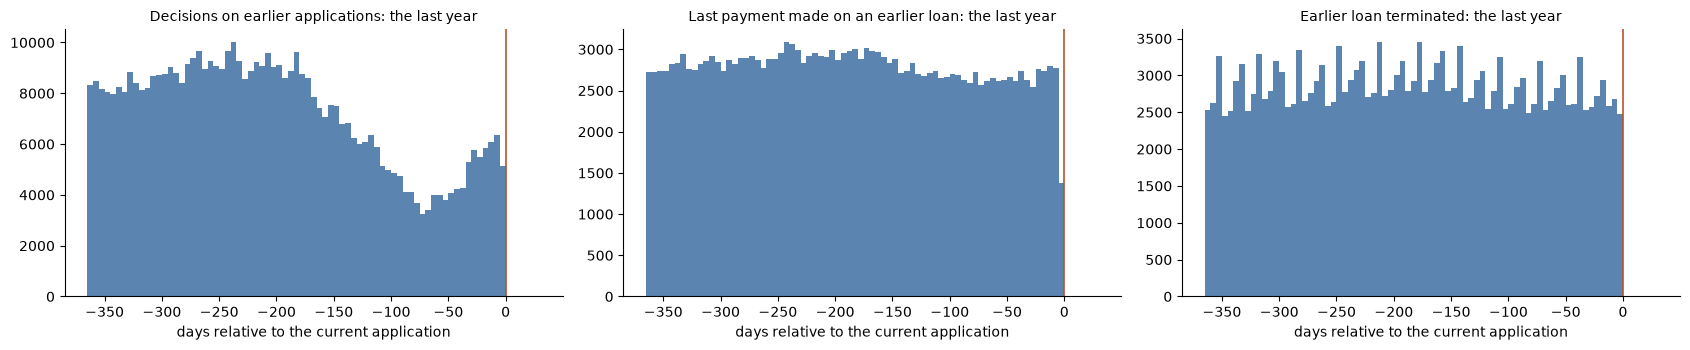

In [21]:
ap = pc[pc['NAME_CONTRACT_STATUS'] == 'Approved']
after = pd.Series({c: int((ap[c] > 0).sum()) for c in LOAN_DATES}, name='approved applications with a date after the current application')
print(after.to_string())
print(f"\nlatest real value of each: { {c: int(ap[c].max()) for c in LOAN_DATES if c != 'DAYS_LAST_DUE_1ST_VERSION'} }")

near = pd.DataFrame({'decisions (all outcomes)': (-pc['DAYS_DECISION']).floordiv(7).value_counts().sort_index().head(14),
                     'first payment due': (-ap['DAYS_FIRST_DUE']).dropna().floordiv(7).value_counts().sort_index().head(14),
                     'last payment made': (-ap['DAYS_LAST_DUE']).dropna().floordiv(7).value_counts().sort_index().head(14),
                     'terminations': (-ap['DAYS_TERMINATION']).dropna().floordiv(7).value_counts().sort_index().head(14)}).fillna(0).astype(int)
near.index = [f'{int(w) * 7} to {int(w) * 7 + 6} days before' for w in near.index]
print('\nevents per week, counting back from the current application:')
print(near.to_string())
print('\nthe most recent week as a share of a typical week two to three months earlier:')
print((near.iloc[0] / near.iloc[8:13].mean() * 100).round(0).astype(int).astype(str).add('%').to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, (label, values) in zip(axes, {'Decisions on earlier applications': pc['DAYS_DECISION'], 'Last payment made on an earlier loan': ap['DAYS_LAST_DUE'], 'Earlier loan terminated': ap['DAYS_TERMINATION']}.items()):
    v = values.dropna()
    ax.hist(v[(v >= -365) & (v <= 30)], bins=np.arange(-365, 32, 5), color='#5b84b1')
    ax.axvline(0, color='#b5542d', linewidth=1.2); ax.set_title(f'{label}: the last year', fontsize=10); ax.set_xlabel('days relative to the current application')
sns.despine(); plt.tight_layout(); plt.show()

### 4.3 Planned dates, and what "still running" means

`DAYS_LAST_DUE_1ST_VERSION` is the last payment date as first planned. It is the only loan date with values after day zero, which is as it should be for loans not yet finished. The two columns created in stage 3, `LAST_DUE_OPEN` and `TERMINATION_OPEN`, mark approved loans with no end recorded. If they describe the application date, they should agree with the plan: a loan still running should mostly have a planned end that is still ahead.

In [22]:
plan = ap['DAYS_LAST_DUE_1ST_VERSION']
state = pd.Series(np.select([ap['TERMINATION_OPEN'] == 1, ap['TERMINATION_OPEN'] == 0], ['still running (no termination recorded)', 'terminated'], 'no loan dates at all'), index=ap.index)
by_state = pd.DataFrame({'approved applications': state.value_counts(), 'pct': state.value_counts(normalize=True) * 100,
                         'planned end still ahead (%)': (plan > 0).groupby(state).mean() * 100, 'planned end passed (%)': (plan <= 0).groupby(state).mean() * 100,
                         'no planned end recorded (%)': plan.isna().groupby(state).mean() * 100,
                         'median days since the decision': (-ap['DAYS_DECISION']).groupby(state).median()})
print(by_state.round(1).to_string())

running = ap[ap['TERMINATION_OPEN'] == 1]
print(f"\nloans still running: by contract type {running['NAME_CONTRACT_TYPE'].value_counts(normalize=True).mul(100).round(1).to_dict()}")
print(f"  planned end passed, by more than 90 days: {(running['DAYS_LAST_DUE_1ST_VERSION'] < -90).mean():.1%}; these have run past their term")
print(f"  last payment recorded although not terminated: {(running['LAST_DUE_OPEN'] == 0).mean():.1%}")
done = ap[ap['TERMINATION_OPEN'] == 0]
early = (done['DAYS_LAST_DUE_1ST_VERSION'] - done['DAYS_LAST_DUE'])
print(f"\nterminated loans: last payment made before the planned date for {(early > 30).mean():.1%} (repaid early), within 30 days of it for {early.between(-30, 30).mean():.1%}, after it for {(early < -30).mean():.1%}")
print(f"  days from the last payment to the termination: median {(done['DAYS_TERMINATION'] - done['DAYS_LAST_DUE']).median():.0f}")
by_part = pd.DataFrame({label: {'approved applications': int((ap['SK_ID_CURR'].map(part_of) == label).sum()),
                                'still running (%)': (ap.loc[ap['SK_ID_CURR'].map(part_of) == label, 'TERMINATION_OPEN'] == 1).mean() * 100,
                                'planned end still ahead (%)': (ap.loc[ap['SK_ID_CURR'].map(part_of) == label, 'DAYS_LAST_DUE_1ST_VERSION'] > 0).mean() * 100} for label in PARTS}).T
print('\nby part of the data:')
print(by_part.round(2).to_string())

                                         approved applications   pct  planned end still ahead (%)  planned end passed (%)  no planned end recorded (%)  median days since the decision
no loan dates at all                                     39556   3.8                          0.0                     0.0                        100.0                           565.0
still running (no termination recorded)                 225908  21.8                         62.4                     1.8                         35.8                           333.0
terminated                                              771183  74.4                         10.8                    87.5                          1.7                          1090.0

loans still running: by contract type {'Revolving loans': 35.8, 'Consumer loans': 32.8, 'Cash loans': 31.4}
  planned end passed, by more than 90 days: 0.3%; these have run past their term
  last payment recorded although not terminated: 8.8%



terminated loans: last payment made before the planned date for 37.7% (repaid early), within 30 days of it for 60.6%, after it for 0.0%
  days from the last payment to the termination: median 6



by part of the data:
                    approved applications  still running (%)  planned end still ahead (%)
train: development               708946.0              21.90                        21.95
train: holdout                   177037.0              21.90                        21.96
test                             150664.0              21.18                        19.81


### 4.4 The eight-year window

In [23]:
years_back = -pc['DAYS_DECISION'] / 365.25
by_year = pd.DataFrame({'decisions': pd.cut(years_back, np.arange(0, 9), right=False).value_counts().sort_index(),
                        'approved (%)': (pc['NAME_CONTRACT_STATUS'] == 'Approved').groupby(pd.cut(years_back, np.arange(0, 9), right=False), observed=True).mean() * 100,
                        'refused (%)': (pc['NAME_CONTRACT_STATUS'] == 'Refused').groupby(pd.cut(years_back, np.arange(0, 9), right=False), observed=True).mean() * 100,
                        'cancelled (%)': (pc['NAME_CONTRACT_STATUS'] == 'Canceled').groupby(pd.cut(years_back, np.arange(0, 9), right=False), observed=True).mean() * 100,
                        'cash loans (%)': (pc['NAME_CONTRACT_TYPE'] == 'Cash loans').groupby(pd.cut(years_back, np.arange(0, 9), right=False), observed=True).mean() * 100})
by_year.index = [f'{int(i.left)} to {int(i.right)} years before' for i in by_year.index]
print(by_year.round(1).to_string())
print(f"\ndecisions in the final 30 days of the window (2,892 to 2,922 days before): {int((pc['DAYS_DECISION'] <= -2892).sum()):,}; in the 30 days before that: {int(pc['DAYS_DECISION'].between(-2891, -2862).sum()):,}")
first = -pc.groupby('SK_ID_CURR')['DAYS_DECISION'].min() / 365.25
print(f"applicants whose first recorded application is 7 to 8 years old: {(first >= 7).mean():.1%} of applicants with history; by part: "
      f"{ {label: round(float((first.reindex(ids).dropna() >= 7).mean() * 100), 1) for label, ids in PARTS.items()} }")

                     decisions  approved (%)  refused (%)  cancelled (%)  cash loans (%)
0 to 1 years before     528822          36.5         20.6           41.7            62.3
1 to 2 years before     371045          67.0         18.8           12.7            48.3
2 to 3 years before     213110          84.8         13.1            0.1            43.7
3 to 4 years before     130744          82.8         14.1            0.0            30.4
4 to 5 years before     102265          84.5         12.7            0.0            20.5
5 to 6 years before      80667          83.1         14.0            0.1            15.8
6 to 7 years before      95795          84.8         14.7            0.1            16.4
7 to 8 years before      82414          86.3         13.7            0.0            11.8

decisions in the final 30 days of the window (2,892 to 2,922 days before): 5,520; in the 30 days before that: 5,751


applicants whose first recorded application is 7 to 8 years old: 18.0% of applicants with history; by part: {'train: development': 17.7, 'train: holdout': 17.5, 'test': 20.6}


### 4.5 A leak screen

Development applicants only. A broad set of crude per-applicant summaries is scored alone against default. If any column carried information from the current application or from after it, some summary would predict default implausibly well. The best single feature in the application table scores 0.716, and the best crude bureau summary scored 0.611.

The screen also looks directly at the rows most likely to be a problem: those decided in the last few days before the current application.

In [24]:
dev_rows = pc[pc['SK_ID_CURR'].isin(DEV_IDS)]
numeric_cols = [c for c in dev_rows.columns if pd.api.types.is_numeric_dtype(dev_rows[c]) and c not in ('SK_ID_PREV', 'SK_ID_CURR')]
grouped = dev_rows.groupby('SK_ID_CURR')
crude = grouped[numeric_cols].agg(['min', 'max', 'mean'])
crude.columns = [f'{c}: {how}' for c, how in crude.columns]
latest_row = dev_rows.sort_values(['SK_ID_CURR', 'DAYS_DECISION', 'SK_ID_PREV']).groupby('SK_ID_CURR')[numeric_cols].last()
crude = crude.join(latest_row.add_suffix(': most recent application'))
for column in ['NAME_CONTRACT_STATUS', 'NAME_CONTRACT_TYPE', 'NAME_CLIENT_TYPE', 'NAME_YIELD_GROUP', 'CODE_REJECT_REASON', 'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'NAME_PAYMENT_TYPE']:
    for v in dev_rows[column].dropna().unique():
        crude[f'share of applications: {column} = {v}'] = (dev_rows[column] == v).groupby(dev_rows['SK_ID_CURR']).mean()
crude['number of applications'] = grouped.size()

y_hist = y_dev.reindex(crude.index)
screen = {}
for c in crude.columns:
    ok = crude[c].notna()
    if ok.sum() < 1000 or crude.loc[ok, c].nunique() < 2:
        continue
    a = roc_auc_score(y_hist[ok], crude.loc[ok, c])
    screen[c] = {'auc': max(a, 1 - a), 'higher_value_means': 'more risk' if a > 0.5 else 'less risk', 'applicants': int(ok.sum())}
screen = pd.DataFrame(screen).T.sort_values('auc', ascending=False)
print(f"development applicants with history: {len(crude):,}; summaries screened: {len(screen)}")
print(f"highest AUC of any single summary: {screen['auc'].max():.4f}; above 0.60: {int((screen['auc'] > 0.60).sum())}; above 0.65: {int((screen['auc'] > 0.65).sum())}")
print('\nthe fifteen strongest:')
print(screen.head(15).to_string())

# the rows closest to the current application
last = dev_rows.sort_values(['SK_ID_CURR', 'DAYS_DECISION', 'SK_ID_PREV']).groupby('SK_ID_CURR').tail(1).set_index('SK_ID_CURR')
gap = pd.cut(-last['DAYS_DECISION'], [0, 3, 7, 30, 90, 365, 3000], labels=['1 to 3 days', '4 to 7', '8 to 30', '31 to 90', '91 to 365', 'over a year'])
y_last = y_dev.reindex(last.index)
recent = pd.DataFrame({'applicants': gap.value_counts().sort_index(), 'default_pct': y_last.groupby(gap.values, observed=True).mean() * 100,
                       'most recent was approved (%)': (last['NAME_CONTRACT_STATUS'] == 'Approved').groupby(gap.values, observed=True).mean() * 100,
                       'default_pct if approved': y_last[(last['NAME_CONTRACT_STATUS'] == 'Approved').values].groupby(gap[(last['NAME_CONTRACT_STATUS'] == 'Approved').values].values, observed=True).mean() * 100,
                       'default_pct if refused': y_last[(last['NAME_CONTRACT_STATUS'] == 'Refused').values].groupby(gap[(last['NAME_CONTRACT_STATUS'] == 'Refused').values].values, observed=True).mean() * 100})
print('\nby how long before the current application the most recent earlier one was decided:')
print(recent.round(2).to_string())
running_now = (dev_rows['TERMINATION_OPEN'] == 1).groupby(dev_rows['SK_ID_CURR']).sum().reindex(DEV_IDS).fillna(0)
has_history = pd.Series(DEV_IDS.isin(crude.index), index=DEV_IDS)
print(f"\napplicants with a Home Credit loan still running at the current application: {(running_now > 0).mean():.1%}; default rate {y_dev[(running_now > 0).values].mean():.2%} "
      f"against {y_dev[((running_now == 0) & has_history).values].mean():.2%} for those with history and none running")
a_run = roc_auc_score(y_dev[has_history.values], running_now[has_history.values])
print(f"number of loans still running, used alone as a score: AUC {max(a_run, 1 - a_run):.4f}")

development applicants with history: 232,834; summaries screened: 99
highest AUC of any single summary: 0.5913; above 0.60: 0; above 0.65: 0

the fifteen strongest:
                                                             auc higher_value_means applicants
DAYS_FIRST_DRAWING: mean                                0.591302          more risk      42736
DAYS_FIRST_DRAWING: min                                 0.591267          more risk      42736
DAYS_FIRST_DRAWING: max                                 0.591206          more risk      42736
DAYS_FIRST_DRAWING: most recent application             0.591206          more risk      42736
share of applications: NAME_CONTRACT_STATUS = Refused   0.561436          more risk     232834
share of applications: NAME_CONTRACT_STATUS = Approved  0.559712          less risk     232834
DAYS_DECISION: mean                                      0.55627          more risk     232834
DAYS_FIRST_DUE: min                                     0.555076          m


by how long before the current application the most recent earlier one was decided:
             applicants  default_pct  most recent was approved (%)  default_pct if approved  default_pct if refused
1 to 3 days        1209         9.76                         26.14                     9.18                   12.64
4 to 7             2505         8.82                         22.44                     8.90                    8.67
8 to 30           12163         9.69                         30.55                     9.66                   12.64
31 to 90          20304         8.39                         38.06                     7.91                   11.86
91 to 365         99004         8.68                         48.88                     7.78                   13.15
over a year       97649         7.43                         85.40                     6.99                   11.63



applicants with a Home Credit loan still running at the current application: 48.7%; default rate 8.35% against 8.02% for those with history and none running
number of loans still running, used alone as a score: AUC 0.5069


### 4.6 The preparation function

Stage 3's nine rules clean the table. This stage adds no rule: sections 4.1 to 4.5 found nothing recorded after the current application and no copy of it. The function below wraps the cleaning and asserts the properties this stage relied on, so that a different file, or a future version of this one, could not break them silently.

In [25]:
def prepare_previous(raw, report=None):
    # The nine cleaning rules of section 3.7, then a guard: nothing dated on or after the current application, apart from planned end dates.
    df = clean_previous(raw, report)
    assert (df['DAYS_DECISION'] < 0).all(), 'an earlier application is dated on or after the current one'
    for c in ['DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE', 'DAYS_TERMINATION']:
        assert not (df[c] > 0).any(), f'{c} has a date after the current application'
    return df

final_report = {}
prev_ready = prepare_previous(prev, final_report)
ready_part = prev_ready['SK_ID_CURR'].map(part_of)
time_checks = {
    'identical to the cleaned table of stage 3': prev_ready.equals(prev_clean),
    'no decision on or after the current application': bool((prev_ready['DAYS_DECISION'] < 0).all()),
    'no loan started, was last paid or was terminated after the current application': not (prev_ready[['DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE', 'DAYS_TERMINATION']] > 0).any().any(),
    'the only dates after it are planned ends': bool((prev_ready[LOAN_DATES] > 0).any().to_dict() == {c: c == 'DAYS_LAST_DUE_1ST_VERSION' for c in LOAN_DATES}),
    'no applicant lost every earlier application': prev_ready['SK_ID_CURR'].nunique() == prev['SK_ID_CURR'].nunique(),
    'preparing the test rows alone gives the same result': prepare_previous(prev[prev_part == 'test']).equals(prev_ready[ready_part == 'test'].reset_index(drop=True)),
}
for name, ok in time_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(time_checks.values())
print(f"\nprepared table: {prev_ready.shape[0]:,} rows, {prev_ready.shape[1]} columns, {prev_ready['SK_ID_CURR'].nunique():,} applicants")

PASS  identical to the cleaned table of stage 3
PASS  no decision on or after the current application
PASS  no loan started, was last paid or was terminated after the current application
PASS  the only dates after it are planned ends
PASS  no applicant lost every earlier application
PASS  preparing the test rows alone gives the same result

prepared table: 1,605,020 rows, 34 columns, 338,857 applicants


### Stage 4 findings

**The current application is not in the table, and nothing in it is dated after the current application**

- No earlier application was decided on the day of the current application or later. Only two were decided the day before, and about 1,100 to 1,600 on each of the days before that. There is no pile of records at the end.
- Rows that match the current application on both the amount granted and the annuity are rare: 704 of 1.6 million, from 638 applicants. Most of them (427) are refusals. That is the picture of an applicant who was refused, applied again on the same terms, and was approved the second time. It is not the current application recorded twice.
- Approved rows that match and were decided in the last seven days number 41, among 356,255 applicants. If the current application were routinely stored here, that figure would be in the hundreds of thousands.
- No earlier loan started, had its last payment or was terminated after the current application. The latest real value of each of those dates is two days before it.
- The only dates after day zero are 224,384 *planned* last payments. A plan is made when the loan is granted, so it was known at the time.

**The table was recorded at the application date**
- Last payments recorded in the final week are 52% of a typical week two to three months earlier, and terminations 76%. Recent events are under-recorded, which is a reporting delay, as in the bureau. A table pulled later would have caught up.
- Decisions are the exception: the last week has 120% of a typical week. People who apply to Home Credit often applied to it recently as well. This is behaviour, not a recording artefact, and stage 2 already found that recent applications go with slightly higher risk.

**"Still running" means what it should**

| | Share of approved loans | Planned end still ahead | Planned end passed | No planned end |
|---|---:|---:|---:|---:|
| Still running | 21.8% | 62.4% | 1.8% | 35.8% |
| Terminated | 74.4% | 10.8% | 87.5% | 1.7% |
| No loan dates at all | 3.8% | | | 100% |

- Loans with no termination recorded almost all have a planned end that is still ahead, or no planned end because they are revolving. Only 1.8% have passed their planned end. So the mark describes the application date, and not some later moment.
- Among terminated loans, 38% had their last payment more than 30 days before the planned date. They were repaid early.
- **No terminated loan has a last payment after its planned date.** `DAYS_LAST_DUE` is therefore the due date of the last instalment, not the day the money arrived. This table cannot say whether a loan was paid late. That information is in `installments_payments`.
- The share still running is the same in every part of the data: 21.9% in development and holdout, 21.2% in test.

**Cancelled applications are only kept for about two years**

| Decided | Approved | Refused | Cancelled |
|---|---:|---:|---:|
| In the last year | 36.5% | 20.6% | 41.7% |
| 1 to 2 years before | 67.0% | 18.8% | 12.7% |
| 2 to 8 years before | 83% to 86% | 13% to 15% | 0.0% to 0.1% |

- This was not visible until the records were laid out by age. There are essentially no cancelled applications older than two years, although refusals and approvals go back eight. Either such records are deleted after a time or the practice that creates them is recent.
- It changes how several features must be built. The share of an applicant's applications that were refused, taken over all their history, depends on how many cancelled records happen to fall inside the two-year window. Two applicants with identical behaviour and different timing would get different shares. **Shares should be computed among approved and refused applications only**, which stage 2 already found to be the slightly better measure (0.562 against 0.561).
- It also explains the shift between train and test in the cancelled count. Counts of cancelled applications are really a measure of recent activity.
- Refusals are a steady 13% to 15% of older records and rise to 21% in the last year.

**The eight-year window**
- The history is cut at eight years, with as many decisions in the last month of the window as in the month before.
- For 18% of applicants with history, the first recorded application sits at the edge (17.7% in development, 20.6% in test), so the true length of their relationship with Home Credit is unknown.

**The leak screen is clean**
- 99 crude summaries per applicant were scored alone against default on the 232,834 development applicants with history. The strongest is 0.591, and none exceeds 0.60. The best application feature scores 0.716 and the best crude bureau summary scored 0.611.
- The strongest is the date of first drawing, which exists only for the 18% of applicants with a revolving loan. Next are the shares of applications refused (0.561) and approved (0.560).
- Applicants whose most recent earlier application was decided one to three days before the current one default at 9.8%, against 7.4% where it was over a year before. Nothing about the most recent rows looks out of line with the rest.
- Half of applicants (48.7%) had a Home Credit loan still running when they applied. They default at 8.35% against 8.02% for the others, so on its own this says little.

**The preparation function**
- No rule was added. `prepare_previous` is the stage 3 cleaning with assertions that no decision or loan event is dated on or after the current application, so that a different file could not break this silently. All 6 checks pass.

**Leakage check for this stage**
- Sections 4.1 to 4.4 used no target.
- Section 4.5 used development outcomes only. Nothing was fitted or selected.

**Decisions**
- The table is safe to build features from.
- Carried to stage 6: shares are taken among approved and refused applications; cancelled applications are counted only as recent activity; a feature for history that reaches the edge of the window; early repayment is available, late payment is not.

## Stage 5: Row-level signal

Which columns relate to default, and in what shape?

As in notebook 03, each earlier application is given the outcome of the applicant who made it, and every rate is weighted so that each applicant counts once in total however many applications they made. An application from an applicant with *n* of them has weight 1/*n*.

This stage describes. It does not select. No feature is chosen here by its score.

Only the 232,834 development applicants with history are used.

| Section | Question |
|---|---|
| 5.1 | Set-up |
| 5.2 | How the application ended, and why it was refused |
| 5.3 | What kind of application it was |
| 5.4 | The terms of approved loans |
| 5.5 | How the earlier loan went: early repayment, still running, insured |
| 5.6 | Does the age of a record change what it says? |
| 5.7 | Is any of this new, or do the external scores already hold it? |

### 5.1 Set-up

In [26]:
rows = prev_ready[prev_ready['SK_ID_CURR'].isin(DEV_IDS)].copy()
rows['y'] = rows['SK_ID_CURR'].map(y_dev).astype(int)
rows['w'] = 1 / rows.groupby('SK_ID_CURR')['SK_ID_CURR'].transform('size')
assert rows['SK_ID_CURR'].nunique() == int(round(rows['w'].sum())) == 232834
assert not rows['SK_ID_CURR'].isin(HOLDOUT_IDS).any() and not rows['SK_ID_CURR'].isin(TEST_IDS).any()
HIST_RATE = float((rows['y'] * rows['w']).sum() / rows['w'].sum())
print(f"development applications: {len(rows):,} from {rows['SK_ID_CURR'].nunique():,} applicants; default rate with each applicant counted once: {HIST_RATE:.2%}")

def weighted_rate(groups, frame=None, order=None, min_weight=300, sort=False):
    # default rate per group with each applicant counting once in total. The interval treats the summed weights as the sample size, so it is approximate.
    frame = rows if frame is None else frame
    g = pd.DataFrame({'group': np.asarray(groups, dtype=object), 'y': frame['y'].values, 'w': frame['w'].values, 'id': frame['SK_ID_CURR'].values}).dropna(subset=['group'])
    out = g.groupby('group').apply(lambda d: pd.Series({'applications': len(d), 'applicants': d['id'].nunique(), 'applicant_equivalents': d['w'].sum(),
                                                         'default_pct': (d['y'] * d['w']).sum() / d['w'].sum() * 100}), include_groups=False)
    se = np.sqrt(out['default_pct'] / 100 * (1 - out['default_pct'] / 100) / out['applicant_equivalents']) * 100
    out['low_pct'], out['high_pct'] = out['default_pct'] - 1.96 * se, out['default_pct'] + 1.96 * se
    out['ratio_to_overall'] = out['default_pct'] / (HIST_RATE * 100)
    out = out[out['applicant_equivalents'] >= min_weight]
    if order is not None:
        out = out.reindex([o for o in order if o in out.index])
    return out.sort_values('default_pct') if sort else out

def weighted_auc(values, frame=None):
    frame = rows if frame is None else frame
    v = np.asarray(values, dtype=float)
    ok = ~np.isnan(v)
    a = roc_auc_score(frame['y'].values[ok], v[ok], sample_weight=frame['w'].values[ok])
    return max(a, 1 - a), ('more risk' if a > 0.5 else 'less risk')

def fifths(values, frame, bins=5):
    v = np.asarray(values, dtype=float)
    ok = ~np.isnan(v)
    v, f = v[ok], frame[ok]
    order = np.argsort(v, kind='stable')
    cum = np.cumsum(f['w'].values[order]) / f['w'].sum()
    g = np.minimum((cum * bins).astype(int), bins - 1)
    d = pd.DataFrame({'g': g, 'v': v[order], 'y': f['y'].values[order], 'w': f['w'].values[order]})
    return d.groupby('g').apply(lambda x: pd.Series({'median_value': x['v'].median(), 'default_pct': (x['y'] * x['w']).sum() / x['w'].sum() * 100}), include_groups=False)

SHOW = ['applications', 'applicants', 'default_pct', 'low_pct', 'high_pct', 'ratio_to_overall']
st = rows['NAME_CONTRACT_STATUS']
ok_app, ok_ref, ok_can = (st == 'Approved').values, (st == 'Refused').values, (st == 'Canceled').values

development applications: 1,088,080 from 232,834 applicants; default rate with each applicant counted once: 8.19%


### 5.2 How the application ended, and why it was refused

In [27]:
print('by outcome:')
print(weighted_rate(st, order=['Approved', 'Unused offer', 'Canceled', 'Refused'])[SHOW].round(2).to_string())
print('\nby reason for refusal (refused applications only):')
print(weighted_rate(rows.loc[ok_ref, 'CODE_REJECT_REASON'].fillna('no reason recorded'), frame=rows[ok_ref], sort=True)[SHOW].round(2).to_string())
print('\nby outcome and contract type:')
print(weighted_rate(st + ' | ' + rows['NAME_CONTRACT_TYPE'].fillna('type missing'), sort=True)[SHOW].round(2).to_string())

empty_cancel = ok_can & rows['AMT_APPLICATION'].isna().values
print('\ncancelled applications, by whether anything was requested:')
print(weighted_rate(np.where(empty_cancel[ok_can], 'nothing requested', 'an amount was requested'), frame=rows[ok_can])[SHOW].round(2).to_string())

# at applicant level: holding at least one application of a kind
flags = pd.DataFrame({f'refused for reason {r}': (rows['CODE_REJECT_REASON'] == r).groupby(rows['SK_ID_CURR']).any() for r in ['HC', 'LIMIT', 'SCO', 'SCOFR', 'VERIF']})
flags['has an unused offer'] = (st == 'Unused offer').groupby(rows['SK_ID_CURR']).any()
flags['has a cancelled application where an amount was requested'] = pd.Series(ok_can & ~empty_cancel, index=rows.index).groupby(rows['SK_ID_CURR']).any()
y_f = y_dev.reindex(flags.index)
level = pd.DataFrame({c: {'applicants_with': int(flags[c].sum()), 'pct_of_applicants': flags[c].mean() * 100, 'default_pct_with': y_f[flags[c]].mean() * 100, 'default_pct_without': y_f[~flags[c]].mean() * 100} for c in flags}).T
level['ratio'] = level['default_pct_with'] / level['default_pct_without']
print('\napplicants with at least one application of a kind:')
print(level.round(2).to_string())

by outcome:


              applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                   
Approved          708946.0    232023.0         7.60     7.47      7.72              0.93
Unused offer       17872.0     15186.0         8.54     7.62      9.46              1.04
Canceled          175650.0     88474.0         8.59     8.26      8.93              1.05
Refused           185612.0     79161.0        11.81    11.42     12.21              1.44

by reason for refusal (refused applications only):


                    applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                         
VERIF                     2357.0      1944.0         8.55     5.62     11.48              1.04
SCO                      25345.0     17326.0         9.65     8.72     10.58              1.18
no reason recorded        2670.0      2319.0        10.92     7.77     14.07              1.33
HC                      110076.0     52195.0        11.56    11.02     12.09              1.41
LIMIT                    37047.0     22494.0        12.34    11.49     13.18              1.51
SCOFR                     7966.0      5313.0        20.03    17.83     22.23              2.45

by outcome and contract type:


                               applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                    
Approved | Cash loans              212701.0    107037.0         7.43     7.16      7.69              0.91
Approved | Consumer loans          430205.0    213130.0         7.50     7.35      7.64              0.92
Canceled | Cash loans              148852.0     79677.0         8.24     7.88      8.60              1.01
Unused offer | Consumer loans       17548.0     14939.0         8.56     7.63      9.49              1.05
Approved | Revolving loans          66040.0     64700.0         8.96     8.49      9.43              1.09
Refused | Consumer loans            50343.0     32309.0         9.98     9.34     10.61              1.22
Canceled | Revolving loans          25623.0     21352.0        10.34     9.42     11.26              1.26
Refused | Cash loans               108491.0   

                         applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                              
an amount was requested        7118.0      6410.0         7.73     6.27      9.19              0.94
nothing requested            168532.0     85907.0         8.64     8.29      8.98              1.05



applicants with at least one application of a kind:
                                                           applicants_with  pct_of_applicants  default_pct_with  default_pct_without  ratio
refused for reason HC                                              52195.0              22.42             10.63                 7.48   1.42
refused for reason LIMIT                                           22494.0               9.66             11.98                 7.79   1.54
refused for reason SCO                                             17326.0               7.44              9.92                 8.05   1.23
refused for reason SCOFR                                            5313.0               2.28             19.57                 7.92   2.47
refused for reason VERIF                                            1944.0               0.83              9.77                 8.18   1.20
has an unused offer                                                15186.0               6.52              

### 5.3 What kind of application it was

Client type, yield group, portfolio, channel and the other descriptive columns. For the columns with many values, the lowest and highest groups are shown.

In [28]:
for c in ['NAME_CLIENT_TYPE', 'NAME_YIELD_GROUP', 'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'NAME_PAYMENT_TYPE', 'CHANNEL_TYPE', 'NAME_TYPE_SUITE']:
    print(f"\n{c}:")
    print(weighted_rate(rows[c].fillna('(missing)'), sort=True)[SHOW].round(2).to_string())

print('\nNAME_YIELD_GROUP among approved applications only:')
print(weighted_rate(rows.loc[ok_app, 'NAME_YIELD_GROUP'].fillna('(missing)'), frame=rows[ok_app], order=['low_action', 'low_normal', 'middle', 'high', '(missing)'])[SHOW].round(2).to_string())

spread = {}
for c in ['NAME_GOODS_CATEGORY', 'NAME_SELLER_INDUSTRY', 'NAME_CASH_LOAN_PURPOSE', 'PRODUCT_COMBINATION', 'WEEKDAY_APPR_PROCESS_START']:
    t = weighted_rate(rows[c].fillna('(missing)'), sort=True, min_weight=500)
    spread[c] = {'values_shown': len(t), 'lowest': f"{t.index[0]} ({t['default_pct'].iloc[0]:.1f}%)", 'highest': f"{t.index[-1]} ({t['default_pct'].iloc[-1]:.1f}%)",
                 'range_points': t['default_pct'].iloc[-1] - t['default_pct'].iloc[0], 'missing_pct': rows[c].isna().mean() * 100}
print('\ncolumns with many values (groups amounting to at least 500 applicants):')
print(pd.DataFrame(spread).T.to_string())
print('\nPRODUCT_COMBINATION in full:')
print(weighted_rate(rows['PRODUCT_COMBINATION'].fillna('(missing)'), sort=True, min_weight=500)[SHOW].round(2).to_string())


NAME_CLIENT_TYPE:


           applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                
Refreshed       89039.0     61342.0         6.65     6.33      6.97              0.81
Repeater       790980.0    176629.0         8.13     7.98      8.28              0.99
New            206908.0    189667.0         8.72     8.53      8.91              1.06

NAME_YIELD_GROUP:


            applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                 
low_action       62625.0     46106.0         5.96     5.59      6.32              0.73
low_normal      218880.0    124578.0         6.67     6.45      6.89              0.81
middle          259349.0    141319.0         7.73     7.51      7.94              0.94
(missing)       302570.0    132288.0         9.45     9.19      9.70              1.15
high            244656.0    131010.0         9.54     9.30      9.78              1.16

NAME_PORTFOLIO:


           applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                
POS            473556.0    214348.0         7.63     7.49      7.77              0.93
Cash           311653.0    119327.0         8.40     8.15      8.64              1.03
(missing)      211190.0    102002.0         9.25     8.94      9.57              1.13
Cards           91380.0     77843.0         9.81     9.37     10.24              1.20

NAME_PRODUCT_TYPE:


           applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                
x-sell         300997.0    121000.0         7.61     7.37      7.85              0.93
(missing)      685047.0    224130.0         7.95     7.82      8.08              0.97
walk-in        102036.0     58205.0        11.73    11.27     12.18              1.43

NAME_PAYMENT_TYPE:


...

                            applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                 
Channel of corporate sales        4259.0      1735.0         4.92     3.49      6.36              0.60
Stone                           145849.0     93794.0         7.20     6.95      7.45              0.88
Regional / Local                 73911.0     51893.0         7.59     7.23      7.95              0.93
Country-wide                    336423.0    161095.0         8.21     8.03      8.40              1.00
Credit and cash offices         444041.0    122506.0         8.45     8.24      8.66              1.03
Contact center                   45385.0     32093.0         9.23     8.61      9.85              1.13
AP+ (Cash loan)                  37890.0     18307.0        12.18    11.41     12.96              1.49

NAME_TYPE_SUITE:


                 applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                      
Children              21469.0     17429.0         6.26     5.59      6.93              0.76
Family               144877.0     91015.0         7.14     6.87      7.41              0.87
Spouse, partner       45980.0     34150.0         7.68     7.18      8.17              0.94
Unaccompanied        339886.0    146768.0         7.91     7.71      8.12              0.97
Group of people        1543.0      1437.0         8.67     5.81     11.52              1.06
Other_B               12055.0     10334.0         8.76     7.74      9.78              1.07
(missing)            516002.0    187378.0         8.80     8.63      8.96              1.07
Other_A                6268.0      5507.0         9.27     7.83     10.71              1.13

NAME_YIELD_GROUP among approved applications only:


            applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                 
low_action       48574.0     40906.0         5.77     5.39      6.15              0.70
low_normal      168534.0    114236.0         6.26     6.03      6.49              0.76
middle          218563.0    134167.0         7.31     7.09      7.53              0.89
high            207232.0    125797.0         9.19     8.94      9.44              1.12
(missing)        66043.0     64702.0         8.96     8.49      9.43              1.09



columns with many values (groups amounting to at least 500 applicants):
                           values_shown                                lowest                    highest range_points missing_pct
NAME_GOODS_CATEGORY                  16               Medical Supplies (4.8%)           Vehicles (10.1%)     5.321248   54.757555
NAME_SELLER_INDUSTRY                  9                       Clothing (5.1%)    Auto technology (10.0%)     4.890641   48.933994
NAME_CASH_LOAN_PURPOSE                4                      (missing) (8.1%)       Urgent needs (13.3%)      5.20321   95.651423
PRODUCT_COMBINATION                  17  POS industry without interest (3.7%)  Cash X-Sell: high (11.1%)     7.429329    0.021873
WEEKDAY_APPR_PROCESS_START            7                         SUNDAY (7.6%)              MONDAY (8.4%)       0.7975         0.0

PRODUCT_COMBINATION in full:


                                applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                     
POS industry without interest         8505.0      7617.0         3.66     2.95      4.36              0.45
POS industry with interest           66449.0     51325.0         5.79     5.47      6.11              0.71
Cash X-Sell: low                     87609.0     52497.0         5.87     5.47      6.28              0.72
POS household without interest       57038.0     44429.0         6.49     6.10      6.88              0.79
Cash X-Sell: middle                  95745.0     57038.0         7.36     6.94      7.78              0.90
POS others without interest           1675.0      1513.0         7.37     5.23      9.51              0.90
POS other with interest              16192.0     13545.0         7.59     6.86      8.32              0.93
POS mobile without interest          

### 5.4 The terms of approved loans

Amounts, annuity, term and down payment only mean something for applications that led to a loan. Each is cut into five groups of equal weight among approved applications.

In [29]:
A = rows[ok_app]
terms = {
    'amount granted': A['AMT_CREDIT'], 'amount requested': A['AMT_APPLICATION'], 'annuity': A['AMT_ANNUITY'], 'number of payments': A['CNT_PAYMENT'],
    'down payment rate (consumer loans)': A['RATE_DOWN_PAYMENT'], 'down payment amount': A['AMT_DOWN_PAYMENT'],
    'granted / requested': A['AMT_CREDIT'] / A['AMT_APPLICATION'], 'total repayable / granted (cost of credit)': A['AMT_ANNUITY'] * A['CNT_PAYMENT'] / A['AMT_CREDIT'],
    'annuity / granted': A['AMT_ANNUITY'] / A['AMT_CREDIT'], 'days since the decision': -A['DAYS_DECISION'], 'hour of the application': A['HOUR_APPR_PROCESS_START'],
    'seller place area': A['SELLERPLACE_AREA'],
}
out, medians = {}, {}
for label, values in terms.items():
    auc, direction = weighted_auc(values, A)
    curve = fifths(values, A)
    out[label] = {'applications_with_a_value': int(values.notna().sum()), 'auc': auc, 'higher_value_means': direction, **{f'fifth_{i + 1}': curve['default_pct'].iloc[i] for i in range(len(curve))}}
    medians[label] = {f'fifth_{i + 1}': curve['median_value'].iloc[i] for i in range(len(curve))}
approved_rate = float((A['y'] * A['w']).sum() / A['w'].sum()) * 100
print(f"approved applications: {len(A):,}; default rate of their holders {approved_rate:.2f}%\n")
print('default rate (%) by fifth of each quantity, lowest values first:')
print(pd.DataFrame(out).T.to_string(float_format=lambda v: f'{v:,.2f}'))
print('\nmedian value in each fifth:')
print(pd.DataFrame(medians).T.to_string(float_format=lambda v: f'{v:,.2f}'))

# the same for refused applications: what was asked for and refused
R = rows[ok_ref]
print('\nrefused applications, default rate (%) by fifth of the amount requested:', fifths(R['AMT_APPLICATION'], R)['default_pct'].round(2).tolist(),
      '(medians', fifths(R['AMT_APPLICATION'], R)['median_value'].round(0).astype(int).tolist(), ')')

approved applications: 708,946; default rate of their holders 7.60%

default rate (%) by fifth of each quantity, lowest values first:
                                           applications_with_a_value  auc higher_value_means fifth_1 fifth_2 fifth_3 fifth_4 fifth_5
amount granted                                                708005 0.53          less risk    8.79    8.00    7.31    6.99    6.86
amount requested                                              677309 0.54          less risk    9.11    8.13    7.30    6.82    6.68
annuity                                                       708941 0.54          less risk    9.07    8.19    7.48    6.98    6.27
number of payments                                            642903 0.52          more risk    7.00    7.36    7.41    7.61    8.01
down payment rate (consumer loans)                            454848 0.52          less risk    7.94    7.69    8.37    6.87    6.44
down payment amount                                           454848


refused applications, default rate (%) by fifth of the amount requested: [11.12, 10.98, 12.61, 12.02, 10.21] (medians [41518, 90000, 180000, 337500, 900000] )


### 5.5 How the earlier loan went

Stage 4 established what this table can say about an earlier loan: whether it was still running at the current application, whether it ended before its planned date, and whether it was insured. It cannot say whether payments were late.

In [30]:
early_by = A['DAYS_LAST_DUE_1ST_VERSION'] - A['DAYS_LAST_DUE']
loan_state = np.select([A['TERMINATION_OPEN'] == 1, (A['TERMINATION_OPEN'] == 0) & (early_by > 30), (A['TERMINATION_OPEN'] == 0) & early_by.notna(), A['TERMINATION_OPEN'].isna()],
                       ['still running', 'ended early (over 30 days before the plan)', 'ended on schedule', 'no loan dates recorded'], 'ended, plan not recorded')
print('approved applications, by how the loan stood at the current application:')
print(weighted_rate(loan_state, frame=A, sort=True)[SHOW].round(2).to_string())

share_used = ((A['DAYS_LAST_DUE'] - A['DAYS_FIRST_DUE']) / (A['DAYS_LAST_DUE_1ST_VERSION'] - A['DAYS_FIRST_DUE']).where(lambda s: s > 0)).where(A['TERMINATION_OPEN'] == 0)
print('\nterminated loans, default rate (%) by fifth of the share of the planned term actually used:', fifths(share_used, A)['default_pct'].round(2).tolist(),
      '(medians', fifths(share_used, A)['median_value'].round(2).tolist(), ')')
running = A['TERMINATION_OPEN'] == 1
remaining = A['DAYS_LAST_DUE_1ST_VERSION'].where(running & (A['DAYS_LAST_DUE_1ST_VERSION'] > 0))
print('loans still running, by fifth of the days remaining to the planned end:', fifths(remaining, A)['default_pct'].round(2).tolist(), '(medians', fifths(remaining, A)['median_value'].round(0).astype(int).tolist(), ')')
print('\nby contract type and whether the loan was still running:')
print(weighted_rate(A['NAME_CONTRACT_TYPE'].fillna('missing') + np.where(running, ' | still running', ' | ended or no dates'), frame=A, sort=True)[SHOW].round(2).to_string())
print('\ninsured on approval:')
print(weighted_rate(A['NFLAG_INSURED_ON_APPROVAL'].map({1.0: 'insured', 0.0: 'not insured'}).fillna('not recorded'), frame=A)[SHOW].round(2).to_string())

# at applicant level
per = pd.DataFrame(index=pd.Index(rows['SK_ID_CURR'].unique(), name='SK_ID_CURR')).sort_index()
per['loans still running'] = (rows['TERMINATION_OPEN'] == 1).groupby(rows['SK_ID_CURR']).sum()
per['loans ended early'] = pd.Series(loan_state == 'ended early (over 30 days before the plan)', index=A.index).groupby(A['SK_ID_CURR']).sum().reindex(per.index).fillna(0)
per['loans ended'] = (rows['TERMINATION_OPEN'] == 0).groupby(rows['SK_ID_CURR']).sum()
per['share of ended loans that ended early'] = per['loans ended early'] / per['loans ended'].where(per['loans ended'] > 0)
y_p = y_dev.reindex(per.index)
print('\ndefault rate (%) by number of loans, among applicants with history:')
print(pd.DataFrame({c: y_p.groupby(per[c].clip(upper=4)).mean() * 100 for c in ['loans still running', 'loans ended early', 'loans ended']}).rename(index={4.0: '4 or more'}).round(2).to_string())
print('each alone as a score:', {c: round(max(a, 1 - a), 4) for c in per.columns for a in [roc_auc_score(y_p[per[c].notna()], per.loc[per[c].notna(), c])]})

approved applications, by how the loan stood at the current application:


                                            applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                                 
ended, plan not recorded                          8542.0      8485.0         6.37     5.18      7.57              0.78
ended on schedule                               321190.0    172173.0         7.23     7.05      7.40              0.88
no loan dates recorded                           26764.0     23149.0         7.46     6.69      8.24              0.91
ended early (over 30 days before the plan)      197219.0    115695.0         7.53     7.29      7.77              0.92
still running                                   155231.0    119862.0         8.52     8.25      8.79              1.04



terminated loans, default rate (%) by fifth of the share of the planned term actually used: [8.02, 6.68, 7.1, 7.42, 7.44] (medians [0.27, 0.73, 1.0, 1.0, 1.0] )


loans still running, by fifth of the days remaining to the planned end: [7.27, 8.04, 7.6, 8.44, 9.34] (medians [32, 105, 201, 340, 817] )

by contract type and whether the loan was still running:


                                     applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                          
Revolving loans | ended or no dates       11249.0     10994.0         6.93     5.83      8.03              0.85
Consumer loans | ended or no dates       379232.0    198835.0         7.30     7.14      7.45              0.89
Cash loans | still running                49467.0     45926.0         7.33     6.81      7.85              0.90
Cash loans | ended or no dates           163234.0     86364.0         7.46     7.15      7.77              0.91
Consumer loans | still running            50973.0     46622.0         8.63     8.23      9.04              1.05
Revolving loans | still running           54791.0     54779.0         9.30     8.78      9.82              1.14

insured on approval:


              applications  applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                   
insured           225131.0    122447.0         7.59     7.34      7.83              0.93
not insured       457051.0    214895.0         7.61     7.46      7.75              0.93
not recorded       26764.0     23149.0         7.46     6.69      8.24              0.91



default rate (%) by number of loans, among applicants with history:
           loans still running  loans ended early  loans ended
0                         8.02               8.41        10.35
1                         8.26               7.92         9.25
2                         8.49               7.85         7.74
3                         9.07               8.09         7.11
4 or more                15.13               8.55         6.71


each alone as a score: {'loans still running': 0.5069, 'loans ended early': 0.5066, 'loans ended': 0.5436, 'share of ended loans that ended early': 0.511}


### 5.6 Does the age of a record change what it says?

In [31]:
age = pd.cut(-rows['DAYS_DECISION'] / 365.25, [-0.01, 0.25, 0.5, 1, 2, 4, 8.01], labels=['last 3 months', '3 to 6 months', '6 to 12 months', '1 to 2 years', '2 to 4 years', '4 to 8 years'])
by_age = pd.DataFrame({'approved': weighted_rate(age[ok_app], frame=rows[ok_app])['default_pct'], 'refused': weighted_rate(age[ok_ref], frame=rows[ok_ref])['default_pct'],
                       'cancelled': weighted_rate(age[ok_can], frame=rows[ok_can], min_weight=100)['default_pct'],
                       'applications': age.value_counts()}).reindex(list(age.cat.categories))
by_age['refused / approved'] = by_age['refused'] / by_age['approved']
print('default rate (%) of the applicant, by when the earlier application was decided and how it ended:')
print(by_age.round(2).to_string())

# refusals counted over different windows, at applicant level
windows = {'last 6 months': 183, 'last 12 months': 365, 'last 24 months': 730, 'all eight years': 3000}
refusal_counts = pd.DataFrame({label: (ok_ref & (rows['DAYS_DECISION'].values >= -d)) for label, d in windows.items()}, index=rows.index).groupby(rows['SK_ID_CURR']).sum()
approved_counts = pd.DataFrame({label: (ok_app & (rows['DAYS_DECISION'].values >= -d)) for label, d in windows.items()}, index=rows.index).groupby(rows['SK_ID_CURR']).sum()
y_r = y_dev.reindex(refusal_counts.index)
print('\ndefault rate (%) by number of refusals in each window:')
print(pd.DataFrame({c: y_r.groupby(refusal_counts[c].clip(upper=3)).mean() * 100 for c in refusal_counts}).rename(index={3: '3 or more'}).round(2).to_string())
decided = (refusal_counts + approved_counts)
print('\neach used alone as a score:')
print(pd.DataFrame({'number of refusals': {c: max(a, 1 - a) for c in refusal_counts for a in [roc_auc_score(y_r, refusal_counts[c])]},
                    'refusals / (approved + refused)': {c: max(a, 1 - a) for c in refusal_counts for a in [roc_auc_score(y_r[(decided[c] > 0).values], (refusal_counts[c] / decided[c])[(decided[c] > 0).values])]},
                    'applicants with a decision in the window (%)': {c: (decided[c] > 0).mean() * 100 for c in refusal_counts}}).round(4).to_string())
last_ref = (-rows.loc[ok_ref, 'DAYS_DECISION']).groupby(rows.loc[ok_ref, 'SK_ID_CURR']).min()
a = roc_auc_score(y_dev.reindex(last_ref.index), last_ref)
print(f"\ndays since the most recent refusal, among the {len(last_ref):,} applicants who have one: AUC {max(a, 1 - a):.4f} ({'longer ago means less risk' if a < 0.5 else 'longer ago means more risk'})")

default rate (%) of the applicant, by when the earlier application was decided and how it ended:
                approved  refused  cancelled  applications  refused / approved
last 3 months       9.00    12.20       8.61         58961                1.36
3 to 6 months       7.88    13.35       8.60         87235                1.69
6 to 12 months      8.69    13.54       8.68        222717                1.56
1 to 2 years        8.01    13.25       8.17        240064                1.65
2 to 4 years        7.35    10.91        NaN        231814                1.48
4 to 8 years        6.71     7.94        NaN        247289                1.18



default rate (%) by number of refusals in each window:
           last 6 months  last 12 months  last 24 months  all eight years
0                   7.88            7.44            7.14             7.05
1                  12.52           11.13           10.04             8.95
2                  13.36           12.77           12.21            10.40
3 or more          11.69           13.72           14.28            12.82

each used alone as a score:


                 number of refusals  refusals / (approved + refused)  applicants with a decision in the window (%)
last 6 months                0.5194                           0.5645                                       21.1936
last 12 months               0.5427                           0.5655                                       48.9340
last 24 months               0.5574                           0.5681                                       77.6399
all eight years              0.5572                           0.5627                                       99.8587

days since the most recent refusal, among the 79,161 applicants who have one: AUC 0.5601 (longer ago means less risk)


### 5.7 Is any of this new?

The check from notebook 03. Applicants are split into five groups by `EXT_MEAN`, the application model's strongest feature, and each fact is tested inside those groups. If the default rates with and without the fact are the same once the score is held fixed, the score already knew.

In notebook 03 the bureau's recency features kept only about a fifth of their excess risk under this test, and the model still gained 0.0092 from the table. So this check understates what a table adds, because it looks at one fact at a time against one feature. It is still useful for seeing which facts are new and which are not.

In [32]:
facts = pd.DataFrame(index=per.index)
g = rows.groupby('SK_ID_CURR')
last_row = rows.sort_values(['SK_ID_CURR', 'DAYS_DECISION', 'SK_ID_PREV']).groupby('SK_ID_CURR').tail(1).set_index('SK_ID_CURR')
cost = (rows['AMT_ANNUITY'] * rows['CNT_PAYMENT'] / rows['AMT_CREDIT']).where(pd.Series(ok_app, index=rows.index))
facts['was refused at least once'] = pd.Series(ok_ref, index=rows.index).groupby(rows['SK_ID_CURR']).any()
facts['refused two or more times in the last year'] = refusal_counts['last 12 months'] >= 2
facts['most recent earlier application was refused'] = (last_row['NAME_CONTRACT_STATUS'] == 'Refused').reindex(facts.index)
facts['refused for reason SCOFR'] = (rows['CODE_REJECT_REASON'] == 'SCOFR').groupby(rows['SK_ID_CURR']).any()
facts['refused for reason LIMIT'] = (rows['CODE_REJECT_REASON'] == 'LIMIT').groupby(rows['SK_ID_CURR']).any()
facts['had a loan in the high yield group'] = ((rows['NAME_YIELD_GROUP'] == 'high') & pd.Series(ok_app, index=rows.index)).groupby(rows['SK_ID_CURR']).any()
facts['average cost of credit in the top fifth'] = cost.groupby(rows['SK_ID_CURR']).mean().reindex(facts.index) >= cost.groupby(rows['SK_ID_CURR']).mean().quantile(0.8)
facts['ended at least one loan early'] = per['loans ended early'] > 0
facts['five or more approved applications'] = pd.Series(ok_app, index=rows.index).groupby(rows['SK_ID_CURR']).sum() >= 5
facts['only one approved application'] = pd.Series(ok_app, index=rows.index).groupby(rows['SK_ID_CURR']).sum() == 1
facts['has a loan still running'] = per['loans still running'] > 0
facts['first application over five years ago'] = (-g['DAYS_DECISION'].min()) > 5 * 365.25
facts = facts.fillna(False).astype(bool)
facts['y'] = y_dev.reindex(facts.index)
facts['EXT_MEAN'] = dev['EXT_MEAN'].reindex(facts.index)
facts['score_group'] = pd.qcut(facts['EXT_MEAN'], 5, labels=False)

summary = {}
scored = facts.dropna(subset=['score_group'])
sizes = scored.groupby('score_group').size()
for c in [c for c in facts.columns if c not in ('y', 'EXT_MEAN', 'score_group')]:
    with_rate, without_rate = facts.loc[facts[c], 'y'].mean(), facts.loc[~facts[c], 'y'].mean()
    inside = scored.groupby(['score_group', c])['y'].mean().unstack()
    ratio_inside = float(((inside[True] / inside[False]) * sizes / sizes.sum()).sum())
    summary[c] = {'applicants_pct': facts[c].mean() * 100, 'default_pct_with': with_rate * 100, 'default_pct_without': without_rate * 100, 'ratio_overall': with_rate / without_rate,
                  'ratio_within_score_groups': ratio_inside, 'mean_EXT_MEAN_with': facts.loc[facts[c], 'EXT_MEAN'].mean(), 'mean_EXT_MEAN_without': facts.loc[~facts[c], 'EXT_MEAN'].mean()}
summary = pd.DataFrame(summary).T
summary['share_of_excess_risk_left'] = (summary['ratio_within_score_groups'] - 1) / (summary['ratio_overall'] - 1)
print(f"applicants: {len(facts):,}; default rate by fifth of EXT_MEAN: {(scored.groupby('score_group')['y'].mean() * 100).round(2).tolist()}")
print(summary.sort_values('ratio_within_score_groups', ascending=False).round(3).to_string())

corr = pd.DataFrame({s: {'share refused among decided': dev[s].reindex(facts.index).corr((refusal_counts['all eight years'] / decided['all eight years']), method='spearman'),
                         'number of approved applications': dev[s].reindex(facts.index).corr(approved_counts['all eight years'], method='spearman'),
                         'average cost of credit': dev[s].reindex(facts.index).corr(cost.groupby(rows['SK_ID_CURR']).mean().reindex(facts.index), method='spearman')} for s in ['EXT_MEAN']})
print('\nrank correlation with EXT_MEAN:')
print(corr.round(3).to_string())

applicants: 232,834; default rate by fifth of EXT_MEAN: [18.82, 9.48, 6.14, 3.94, 2.56]
                                             applicants_pct  default_pct_with  default_pct_without  ratio_overall  ratio_within_score_groups  mean_EXT_MEAN_with  mean_EXT_MEAN_without  share_of_excess_risk_left
refused for reason SCOFR                              2.282            19.575                7.924          2.470                      2.017               0.406                  0.510                      0.692
average cost of credit in the top fifth              19.750            11.847                7.290          1.625                      1.646               0.493                  0.512                      1.033
most recent earlier application was refused          11.525            12.507                7.628          1.640                      1.441               0.472                  0.513                      0.689
refused two or more times in the last year            7.282         


rank correlation with EXT_MEAN:
                                 EXT_MEAN
share refused among decided        -0.127
number of approved applications     0.022
average cost of credit             -0.064


### Stage 5 findings

Development applicants with history only (232,834 applicants, 1,088,080 earlier applications). Every rate counts each applicant once. Their overall rate is 8.19%.

**How Home Credit priced an earlier loan says a great deal about the next one**

| Yield group of an approved loan | Default rate of its holder |
|---|---:|
| `low_action` | 5.8% |
| `low_normal` | 6.3% |
| `middle` | 7.3% |
| `high` | 9.2% |

| Cost of credit (total repayable over amount granted) | Default rate |
|---|---:|
| Lowest fifth, about 1.09 | 6.0% |
| Middle fifth, about 1.22 | 7.3% |
| Highest fifth, about 1.54 | 9.7% |

- The yield group is the lender's own grouping of the interest rate it charged. The cost of credit, which stage 3 derived from the annuity, the term and the amount, measures the same thing on a continuous scale and is the strongest term of an approved loan (AUC 0.55).
- A lender charges more where it expects more risk. So this is Home Credit's earlier risk assessment of the same person, recorded as a price.
- The product combination, which joins product, channel and yield, spans the widest range of any column: 3.7% for interest-free point-of-sale loans in industry up to 11.1% for high-yield cash loans.

**Refusals, and the reason given**

| Reason for refusal | Applicants with one | Their default rate |
|---|---:|---:|
| `SCOFR` | 2.3% | 19.6% |
| `LIMIT` | 9.7% | 12.0% |
| `HC` | 22.4% | 10.6% |
| `SCO` | 7.4% | 9.9% |
| `VERIF` | 0.8% | 9.8% |

- Applicants refused for `SCOFR` default at 19.6%, two and a half times the rest. The codes are not explained in the dictionary. Whatever `SCOFR` is, it marks a small group that the lender had strong grounds to refuse.
- The outcome of an earlier application orders applicants as expected: 7.6% for holders of an approved one, 8.6% for cancelled, 11.8% for refused.
- The amount that was refused carries nothing. The default rate is flat across fifths of it.

**How the application came about**
- Walk-in applications go with 11.7%, cross-sold ones with 7.6%. Someone who came in asking for a loan is riskier than someone the lender approached.
- By channel: 4.9% for corporate sales, 7.2% for stone-built shops, 12.2% for the `AP+ (Cash loan)` channel.
- By client type at the time: 6.7% for `Refreshed`, 8.1% for `Repeater`, 8.7% for `New`.
- Larger loans, larger annuities and larger down payments all go with lower risk, modestly (AUC 0.52 to 0.54). This is probably income showing through, as with the bureau amounts.
- Being granted more than was requested goes with higher risk: 6.2% in the lowest fifth of the ratio and 9.6% in the highest. A plausible reason is fees or insurance added to the loan.
- The hour of the application shows a steady pattern, from 8.7% for applications around 9 in the morning to 6.6% around 5 in the afternoon. It is odd and it is consistent. It is carried as a candidate and not explained.

**What the earlier loan's fate adds: little**

| State of the loan at the current application | Default rate |
|---|---:|
| Ended on schedule | 7.2% |
| Ended early | 7.5% |
| Still running | 8.5% |

- Early repayment, which looked like a promising sign of a good payer, is no better than repayment on schedule.
- The number of loans that have ended is the useful count (AUC 0.544): 10.4% with none, 6.7% with four or more. As with the bureau, a finished loan is evidence of repayment.
- Having four or more loans still running goes with 15.1%, but that is few applicants. Insurance makes no difference.
- Stage 4 already established that late payment cannot be seen here.

**A refusal fades with age, slowly**

| When the refusal was decided | Default rate of the applicant | Against an approval of the same age |
|---|---:|---:|
| 3 to 12 months ago | 13.4% | 1.6 times |
| 1 to 2 years ago | 13.3% | 1.65 times |
| 2 to 4 years ago | 10.9% | 1.5 times |
| 4 to 8 years ago | 7.9% | 1.2 times |

- A refusal up to two years old carries full weight. After four years it has lost most of it.
- Counting refusals over the last 24 months is as good as counting them over all eight years (0.557 for both), and the share refused among decided applications is best over 24 months (0.568).
- Among applicants with a refusal, how long ago the last one was is itself informative (0.560).

**Most of this is new to the application model**

Holding `EXT_MEAN` fixed:

| Fact about the applicant | Risk ratio overall | With `EXT_MEAN` fixed | Share of the excess risk left |
|---|---:|---:|---:|
| Refused for reason `SCOFR` | 2.47 | 2.02 | 69% |
| Average cost of credit in the top fifth | 1.63 | 1.65 | 100% |
| Most recent earlier application was refused | 1.64 | 1.44 | 69% |
| Refused two or more times in the last year | 1.70 | 1.40 | 57% |
| Refused for reason `LIMIT` | 1.54 | 1.37 | 69% |
| Was refused at least once | 1.48 | 1.30 | 63% |
| Had a loan in the high yield group | 1.21 | 1.17 | 81% |

- Between 57% and 100% of the excess risk survives. For the bureau table the comparable figures were 18% to 78%, and the strongest bureau signals were the ones the external scores already held.
- The cost of credit is entirely new: its risk ratio is unchanged when the external score is held fixed, and its rank correlation with `EXT_MEAN` is -0.06. The share refused correlates at -0.13. The external scores know very little about how Home Credit itself treated the applicant before.
- Notebook 03 used this same check to predict a modest gain from the bureau table, and the gain was larger than predicted. The check understates. Here it starts from a better place, so the expectation is that this table adds at least as much as the bureau did, and I hold that loosely.

**Leakage check for this stage**
- Only development applicants were used, with an assertion that no holdout or test applicant is among the rows.
- Nothing was fitted or selected. The bands are cuts of the development rows for display.

**Decisions for stage 6**
- Four kinds of earlier application: approved, refused, cancelled and unused offers. Summaries are built within a kind.
- Pricing first: cost of credit and yield group of approved loans, as an average, a maximum and for the most recent loan.
- Refusals: counts over 24 months and over all history, the share among decided applications, time since the last, and counts by reason.
- How it came about: walk-in and cross-sold applications, the `AP+` channel, contract types.
- Loan state: loans ended and still running. Early repayment at low priority.
- Carried as candidates without an explanation: the hour of the application, and the ratio of granted to requested.

## Stage 6: Aggregation design

Which summaries per applicant are worth building?

The same approach as notebook 03: a short list in which each feature is there for a reason found in stages 2 to 5, with the main design choices tested before they are committed to.

**Design rules, and where each comes from**

| Rule | From |
|---|---|
| Four kinds of earlier application: approved, refused, cancelled, unused offer. Terms and loan dates are summarised over approved applications only | Stage 3: those columns are blank for the rest by construction |
| Shares are taken among **decided** applications (approved or refused), never among all | Stage 4: cancelled applications are only kept for about two years, so a share over all applications depends on timing |
| Cancelled applications are counted, and nothing else is built from them | Stage 3: 97% are empty records |
| Refusals are counted over 24 months as well as over all history, and by reason | Stage 5 |
| The cost of credit is total repayable over the amount granted, for approved loans with a fixed term | Stages 3 and 5 |
| "Most recent" means the latest decision, with ties on the same day broken by the higher `SK_ID_PREV` | A fixed rule is needed, because 17% of applicant-days hold more than one decision |
| Applicants with no earlier application get a count of 0 and missing values everywhere else | Stage 2 |
| No feature uses the target, another applicant's rows, or a number estimated from the data | The rules of this notebook |

| Section | What it does |
|---|---|
| 6.1 | The feature list |
| 6.2 | The function that builds it |
| 6.3 | Design test: shares among decided applications, or among all? |
| 6.4 | Design test: how to summarise the cost of credit |
| 6.5 | A first look at every feature |

### 6.1 The feature list

53 features in six families. Every name starts with `PREV_`.

| Family | Features | Why |
|---|---|---|
| **Outcomes** (7) | `N_APPLICATIONS`, `N_APPROVED`, `N_REFUSED`, `N_CANCELED`, `N_UNUSED_OFFER`, `SHARE_REFUSED`, `LAST_DECIDED_WAS_REFUSED` | Stage 2: approvals and refusals pull in opposite directions |
| **Refusals** (9) | `N_REFUSED_12M`, `N_REFUSED_24M`, `SHARE_REFUSED_24M`, `DAYS_SINCE_LAST_REFUSAL`, `N_REFUSED_HC`, `N_REFUSED_LIMIT`, `N_REFUSED_SCO`, `N_REFUSED_SCOFR`, `N_REFUSED_OTHER` | Stage 5: a refusal carries full weight for two years, and the reason matters |
| **Timing** (8) | `DAYS_SINCE_LAST_DECISION`, `DAYS_SINCE_FIRST_DECISION`, `HISTORY_REACHES_WINDOW_EDGE`, `DAYS_SINCE_LAST_APPROVAL`, `N_DECIDED_12M`, `N_APPROVED_12M`, `MEAN_DAYS_BETWEEN_DECISIONS`, `HOUR_MEAN` | Stage 2: a long relationship goes with lower risk. Stage 4: the window. Stage 5: the hour |
| **Product and channel** (11) | `N_APPROVED_CASH`, `N_APPROVED_CONSUMER`, `N_APPROVED_REVOLVING`, `SHARE_APPROVED_CASH`, `N_WALK_IN`, `N_X_SELL`, `SHARE_WALK_IN`, `N_CHANNEL_AP_CASH`, `N_CLIENT_TYPE_NEW`, `N_REFUSED_CASH`, `N_REFUSED_REVOLVING` | Stage 5: walk-in against cross-sold, the `AP+` channel, refusals by contract type |
| **Pricing and terms** (12) | `COST_OF_CREDIT_MEAN`, `COST_OF_CREDIT_MAX`, `COST_OF_CREDIT_LAST`, `RATE_PER_PAYMENT_MEAN`, `YIELD_LEVEL_MEAN`, `YIELD_LEVEL_LAST`, `N_APPROVED_HIGH_YIELD`, `AMT_CREDIT_MEAN`, `AMT_CREDIT_MAX`, `AMT_ANNUITY_MEAN`, `GRANTED_TO_REQUESTED_MEAN`, `DOWN_PAYMENT_RATE_MEAN` | Stage 5: how the lender priced earlier loans |
| **Loan state** (6) | `N_LOANS_ENDED`, `N_LOANS_RUNNING`, `N_LOANS_ENDED_EARLY`, `RUNNING_ANNUITY_SUM`, `RUNNING_CREDIT_SUM`, `RUNNING_MAX_DAYS_REMAINING` | Stage 5: ended loans are evidence of repayment. The annuity on running loans is what the applicant already pays Home Credit each month |

`YIELD_LEVEL` puts the four yield groups on a scale: `low_action` 0, `low_normal` 1, `middle` 2, `high` 3. The order is the lender's own, and stage 3 confirmed that the cost of credit rises along it.

`RATE_PER_PAYMENT_MEAN` was not in the first draft. It was added after the design test in section 6.4.

**Left for the modelling notebook.** The annuity on running loans is most useful beside the applicant's income and the new loan's annuity, both in the application table. Those ratios are built after the tables are joined. Notebook 04 found that the equivalent ratios for the bureau did not help, so they will be tested and not assumed.

### 6.2 The function

In [33]:
WINDOW_EDGE_DAYS = 7 * 365.25
YIELD_LEVEL = {'low_action': 0.0, 'low_normal': 1.0, 'middle': 2.0, 'high': 3.0}
MAIN_REASONS = ['HC', 'LIMIT', 'SCO', 'SCOFR']

def build_previous_features(ready, applicant_ids):
    # ready: the output of prepare_previous. Returns one row per applicant in applicant_ids, in that order.
    # Every feature is computed from the applicant's own earlier applications only.
    r = ready.sort_values(['SK_ID_CURR', 'DAYS_DECISION', 'SK_ID_PREV']).reset_index(drop=True)       # oldest first; ties on a day by SK_ID_PREV
    key = r['SK_ID_CURR']
    status, ctype, since = r['NAME_CONTRACT_STATUS'], r['NAME_CONTRACT_TYPE'], -r['DAYS_DECISION']
    approved, refused, canceled, unused = status == 'Approved', status == 'Refused', status == 'Canceled', status == 'Unused offer'
    decided = approved | refused
    cost = (r['AMT_ANNUITY'] * r['CNT_PAYMENT'] / r['AMT_CREDIT']).where(approved)
    level = r['NAME_YIELD_GROUP'].map(YIELD_LEVEL).where(approved)
    running, ended = approved & (r['TERMINATION_OPEN'] == 1), approved & (r['TERMINATION_OPEN'] == 0)
    ended_early = ended & ((r['DAYS_LAST_DUE_1ST_VERSION'] - r['DAYS_LAST_DUE']) > 30)

    count = lambda flag: flag.astype(float).groupby(key).sum()
    total = lambda values, flag: values.where(flag).groupby(key).sum(min_count=1)
    mean = lambda values, flag: values.where(flag).groupby(key).mean()
    smallest = lambda values, flag: values.where(flag).groupby(key).min()
    largest = lambda values, flag: values.where(flag).groupby(key).max()
    latest = lambda values, flag: values.where(flag).groupby(key).last()                    # the most recent row that has a value
    everything = pd.Series(True, index=r.index)
    ratio = lambda a, b: a / b.where(b > 0)

    f = pd.DataFrame(index=pd.Index(np.sort(key.unique()), name='SK_ID_CURR'))
    # outcomes
    f['N_APPLICATIONS'] = count(everything)
    f['N_APPROVED'], f['N_REFUSED'], f['N_CANCELED'], f['N_UNUSED_OFFER'] = count(approved), count(refused), count(canceled), count(unused)
    f['SHARE_REFUSED'] = ratio(f['N_REFUSED'], count(decided))
    f['LAST_DECIDED_WAS_REFUSED'] = latest(refused.astype(float), decided)
    # refusals
    f['N_REFUSED_12M'], f['N_REFUSED_24M'] = count(refused & (since <= 365)), count(refused & (since <= 730))
    f['SHARE_REFUSED_24M'] = ratio(f['N_REFUSED_24M'], count(decided & (since <= 730)))
    f['DAYS_SINCE_LAST_REFUSAL'] = smallest(since, refused)
    for reason in MAIN_REASONS:
        f[f'N_REFUSED_{reason}'] = count(refused & (r['CODE_REJECT_REASON'] == reason))
    f['N_REFUSED_OTHER'] = count(refused & ~r['CODE_REJECT_REASON'].isin(MAIN_REASONS))
    # timing
    f['DAYS_SINCE_LAST_DECISION'], f['DAYS_SINCE_FIRST_DECISION'] = smallest(since, everything), largest(since, everything)
    f['HISTORY_REACHES_WINDOW_EDGE'] = (f['DAYS_SINCE_FIRST_DECISION'] >= WINDOW_EDGE_DAYS).astype(float)
    f['DAYS_SINCE_LAST_APPROVAL'] = smallest(since, approved)
    f['N_DECIDED_12M'], f['N_APPROVED_12M'] = count(decided & (since <= 365)), count(approved & (since <= 365))
    f['MEAN_DAYS_BETWEEN_DECISIONS'] = ((f['DAYS_SINCE_FIRST_DECISION'] - f['DAYS_SINCE_LAST_DECISION']) / (f['N_APPLICATIONS'] - 1)).where(f['N_APPLICATIONS'] > 1)
    f['HOUR_MEAN'] = mean(r['HOUR_APPR_PROCESS_START'].astype(float), decided)
    # product and channel
    f['N_APPROVED_CASH'], f['N_APPROVED_CONSUMER'] = count(approved & (ctype == 'Cash loans')), count(approved & (ctype == 'Consumer loans'))
    f['N_APPROVED_REVOLVING'] = count(approved & (ctype == 'Revolving loans'))
    f['SHARE_APPROVED_CASH'] = ratio(f['N_APPROVED_CASH'], f['N_APPROVED'])
    f['N_WALK_IN'], f['N_X_SELL'] = count(decided & (r['NAME_PRODUCT_TYPE'] == 'walk-in')), count(decided & (r['NAME_PRODUCT_TYPE'] == 'x-sell'))
    f['SHARE_WALK_IN'] = ratio(f['N_WALK_IN'], count(decided))
    f['N_CHANNEL_AP_CASH'] = count(decided & (r['CHANNEL_TYPE'] == 'AP+ (Cash loan)'))
    f['N_CLIENT_TYPE_NEW'] = count(decided & (r['NAME_CLIENT_TYPE'] == 'New'))
    f['N_REFUSED_CASH'], f['N_REFUSED_REVOLVING'] = count(refused & (ctype == 'Cash loans')), count(refused & (ctype == 'Revolving loans'))
    # pricing and terms, approved applications only
    f['COST_OF_CREDIT_MEAN'], f['COST_OF_CREDIT_MAX'], f['COST_OF_CREDIT_LAST'] = mean(cost, approved), largest(cost, approved), latest(cost, approved)
    f['RATE_PER_PAYMENT_MEAN'] = mean((cost - 1) / r['CNT_PAYMENT'], approved)          # added after the design test in section 6.4
    f['YIELD_LEVEL_MEAN'], f['YIELD_LEVEL_LAST'] = mean(level, approved), latest(level, approved)
    f['N_APPROVED_HIGH_YIELD'] = count(approved & (r['NAME_YIELD_GROUP'] == 'high'))
    f['AMT_CREDIT_MEAN'], f['AMT_CREDIT_MAX'] = mean(r['AMT_CREDIT'], approved), largest(r['AMT_CREDIT'], approved)
    f['AMT_ANNUITY_MEAN'] = mean(r['AMT_ANNUITY'], approved)
    f['GRANTED_TO_REQUESTED_MEAN'] = mean(r['AMT_CREDIT'] / r['AMT_APPLICATION'], approved)
    f['DOWN_PAYMENT_RATE_MEAN'] = mean(r['RATE_DOWN_PAYMENT'], approved)
    # loan state
    f['N_LOANS_ENDED'], f['N_LOANS_RUNNING'], f['N_LOANS_ENDED_EARLY'] = count(ended), count(running), count(ended_early)
    f['RUNNING_ANNUITY_SUM'], f['RUNNING_CREDIT_SUM'] = total(r['AMT_ANNUITY'], running), total(r['AMT_CREDIT'], running)
    f['RUNNING_MAX_DAYS_REMAINING'] = largest(r['DAYS_LAST_DUE_1ST_VERSION'], running & (r['DAYS_LAST_DUE_1ST_VERSION'] > 0))

    f = f.add_prefix('PREV_').reindex(applicant_ids)
    f['PREV_N_APPLICATIONS'] = f['PREV_N_APPLICATIONS'].fillna(0)          # no earlier application: a count of 0, everything else missing
    return f

FAMILIES = {
    'outcomes': ['N_APPLICATIONS', 'N_APPROVED', 'N_REFUSED', 'N_CANCELED', 'N_UNUSED_OFFER', 'SHARE_REFUSED', 'LAST_DECIDED_WAS_REFUSED'],
    'refusals': ['N_REFUSED_12M', 'N_REFUSED_24M', 'SHARE_REFUSED_24M', 'DAYS_SINCE_LAST_REFUSAL', 'N_REFUSED_HC', 'N_REFUSED_LIMIT', 'N_REFUSED_SCO', 'N_REFUSED_SCOFR', 'N_REFUSED_OTHER'],
    'timing': ['DAYS_SINCE_LAST_DECISION', 'DAYS_SINCE_FIRST_DECISION', 'HISTORY_REACHES_WINDOW_EDGE', 'DAYS_SINCE_LAST_APPROVAL', 'N_DECIDED_12M', 'N_APPROVED_12M', 'MEAN_DAYS_BETWEEN_DECISIONS', 'HOUR_MEAN'],
    'product and channel': ['N_APPROVED_CASH', 'N_APPROVED_CONSUMER', 'N_APPROVED_REVOLVING', 'SHARE_APPROVED_CASH', 'N_WALK_IN', 'N_X_SELL', 'SHARE_WALK_IN', 'N_CHANNEL_AP_CASH', 'N_CLIENT_TYPE_NEW',
                            'N_REFUSED_CASH', 'N_REFUSED_REVOLVING'],
    'pricing and terms': ['COST_OF_CREDIT_MEAN', 'COST_OF_CREDIT_MAX', 'COST_OF_CREDIT_LAST', 'RATE_PER_PAYMENT_MEAN', 'YIELD_LEVEL_MEAN', 'YIELD_LEVEL_LAST', 'N_APPROVED_HIGH_YIELD', 'AMT_CREDIT_MEAN', 'AMT_CREDIT_MAX',
                          'AMT_ANNUITY_MEAN', 'GRANTED_TO_REQUESTED_MEAN', 'DOWN_PAYMENT_RATE_MEAN'],
    'loan state': ['N_LOANS_ENDED', 'N_LOANS_RUNNING', 'N_LOANS_ENDED_EARLY', 'RUNNING_ANNUITY_SUM', 'RUNNING_CREDIT_SUM', 'RUNNING_MAX_DAYS_REMAINING'],
}
FAMILY_OF = {f'PREV_{name}': family for family, names in FAMILIES.items() for name in names}

started = time.time()
ALL_IDS = DEV_IDS.append(HOLDOUT_IDS).append(TEST_IDS)
features = build_previous_features(prev_ready, ALL_IDS)
print(f"built {features.shape[1]} features for {len(features):,} applicants in {time.time() - started:.1f} seconds")
assert sorted(features.columns) == sorted(FAMILY_OF) and features.index.equals(ALL_IDS) and not np.isinf(features.to_numpy(dtype=float)).any()
no_history = features['PREV_N_APPLICATIONS'] == 0
print(f"applicants with no earlier application: {int(no_history.sum()):,}; every other feature is missing for them: {bool(features.loc[no_history].drop(columns='PREV_N_APPLICATIONS').isna().all().all())}")
print(f"the four outcomes add up to the number of applications for every applicant: "
      f"{bool((features.loc[~no_history, ['PREV_N_APPROVED', 'PREV_N_REFUSED', 'PREV_N_CANCELED', 'PREV_N_UNUSED_OFFER']].sum(axis=1) == features.loc[~no_history, 'PREV_N_APPLICATIONS']).all())}")

# one applicant by hand
candidates = features.index[(features['PREV_N_APPLICATIONS'] == 6) & (features['PREV_N_REFUSED'] >= 1) & (features['PREV_N_LOANS_RUNNING'] >= 1) & (features['PREV_N_CANCELED'] >= 1)]
example_id = int(candidates[0])
shown = prev_ready[prev_ready['SK_ID_CURR'] == example_id].sort_values(['DAYS_DECISION', 'SK_ID_PREV'], ascending=False)
print(f"\napplicant {example_id}: {len(shown)} earlier applications, most recent first")
print(shown[['NAME_CONTRACT_STATUS', 'NAME_CONTRACT_TYPE', 'DAYS_DECISION', 'CODE_REJECT_REASON', 'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_ANNUITY', 'CNT_PAYMENT', 'NAME_YIELD_GROUP', 'NAME_PRODUCT_TYPE',
             'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'TERMINATION_OPEN']].to_string(index=False))
print('\nits features:')
print(features.loc[example_id].rename(lambda c: c.replace('PREV_', '')).round(3).to_string())

built 53 features for 356,255 applicants in 14.3 seconds
applicants with no earlier application: 17,398; every other feature is missing for them: True


the four outcomes add up to the number of applications for every applicant: True

applicant 100086: 6 earlier applications, most recent first
NAME_CONTRACT_STATUS NAME_CONTRACT_TYPE  DAYS_DECISION CODE_REJECT_REASON  AMT_APPLICATION  AMT_CREDIT  AMT_ANNUITY  CNT_PAYMENT NAME_YIELD_GROUP NAME_PRODUCT_TYPE  DAYS_LAST_DUE_1ST_VERSION  DAYS_LAST_DUE  TERMINATION_OPEN
            Canceled         Cash loans            -26                NaN        675000.00   675000.00     21775.50         60.0       low_normal            x-sell                        NaN            NaN               NaN
            Canceled         Cash loans            -40                NaN              NaN         NaN          NaN          NaN              NaN               NaN                        NaN            NaN               NaN
            Canceled         Cash loans            -73                NaN              NaN         NaN          NaN          NaN              NaN               NaN                       

### 6.3 Design test: shares among decided applications, or among all?

Stage 4 argued that shares must be taken among approved and refused applications only, because cancelled records exist for about two years and nothing before. Two measures settle whether that matters. **Signal** is the AUC of a feature alone against default, on development applicants. **Shift** is the AUC of the same feature at telling a test applicant from a train applicant, where 0.50 means no difference between the files.

In [34]:
train_test = TRAIN_IDS.append(TEST_IDS)
in_test = np.r_[np.zeros(len(TRAIN_IDS)), np.ones(len(TEST_IDS))]
short = lambda c: c.replace('PREV_', '')

def signal(values):
    v = values.reindex(DEV_IDS)
    ok = v.notna().values
    a = roc_auc_score(y_dev.values[ok], v.values[ok])
    return max(a, 1 - a), ('more risk' if a > 0.5 else 'less risk')

def shift(values):
    v = values.reindex(train_test)
    ok = v.notna().values
    a = roc_auc_score(in_test[ok], v.values[ok])
    return max(a, 1 - a), ('higher in test' if a > 0.5 else 'higher in train')

def describe(candidates):
    out = {}
    for label, values in candidates.items():
        (s, direction), (h, where) = signal(values), shift(values)
        out[label] = {'signal_auc': s, 'higher_value_means': direction, 'shift_auc': h, 'shift_direction': where, 'has_a_value_pct': values.reindex(DEV_IDS).notna().mean() * 100}
    return pd.DataFrame(out).T

F = features
print(describe({
    'share refused, among decided applications': F['PREV_SHARE_REFUSED'],
    'share refused, among all applications': F['PREV_N_REFUSED'] / F['PREV_N_APPLICATIONS'].where(F['PREV_N_APPLICATIONS'] > 0),
    'share approved, among all applications': F['PREV_N_APPROVED'] / F['PREV_N_APPLICATIONS'].where(F['PREV_N_APPLICATIONS'] > 0),
    'share cancelled, among all applications': F['PREV_N_CANCELED'] / F['PREV_N_APPLICATIONS'].where(F['PREV_N_APPLICATIONS'] > 0),
    'share refused in 24 months, among decided': F['PREV_SHARE_REFUSED_24M'],
    'share walk-in, among decided': F['PREV_SHARE_WALK_IN'],
    'number of applications (all outcomes)': F['PREV_N_APPLICATIONS'],
    'number of decided applications': F['PREV_N_APPROVED'] + F['PREV_N_REFUSED'],
    'number cancelled': F['PREV_N_CANCELED'],
}).to_string(float_format=lambda v: f'{v:.4f}'))

                                          signal_auc higher_value_means shift_auc  shift_direction has_a_value_pct
share refused, among decided applications     0.5627          more risk    0.5156   higher in test         94.5112
share refused, among all applications         0.5614          more risk    0.5129   higher in test         94.6449
share approved, among all applications        0.5597          less risk    0.5331  higher in train         94.6449
share cancelled, among all applications       0.5108          more risk    0.5421   higher in test         94.6449
share refused in 24 months, among decided     0.5681          more risk    0.5284   higher in test         73.4822
share walk-in, among decided                  0.5492          more risk    0.5079   higher in test         94.5112
number of applications (all outcomes)         0.5173          more risk    0.5438   higher in test        100.0000
number of decided applications                0.5066          more risk    0.517

### 6.4 Design test: how to summarise the cost of credit

An applicant may have several approved loans, each with its own cost. Three summaries were built: the average, the highest, and the most recent. A fourth option is to use the lender's own four yield groups instead of the derived ratio.

In [35]:
print(describe({
    'cost of credit: average over approved loans': F['PREV_COST_OF_CREDIT_MEAN'],
    'cost of credit: highest': F['PREV_COST_OF_CREDIT_MAX'],
    'cost of credit: most recent loan': F['PREV_COST_OF_CREDIT_LAST'],
    'yield level: average': F['PREV_YIELD_LEVEL_MEAN'],
    'yield level: most recent loan': F['PREV_YIELD_LEVEL_LAST'],
    'number of high-yield loans': F['PREV_N_APPROVED_HIGH_YIELD'],
}).to_string(float_format=lambda v: f'{v:.4f}'))
pricing = ['PREV_COST_OF_CREDIT_MEAN', 'PREV_COST_OF_CREDIT_MAX', 'PREV_COST_OF_CREDIT_LAST', 'PREV_YIELD_LEVEL_MEAN', 'PREV_YIELD_LEVEL_LAST', 'PREV_N_APPROVED_HIGH_YIELD']
print('\nrank correlation between them (development applicants):')
print(F.loc[DEV_IDS, pricing].rename(columns=short).corr(method='spearman').round(2).to_string())

# the cost of credit depends on the term as well as the rate: a longer loan repays more in total at the same rate
r = prev_ready[prev_ready['NAME_CONTRACT_STATUS'] == 'Approved']
cost_row = r['AMT_ANNUITY'] * r['CNT_PAYMENT'] / r['AMT_CREDIT']
print(f"\nacross approved loans: rank correlation of the cost of credit with the number of payments {cost_row.corr(r['CNT_PAYMENT'], method='spearman'):.3f}; with the yield level {cost_row.corr(r['NAME_YIELD_GROUP'].map(YIELD_LEVEL), method='spearman'):.3f}")
per_payment = (cost_row - 1) / r['CNT_PAYMENT']                         # the excess repaid per payment, a rough rate that does not grow with the term
alt = per_payment.groupby(r['SK_ID_CURR']).mean().reindex(ALL_IDS)
assert np.allclose(alt.dropna(), F['PREV_RATE_PER_PAYMENT_MEAN'].dropna()) and alt.notna().equals(F['PREV_RATE_PER_PAYMENT_MEAN'].notna())       # the function agrees with this separate calculation
print(describe({'excess repaid per payment, average (a rate that does not grow with the term)': alt, 'cost of credit: average (as built)': F['PREV_COST_OF_CREDIT_MEAN']}).to_string(float_format=lambda v: f'{v:.4f}'))
print(f"rank correlation between the two: {alt.corr(F['PREV_COST_OF_CREDIT_MEAN'], method='spearman'):.3f}")

                                            signal_auc higher_value_means shift_auc  shift_direction has_a_value_pct
cost of credit: average over approved loans     0.5685          more risk    0.5081  higher in train         93.4620
cost of credit: highest                         0.5449          more risk    0.5036  higher in train         93.4620
cost of credit: most recent loan                0.5631          more risk    0.5024  higher in train         93.4620
yield level: average                            0.5690          more risk    0.5175  higher in train         93.4620
yield level: most recent loan                   0.5672          more risk    0.5062  higher in train         93.4620
number of high-yield loans                      0.5263          more risk    0.5162  higher in train         94.6449

rank correlation between them (development applicants):


                       COST_OF_CREDIT_MEAN  COST_OF_CREDIT_MAX  COST_OF_CREDIT_LAST  YIELD_LEVEL_MEAN  YIELD_LEVEL_LAST  N_APPROVED_HIGH_YIELD
COST_OF_CREDIT_MEAN                   1.00                0.92                 0.81              0.51              0.36                   0.47
COST_OF_CREDIT_MAX                    0.92                1.00                 0.73              0.38              0.24                   0.52
COST_OF_CREDIT_LAST                   0.81                0.73                 1.00              0.40              0.45                   0.31
YIELD_LEVEL_MEAN                      0.51                0.38                 0.40              1.00              0.76                   0.68
YIELD_LEVEL_LAST                      0.36                0.24                 0.45              0.76              1.00                   0.37
N_APPROVED_HIGH_YIELD                 0.47                0.52                 0.31              0.68              0.37                   1.00


across approved loans: rank correlation of the cost of credit with the number of payments 0.622; with the yield level 0.486


                                                                             signal_auc higher_value_means shift_auc  shift_direction has_a_value_pct
excess repaid per payment, average (a rate that does not grow with the term)     0.5679          more risk    0.5199  higher in train         93.4620
cost of credit: average (as built)                                               0.5685          more risk    0.5081  higher in train         93.4620


rank correlation between the two: 0.550


### 6.5 A first look at every feature

How often each feature has a value, how strongly it relates to default alone, and how far it moves between train and test. This confirms the design produced what was intended. Which features go forward is decided in stage 8, which also looks at redundancy and judges rare events by rate ratios.

In [36]:
has_hist_dev = (F.loc[DEV_IDS, 'PREV_N_APPLICATIONS'] > 0).values
overview = {}
for c in F.columns:
    (s, direction), (h, where) = signal(F[c]), shift(F[c])
    values = F.loc[DEV_IDS, c][has_hist_dev]
    overview[short(c)] = {'family': FAMILY_OF[c], 'has_a_value_pct': values.notna().mean() * 100, 'zero_pct': (values == 0).mean() * 100, 'median': values.median(),
                          'signal_auc': s, 'higher_value_means': direction, 'shift_auc': h, 'shift_direction': where}
overview = pd.DataFrame(overview).T
print("'has_a_value_pct', 'zero_pct' and 'median' are among development applicants with history.\n")
print(overview.sort_values('signal_auc', ascending=False).to_string(float_format=lambda v: f'{v:,.3f}'))
by_family = overview.astype({'signal_auc': float, 'shift_auc': float}).groupby('family').agg(features=('signal_auc', 'size'), best_signal=('signal_auc', 'max'), median_signal=('signal_auc', 'median'),
                                                                                             largest_shift=('shift_auc', 'max'))
print('\nby family:')
print(by_family.round(3).sort_values('best_signal', ascending=False).to_string())
print(f"\nfeatures with signal above 0.55: {int((overview['signal_auc'] > 0.55).sum())}; with shift of 0.55 or above: {overview.index[overview['shift_auc'] >= 0.55].tolist()}")

'has_a_value_pct', 'zero_pct' and 'median' are among development applicants with history.

                                          family has_a_value_pct zero_pct      median signal_auc higher_value_means shift_auc  shift_direction
MEAN_DAYS_BETWEEN_DECISIONS               timing          81.960    1.879     299.000      0.571          less risk     0.536  higher in train
YIELD_LEVEL_MEAN               pricing and terms          98.750    3.934       2.000      0.569          more risk     0.517  higher in train
COST_OF_CREDIT_MEAN            pricing and terms          98.750    0.000       1.253      0.569          more risk     0.508  higher in train
SHARE_REFUSED_24M                       refusals          77.640   54.367       0.000      0.568          more risk     0.528   higher in test
RATE_PER_PAYMENT_MEAN          pricing and terms          98.750    0.000       0.021      0.568          more risk     0.520  higher in train
YIELD_LEVEL_LAST               pricing and terms   

### Stage 6 findings

**What was built**
- `build_previous_features` turns the prepared table into 53 features in six families, one row per applicant, in about 15 seconds for all 356,255 applicants.
- The 17,398 applicants with no earlier application have a count of 0 and a missing value for every other feature.
- For every applicant with history, the four outcomes add up to the number of applications.
- One applicant was checked by hand in section 6.2. Their six earlier applications include an approved revolving loan with no termination recorded, counted as still running, and a refusal 19 days after it. The most recent decided application is the refusal, so `LAST_DECIDED_WAS_REFUSED` is 1 although three cancelled records and an unused offer came later. The cost of credit is missing, correctly, because a revolving loan has no fixed term.

**Design test 1: shares among decided applications**

| | Signal | Shift between train and test |
|---|---:|---:|
| Share refused, among decided applications | 0.5627 | 0.516 |
| Share refused, among all applications | 0.5614 | 0.513 |
| Share approved, among all applications | 0.5597 | 0.533 |
| Share cancelled, among all applications | 0.5108 | 0.542 |
| Number of applications, all outcomes | 0.5173 | 0.544 |
| Number of decided applications | 0.5066 | 0.518 |

- For the share refused, the two versions are nearly the same on both measures. The argument from stage 4 was sound in principle and makes little difference in practice for this feature.
- It matters more elsewhere. The share approved among all applications shifts at 0.533, and counts that include cancelled records shift at 0.544 to 0.546, against 0.518 for a count of decided applications only. Cancelled records are where the two files differ.
- The decided-only definition is kept. It is no worse where it makes no difference and more stable where it does.
- The share refused over the last 24 months is the best of the refusal measures (0.568), as stage 5 suggested.

**Design test 2: the cost of credit**

| | Signal | Shift |
|---|---:|---:|
| Cost of credit, average | 0.5685 | 0.508 |
| Cost of credit, most recent loan | 0.5631 | 0.502 |
| Cost of credit, highest | 0.5449 | 0.504 |
| Yield level, average | 0.5690 | 0.518 |
| Yield level, most recent loan | 0.5672 | 0.506 |

- The average is the best summary of the cost of credit, a little ahead of the most recent loan and well ahead of the highest.
- The cost of credit and the yield level score the same and are not the same thing: their rank correlation is 0.51. Both are kept.
- **The cost of credit mixes two things.** Across approved loans its rank correlation is 0.62 with the number of payments and 0.49 with the yield level. A longer loan repays more in total at the same rate, so the measure is partly a measure of term.
- Dividing the excess by the number of payments gives a rough rate that does not grow with the term. It scores the same (0.568) and has a rank correlation of only 0.55 with the cost of credit. So it carries different information, and `RATE_PER_PAYMENT_MEAN` was added to the list. That choice was made on development outcomes and is recorded as such.

**A first look at all the features**
- 13 features score above 0.55 alone. The best families are timing (0.571, for the average gap between decisions), pricing and terms (0.569) and refusals (0.568).
- No single feature is strong. The best here is 0.571, where the best bureau features reached 0.616. Stage 5 found that these are largely new to the application model, which is a different property from being strong alone, and notebook 04 showed that the second matters less than it seems.
- **One feature is flagged for shift:** the longest remaining term on a running loan, at 0.561. Everything else is at 0.546 or below. The highest are the two that count cancelled records (0.544 and 0.546), as expected from stage 4.
- The rare-event features score near 0.50 alone, as they did for the bureau: refusals for `SCOFR` (0.517) and through the `AP+` channel (0.517). Stage 5 showed their holders default at 19.6% and 12.2%. Stage 8 judges them by rate ratios.

**Leakage check for this stage**
- Every feature is computed from the applicant's own earlier applications.
- The function contains fixed constants only: the 12 and 24 month windows, seven years for the window edge, 30 days for early repayment, and the order of the four yield groups, which is the lender's own.
- One choice used development outcomes: adding `RATE_PER_PAYMENT_MEAN`. The holdout was not touched.
- The shift measures use no outcomes.

**Decisions**
- The feature list stands at 53. Stage 7 builds it for train and test and verifies it by an independent calculation.
- Flagged for stage 8: `RUNNING_MAX_DAYS_REMAINING` for shift, and the counts that include cancelled records.

## Stage 7: Candidate features

Build the 53 features for every train and test applicant, and prove that they are what they claim to be.

The checks are those of notebook 03, where they caught nothing and were worth doing anyway, because a feature table that is subtly wrong still trains a model.

**No target is used anywhere in this stage.**

| Section | Check |
|---|---|
| 7.1 | Build from the raw file in one pass, and confirm it reproduces stage 6 |
| 7.2 | Rebuild the features a second way, one applicant at a time with plain loops from the raw rows, and compare |
| 7.3 | Rules every row must obey |
| 7.4 | An applicant's features depend on that applicant's rows only |
| 7.5 | The finished tables, aligned to the application tables |

### 7.1 One pass from the raw file

In [37]:
started = time.time()
raw_again = pd.read_csv(f'{RAW}/previous_application.csv')
previous_features = build_previous_features(prepare_previous(raw_again), ALL_IDS)
print(f"raw file to features in {time.time() - started:.1f} seconds: {previous_features.shape[0]:,} applicants, {previous_features.shape[1]} features")
FEATURE_NAMES = list(previous_features.columns)
build_checks = {
    '53 features, all named PREV_': len(FEATURE_NAMES) == 53 and all(c.startswith('PREV_') for c in FEATURE_NAMES),
    'one row per applicant, none missing, none repeated': previous_features.index.equals(ALL_IDS) and previous_features.index.is_unique,
    'every train and test applicant is present': len(previous_features) == 246008 + 61503 + 48744,
    'identical to the table built in stage 6': previous_features.equals(features),
    'every column is numeric': all(pd.api.types.is_float_dtype(previous_features[c]) for c in FEATURE_NAMES),
    'no infinite value': not np.isinf(previous_features.to_numpy()).any(),
    'the application count is never missing': bool(previous_features['PREV_N_APPLICATIONS'].notna().all()),
}
for name, ok in build_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(build_checks.values())
del raw_again

raw file to features in 46.3 seconds: 356,255 applicants, 53 features
PASS  53 features, all named PREV_
PASS  one row per applicant, none missing, none repeated
PASS  every train and test applicant is present
PASS  identical to the table built in stage 6
PASS  every column is numeric
PASS  no infinite value
PASS  the application count is never missing


### 7.2 An independent rebuild

For a sample of applicants, their rows are taken from the **raw** file, the nine cleaning rules are applied again in plain Python, one application at a time, and every feature is computed with ordinary loops. This second version shares no code with the function of stage 6.

The sample is 2,000 applicants drawn at random, plus applicants chosen because they exercise something few rows touch.

In [38]:
import math
NAN = float('nan')
isnan = lambda v: v is None or (isinstance(v, float) and math.isnan(v))

def by_hand(applications):
    # applications: the raw rows of one applicant, as a list of dicts. Applies the nine rules and computes the 53 features with plain loops.
    out = {name: NAN for name in FEATURE_NAMES}
    out['PREV_N_APPLICATIONS'] = 0.0
    kept = [a for a in applications if a['FLAG_LAST_APPL_PER_CONTRACT'] != 'N']                                    # rule 1
    seen, unique = set(), []
    for a in sorted(kept, key=lambda a: a['SK_ID_PREV']):                                                          # rule 2
        signature = tuple('blank' if isnan(v) else v for k, v in sorted(a.items()) if k != 'SK_ID_PREV')
        if signature not in seen:
            seen.add(signature)
            unique.append(a)
    if not unique:
        return out
    clean = []
    for a in unique:
        text = lambda k: None if (isnan(a[k]) or a[k] in ('XNA', 'XAP')) else a[k]                                   # rule 3
        date = lambda k: NAN if (isnan(a[k]) or a[k] == 365243) else float(a[k])                                     # rule 4
        open_flag = lambda k: NAN if isnan(a[k]) else float(a[k] == 365243)
        positive = lambda k: NAN if (isnan(a[k]) or a[k] == 0) else float(a[k])                                      # rules 5 and 6
        down = a['RATE_DOWN_PAYMENT'] if not (not isnan(a['AMT_DOWN_PAYMENT']) and a['AMT_DOWN_PAYMENT'] < 0) else NAN   # rule 8
        clean.append(dict(id=a['SK_ID_PREV'], status=a['NAME_CONTRACT_STATUS'], ctype=text('NAME_CONTRACT_TYPE'), reason=text('CODE_REJECT_REASON'), since=-float(a['DAYS_DECISION']),
                          product=text('NAME_PRODUCT_TYPE'), channel=text('CHANNEL_TYPE'), client=text('NAME_CLIENT_TYPE'), group=text('NAME_YIELD_GROUP'), hour=float(a['HOUR_APPR_PROCESS_START']),
                          requested=positive('AMT_APPLICATION'), credit=positive('AMT_CREDIT'), annuity=NAN if isnan(a['AMT_ANNUITY']) else float(a['AMT_ANNUITY']), payments=positive('CNT_PAYMENT'),
                          down_rate=NAN if isnan(down) else float(down), plan=date('DAYS_LAST_DUE_1ST_VERSION'), last_due=date('DAYS_LAST_DUE'), term_open=open_flag('DAYS_TERMINATION')))
    clean.sort(key=lambda c: (-c['since'], c['id']))                       # oldest first; ties on a day by SK_ID_PREV

    n = len(clean)
    approved = [c for c in clean if c['status'] == 'Approved']
    refused = [c for c in clean if c['status'] == 'Refused']
    decided = [c for c in clean if c['status'] in ('Approved', 'Refused')]
    least = lambda values: float(min(values)) if values else NAN
    most = lambda values: float(max(values)) if values else NAN
    avg = lambda values: float(sum(values) / len(values)) if values else NAN
    add = lambda values: float(sum(values)) if values else NAN
    last = lambda values: float(values[-1]) if values else NAN
    share = lambda a, b: a / b if b > 0 else NAN
    have = lambda items, k: [c[k] for c in items if not isnan(c[k])]
    def cost(c):
        return NAN if (isnan(c['annuity']) or isnan(c['payments']) or isnan(c['credit'])) else c['annuity'] * c['payments'] / c['credit']
    level = {'low_action': 0.0, 'low_normal': 1.0, 'middle': 2.0, 'high': 3.0}
    sinces = [c['since'] for c in clean]

    o = {}
    o['N_APPLICATIONS'], o['N_APPROVED'], o['N_REFUSED'] = float(n), float(len(approved)), float(len(refused))
    o['N_CANCELED'] = float(sum(1 for c in clean if c['status'] == 'Canceled'))
    o['N_UNUSED_OFFER'] = float(sum(1 for c in clean if c['status'] == 'Unused offer'))
    o['SHARE_REFUSED'] = share(len(refused), len(decided))
    o['LAST_DECIDED_WAS_REFUSED'] = float(decided[-1]['status'] == 'Refused') if decided else NAN
    o['N_REFUSED_12M'] = float(sum(1 for c in refused if c['since'] <= 365))
    o['N_REFUSED_24M'] = float(sum(1 for c in refused if c['since'] <= 730))
    o['SHARE_REFUSED_24M'] = share(o['N_REFUSED_24M'], sum(1 for c in decided if c['since'] <= 730))
    o['DAYS_SINCE_LAST_REFUSAL'] = least([c['since'] for c in refused])
    for reason in ['HC', 'LIMIT', 'SCO', 'SCOFR']:
        o[f'N_REFUSED_{reason}'] = float(sum(1 for c in refused if c['reason'] == reason))
    o['N_REFUSED_OTHER'] = float(sum(1 for c in refused if c['reason'] not in ('HC', 'LIMIT', 'SCO', 'SCOFR')))
    o['DAYS_SINCE_LAST_DECISION'], o['DAYS_SINCE_FIRST_DECISION'] = min(sinces), max(sinces)
    o['HISTORY_REACHES_WINDOW_EDGE'] = float(max(sinces) >= 7 * 365.25)
    o['DAYS_SINCE_LAST_APPROVAL'] = least([c['since'] for c in approved])
    o['N_DECIDED_12M'] = float(sum(1 for c in decided if c['since'] <= 365))
    o['N_APPROVED_12M'] = float(sum(1 for c in approved if c['since'] <= 365))
    o['MEAN_DAYS_BETWEEN_DECISIONS'] = (max(sinces) - min(sinces)) / (n - 1) if n > 1 else NAN
    o['HOUR_MEAN'] = avg([c['hour'] for c in decided])
    o['N_APPROVED_CASH'] = float(sum(1 for c in approved if c['ctype'] == 'Cash loans'))
    o['N_APPROVED_CONSUMER'] = float(sum(1 for c in approved if c['ctype'] == 'Consumer loans'))
    o['N_APPROVED_REVOLVING'] = float(sum(1 for c in approved if c['ctype'] == 'Revolving loans'))
    o['SHARE_APPROVED_CASH'] = share(o['N_APPROVED_CASH'], len(approved))
    o['N_WALK_IN'] = float(sum(1 for c in decided if c['product'] == 'walk-in'))
    o['N_X_SELL'] = float(sum(1 for c in decided if c['product'] == 'x-sell'))
    o['SHARE_WALK_IN'] = share(o['N_WALK_IN'], len(decided))
    o['N_CHANNEL_AP_CASH'] = float(sum(1 for c in decided if c['channel'] == 'AP+ (Cash loan)'))
    o['N_CLIENT_TYPE_NEW'] = float(sum(1 for c in decided if c['client'] == 'New'))
    o['N_REFUSED_CASH'] = float(sum(1 for c in refused if c['ctype'] == 'Cash loans'))
    o['N_REFUSED_REVOLVING'] = float(sum(1 for c in refused if c['ctype'] == 'Revolving loans'))
    costs = [cost(c) for c in approved if not isnan(cost(c))]
    o['COST_OF_CREDIT_MEAN'], o['COST_OF_CREDIT_MAX'], o['COST_OF_CREDIT_LAST'] = avg(costs), most(costs), last(costs)
    o['RATE_PER_PAYMENT_MEAN'] = avg([(cost(c) - 1) / c['payments'] for c in approved if not isnan(cost(c))])
    levels = [level[c['group']] for c in approved if c['group'] in level]
    o['YIELD_LEVEL_MEAN'], o['YIELD_LEVEL_LAST'] = avg(levels), last(levels)
    o['N_APPROVED_HIGH_YIELD'] = float(sum(1 for c in approved if c['group'] == 'high'))
    o['AMT_CREDIT_MEAN'], o['AMT_CREDIT_MAX'] = avg(have(approved, 'credit')), most(have(approved, 'credit'))
    o['AMT_ANNUITY_MEAN'] = avg(have(approved, 'annuity'))
    o['GRANTED_TO_REQUESTED_MEAN'] = avg([c['credit'] / c['requested'] for c in approved if not isnan(c['credit']) and not isnan(c['requested'])])
    o['DOWN_PAYMENT_RATE_MEAN'] = avg(have(approved, 'down_rate'))
    running = [c for c in approved if c['term_open'] == 1.0]
    ended = [c for c in approved if c['term_open'] == 0.0]
    o['N_LOANS_ENDED'], o['N_LOANS_RUNNING'] = float(len(ended)), float(len(running))
    o['N_LOANS_ENDED_EARLY'] = float(sum(1 for c in ended if not isnan(c['plan']) and not isnan(c['last_due']) and c['plan'] - c['last_due'] > 30))
    o['RUNNING_ANNUITY_SUM'], o['RUNNING_CREDIT_SUM'] = add(have(running, 'annuity')), add(have(running, 'credit'))
    o['RUNNING_MAX_DAYS_REMAINING'] = most([c['plan'] for c in running if not isnan(c['plan']) and c['plan'] > 0])
    for k, v in o.items():
        out[f'PREV_{k}'] = float(v)
    return out

rng = np.random.default_rng(SEED)
def some(ids, k=40):
    ids = np.unique(np.asarray(ids))
    return list(rng.choice(ids, size=min(k, len(ids)), replace=False))
q = prev
special = {
    'a row not the last for its contract (rule 1)': q.loc[q['FLAG_LAST_APPL_PER_CONTRACT'] == 'N', 'SK_ID_CURR'],
    'repeated rows (rule 2)': q.loc[twins, 'SK_ID_CURR'],
    'a negative down payment (rule 8)': q.loc[q['AMT_DOWN_PAYMENT'] < 0, 'SK_ID_CURR'],
    'refused for SCOFR': q.loc[q['CODE_REJECT_REASON'] == 'SCOFR', 'SK_ID_CURR'],
    'refused with no reason recorded': q.loc[(status == 'Refused') & q['CODE_REJECT_REASON'].isin(['XNA', 'XAP']), 'SK_ID_CURR'],
    'an unused offer': q.loc[status == 'Unused offer', 'SK_ID_CURR'],
    'the AP+ channel': q.loc[q['CHANNEL_TYPE'] == 'AP+ (Cash loan)', 'SK_ID_CURR'],
    'an approved revolving loan': q.loc[approved & (ctype == 'Revolving loans'), 'SK_ID_CURR'],
    'an approved loan with no loan dates': q.loc[approved & q['DAYS_TERMINATION'].isna(), 'SK_ID_CURR'],
    'a loan still running': q.loc[q['DAYS_TERMINATION'] == 365243, 'SK_ID_CURR'],
    'a contract type of XNA': q.loc[ctype == 'XNA', 'SK_ID_CURR'],
    'two decisions on the same day with different outcomes': q.loc[q.groupby(['SK_ID_CURR', 'DAYS_DECISION'])['NAME_CONTRACT_STATUS'].transform('nunique') > 1, 'SK_ID_CURR'],
    'more than 30 applications': n_prev.index[n_prev > 30],
    'a single application': n_prev.index[n_prev == 1],
    'only cancelled applications': per_applicant.index[(per_applicant['canceled'] == per_applicant['applications'])],
    'no earlier application': ALL_IDS[~ALL_IDS.isin(n_prev.index)],
}
picked = {label: some(ids) for label, ids in special.items()}
sample_ids = sorted(set(rng.choice(ALL_IDS.values, size=2000, replace=False)) | {i for ids in picked.values() for i in ids})
print(f"applicants rebuilt by hand: {len(sample_ids):,} (2,000 at random and {len(sample_ids) - 2000:,} more chosen for the cases below)")
print(pd.Series({label: len(ids) for label, ids in picked.items()}, name='applicants chosen').to_string())

started = time.time()
raw_rows = prev[prev['SK_ID_CURR'].isin(sample_ids)]
grouped_rows = {applicant: frame.to_dict('records') for applicant, frame in raw_rows.groupby('SK_ID_CURR')}
hand = pd.DataFrame([by_hand(grouped_rows.get(applicant, [])) for applicant in sample_ids], index=pd.Index(sample_ids, name='SK_ID_CURR'))[FEATURE_NAMES]
print(f"\nrebuilt from {len(raw_rows):,} raw rows in {time.time() - started:.1f} seconds")

fast = previous_features.loc[sample_ids]
same_missing = hand.isna().values == fast.isna().values
close = np.isclose(hand.to_numpy(dtype=float), fast.to_numpy(dtype=float), rtol=1e-9, atol=1e-9, equal_nan=True)
agreement = pd.DataFrame({'applicants_with_a_value': fast.notna().sum().values, 'same_missing_pattern': same_missing.all(axis=0), 'values_agree': close.all(axis=0),
                          'disagreements': (~close).sum(axis=0), 'largest_difference': np.nanmax(np.abs(hand.to_numpy(dtype=float) - fast.to_numpy(dtype=float)), axis=0)},
                         index=[c.replace('PREV_', '') for c in FEATURE_NAMES])
print(f"\nvalues compared: {close.size:,}; disagreements: {int((~close).sum())}; features that agree for every sampled applicant: {int(agreement['values_agree'].sum())} of {len(agreement)}")
print(f"applicants in the sample with no earlier application: {int((fast['PREV_N_APPLICATIONS'] == 0).sum())}; with one: {int((fast['PREV_N_APPLICATIONS'] == 1).sum())}; with more than 30: {int((fast['PREV_N_APPLICATIONS'] > 30).sum())}")
print()
print(agreement.to_string(float_format=lambda v: f'{v:.2e}'))
if not close.all():
    bad = agreement.index[~agreement['values_agree']][0]
    where = np.where(~close[:, list(agreement.index).index(bad)])[0][:3]
    print(f"\nfirst disagreements in {bad}:", [(sample_ids[i], float(hand.iloc[i]['PREV_' + bad]), float(fast.iloc[i]['PREV_' + bad])) for i in where])
assert close.all() and same_missing.all()

applicants rebuilt by hand: 2,598 (2,000 at random and 598 more chosen for the cases below)
a row not the last for its contract (rule 1)             40
repeated rows (rule 2)                                   40
a negative down payment (rule 8)                          2
refused for SCOFR                                        40
refused with no reason recorded                          40
an unused offer                                          40
the AP+ channel                                          40
an approved revolving loan                               40
an approved loan with no loan dates                      40
a loan still running                                     40
a contract type of XNA                                   40
two decisions on the same day with different outcomes    40
more than 30 applications                                40
a single application                                     40
only cancelled applications                              40
no earli


rebuilt from 14,742 raw rows in 13.6 seconds

values compared: 137,694; disagreements: 0; features that agree for every sampled applicant: 53 of 53
applicants in the sample with no earlier application: 124; with one: 426; with more than 30: 27

                             applicants_with_a_value  same_missing_pattern  values_agree  disagreements  largest_difference
N_APPLICATIONS                                  2598                  True          True              0            0.00e+00
N_APPROVED                                      2474                  True          True              0            0.00e+00
N_REFUSED                                       2474                  True          True              0            0.00e+00
N_CANCELED                                      2474                  True          True              0            0.00e+00
N_UNUSED_OFFER                                  2474                  True          True              0            0.00e+00
SHARE_REFU

### 7.3 Rules every row must obey

In [39]:
G = previous_features.rename(columns=lambda c: c.replace('PREV_', ''))
has_history = G['N_APPLICATIONS'] > 0
H = G[has_history]
counts = [c for c in G.columns if c.startswith('N_')]
shares = ['SHARE_REFUSED', 'SHARE_REFUSED_24M', 'SHARE_APPROVED_CASH', 'SHARE_WALK_IN']
days = ['DAYS_SINCE_LAST_DECISION', 'DAYS_SINCE_FIRST_DECISION', 'DAYS_SINCE_LAST_APPROVAL', 'DAYS_SINCE_LAST_REFUSAL', 'MEAN_DAYS_BETWEEN_DECISIONS']
le = lambda a, b: bool(((H[a] <= H[b] + 1e-9) | H[a].isna() | H[b].isna()).all())
decided_n = H['N_APPROVED'] + H['N_REFUSED']

rules = {
    'no history: count is 0 and every other feature is missing': bool(G.loc[~has_history].drop(columns='N_APPLICATIONS').isna().all().all()),
    'with history: no count is missing': bool(H[counts].notna().all().all()),
    'counts are whole numbers and not negative': bool(((H[counts] >= 0) & (H[counts] == H[counts].round())).all().all()),
    'shares lie between 0 and 1': bool(((H[shares] >= 0) & (H[shares] <= 1) | H[shares].isna()).all().all()),
    'day counts are positive and at most eight years': bool(((H[days] >= 0) & (H[days] <= 2922) | H[days].isna()).all().all()),
    'the most recent decision is at least one day before the current application': bool((H['DAYS_SINCE_LAST_DECISION'] >= 1).all()),
    'approved + refused + cancelled + unused offers = applications': bool((H[['N_APPROVED', 'N_REFUSED', 'N_CANCELED', 'N_UNUSED_OFFER']].sum(axis=1) == H['N_APPLICATIONS']).all()),
    'refusals in 12 months <= in 24 months <= all refusals': le('N_REFUSED_12M', 'N_REFUSED_24M') and le('N_REFUSED_24M', 'N_REFUSED'),
    'the five refusal reasons add up to the refusals': bool((H[['N_REFUSED_HC', 'N_REFUSED_LIMIT', 'N_REFUSED_SCO', 'N_REFUSED_SCOFR', 'N_REFUSED_OTHER']].sum(axis=1) == H['N_REFUSED']).all()),
    'approved by contract type does not exceed approved': bool((H[['N_APPROVED_CASH', 'N_APPROVED_CONSUMER', 'N_APPROVED_REVOLVING']].sum(axis=1) <= H['N_APPROVED']).all()),
    'refused by contract type does not exceed refused': bool((H[['N_REFUSED_CASH', 'N_REFUSED_REVOLVING']].sum(axis=1) <= H['N_REFUSED']).all()),
    'loans ended + loans running do not exceed approved': bool((H['N_LOANS_ENDED'] + H['N_LOANS_RUNNING'] <= H['N_APPROVED']).all()),
    'loans ended early do not exceed loans ended': le('N_LOANS_ENDED_EARLY', 'N_LOANS_ENDED'),
    'approved in 12 months <= decided in 12 months <= decided': le('N_APPROVED_12M', 'N_DECIDED_12M') and bool((H['N_DECIDED_12M'] <= decided_n).all()),
    'walk-in + cross-sold do not exceed decided': bool((H['N_WALK_IN'] + H['N_X_SELL'] <= decided_n).all()),
    'high-yield loans do not exceed approved': le('N_APPROVED_HIGH_YIELD', 'N_APPROVED'),
    'most recent decision is not older than the first, the last approval or the last refusal': le('DAYS_SINCE_LAST_DECISION', 'DAYS_SINCE_FIRST_DECISION') and le('DAYS_SINCE_LAST_DECISION', 'DAYS_SINCE_LAST_APPROVAL') and le('DAYS_SINCE_LAST_DECISION', 'DAYS_SINCE_LAST_REFUSAL'),
    'yield levels lie between 0 and 3': bool(H['YIELD_LEVEL_MEAN'].dropna().between(0, 3).all() and H['YIELD_LEVEL_LAST'].dropna().between(0, 3).all()),
    'the yield level of the most recent loan is one of the four levels': bool(H['YIELD_LEVEL_LAST'].dropna().isin([0, 1, 2, 3]).all()),
    'cost of credit: average <= highest, and never below 1': le('COST_OF_CREDIT_MEAN', 'COST_OF_CREDIT_MAX') and bool((H['COST_OF_CREDIT_MEAN'].dropna() >= 1 - 1e-9).all()),
    'average amount granted <= largest': le('AMT_CREDIT_MEAN', 'AMT_CREDIT_MAX'),
    'hour lies between 0 and 23': bool(H['HOUR_MEAN'].dropna().between(0, 23).all()),
    'time since a refusal is missing exactly when there is none': bool((H['DAYS_SINCE_LAST_REFUSAL'].isna() == (H['N_REFUSED'] == 0)).all()),
    'time since an approval is missing exactly when there is none': bool((H['DAYS_SINCE_LAST_APPROVAL'].isna() == (H['N_APPROVED'] == 0)).all()),
    'share refused is missing exactly when nothing was decided': bool((H['SHARE_REFUSED'].isna() == (decided_n == 0)).all()),
    'the last-decided flag is 0 or 1, and missing exactly when nothing was decided': bool(H['LAST_DECIDED_WAS_REFUSED'].dropna().isin([0, 1]).all() and (H['LAST_DECIDED_WAS_REFUSED'].isna() == (decided_n == 0)).all()),
    'one application: the gap between decisions is missing, and the reverse': bool((H['MEAN_DAYS_BETWEEN_DECISIONS'].isna() == (H['N_APPLICATIONS'] == 1)).all()),
    'no loan running: the running totals are missing': bool(H.loc[H['N_LOANS_RUNNING'] == 0, ['RUNNING_ANNUITY_SUM', 'RUNNING_CREDIT_SUM', 'RUNNING_MAX_DAYS_REMAINING']].isna().all().all()),
    'the window-edge flag matches the age of the first decision': bool((H['HISTORY_REACHES_WINDOW_EDGE'] == (H['DAYS_SINCE_FIRST_DECISION'] >= WINDOW_EDGE_DAYS)).all()),
}
for name, ok in rules.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"\n{sum(rules.values())} of {len(rules)} rules hold for all {len(G):,} applicants")
print(f"average yield level: smallest {H['YIELD_LEVEL_MEAN'].min():.17g}, largest {H['YIELD_LEVEL_MEAN'].max():.17g}, missing for {int(H['YIELD_LEVEL_MEAN'].isna().sum()):,} applicants with history")
assert all(rules.values())

rs = prev_ready['NAME_CONTRACT_STATUS']
totals = pd.DataFrame({'counted in the features': {'applications': int(G['N_APPLICATIONS'].sum()), 'applicants with history': int(has_history.sum()), 'approved': int(G['N_APPROVED'].sum()),
                                                   'refused': int(G['N_REFUSED'].sum()), 'cancelled': int(G['N_CANCELED'].sum()), 'refused for SCOFR': int(G['N_REFUSED_SCOFR'].sum()),
                                                   'loans still running': int(G['N_LOANS_RUNNING'].sum())},
                       'in the prepared table': {'applications': len(prev_ready), 'applicants with history': prev_ready['SK_ID_CURR'].nunique(), 'approved': int((rs == 'Approved').sum()),
                                                 'refused': int((rs == 'Refused').sum()), 'cancelled': int((rs == 'Canceled').sum()),
                                                 'refused for SCOFR': int(((rs == 'Refused') & (prev_ready['CODE_REJECT_REASON'] == 'SCOFR')).sum()),
                                                 'loans still running': int(((rs == 'Approved') & (prev_ready['TERMINATION_OPEN'] == 1)).sum())}})
print()
print(totals.to_string())
assert (totals.iloc[:, 0] == totals.iloc[:, 1]).all()

PASS  no history: count is 0 and every other feature is missing
PASS  with history: no count is missing
PASS  counts are whole numbers and not negative
PASS  shares lie between 0 and 1
PASS  day counts are positive and at most eight years
PASS  the most recent decision is at least one day before the current application
PASS  approved + refused + cancelled + unused offers = applications
PASS  refusals in 12 months <= in 24 months <= all refusals
PASS  the five refusal reasons add up to the refusals
PASS  approved by contract type does not exceed approved
PASS  refused by contract type does not exceed refused
PASS  loans ended + loans running do not exceed approved
PASS  loans ended early do not exceed loans ended
PASS  approved in 12 months <= decided in 12 months <= decided
PASS  walk-in + cross-sold do not exceed decided
PASS  high-yield loans do not exceed approved
PASS  most recent decision is not older than the first, the last approval or the last refusal
PASS  yield levels lie bet


                         counted in the features  in the prepared table
applications                             1605020                1605020
applicants with history                   338857                 338857
approved                                 1036647                1036647
refused                                   274405                 274405
cancelled                                 267958                 267958
refused for SCOFR                          11806                  11806
loans still running                       225908                 225908


### 7.4 An applicant's features depend on that applicant's rows only

In [40]:
raw_part = prev['SK_ID_CURR'].map(part_of)
alone = {}
for label, ids in PARTS.items():
    alone[f'{label}, built alone, equals its rows in the full table'] = build_previous_features(prepare_previous(prev[raw_part == label]), ids).equals(previous_features.loc[ids])
rng = np.random.default_rng(SEED)
keep_ids = pd.Index(rng.choice(ALL_IDS.values, size=len(ALL_IDS) // 2, replace=False))
alone['with half of all applicants deleted from the raw file, the rest are unchanged'] = build_previous_features(prepare_previous(prev[prev['SK_ID_CURR'].isin(keep_ids)]), keep_ids).equals(previous_features.loc[keep_ids])
alone['with the raw rows in random order, nothing changes'] = build_previous_features(prepare_previous(prev.sample(frac=1, random_state=SEED)), ALL_IDS).equals(previous_features)
alone['with the applicants requested in a different order, each gets the same row'] = build_previous_features(prev_ready, ALL_IDS[::-1]).equals(previous_features.iloc[::-1])
for name, ok in alone.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(alone.values())

import inspect
source = inspect.getsource(build_previous_features) + inspect.getsource(prepare_previous) + inspect.getsource(clean_previous)
print(f"\nthe three functions mention TARGET: {'TARGET' in source}; mention y_dev: {'y_dev' in source}")
assert 'TARGET' not in source and 'y_dev' not in source

PASS  train: development, built alone, equals its rows in the full table
PASS  train: holdout, built alone, equals its rows in the full table
PASS  test, built alone, equals its rows in the full table
PASS  with half of all applicants deleted from the raw file, the rest are unchanged
PASS  with the raw rows in random order, nothing changes
PASS  with the applicants requested in a different order, each gets the same row

the three functions mention TARGET: False; mention y_dev: False


### 7.5 The finished tables

In [41]:
application_train_ids = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=[]).index
application_test_ids = pd.read_parquet(f'{PROCESSED}/application_test_features.parquet', columns=[]).index
previous_train, previous_test = previous_features.loc[application_train_ids], previous_features.loc[application_test_ids]
other_columns = set(pd.read_parquet(f'{PROCESSED}/application_test_features.parquet').columns) | set(pd.read_parquet(f'{PROCESSED}/bureau_test_features.parquet').columns)
table_checks = {
    'train: 307,511 rows in the order of the application table': previous_train.index.equals(application_train_ids) and len(previous_train) == 307511,
    'test: 48,744 rows in the order of the application table': previous_test.index.equals(application_test_ids) and len(previous_test) == 48744,
    'same columns and types in both': list(previous_train.columns) == list(previous_test.columns) and (previous_train.dtypes == previous_test.dtypes).all(),
    'no applicant in both': len(previous_train.index.intersection(previous_test.index)) == 0,
    'no column name clashes with an application or bureau feature': len(set(previous_train.columns) & other_columns) == 0,
}
for name, ok in table_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(table_checks.values())

summary = pd.DataFrame({'family': [FAMILY_OF[c] for c in FEATURE_NAMES], 'has_a_value_train_pct': previous_train.notna().mean().values * 100, 'has_a_value_test_pct': previous_test.notna().mean().values * 100,
                        'median_train': previous_train.median().values, 'median_test': previous_test.median().values, 'p99_train': previous_train.quantile(0.99).values,
                        'max_train': previous_train.max().values}, index=[c.replace('PREV_', '') for c in FEATURE_NAMES])
print(f"\ntrain {previous_train.shape}, test {previous_test.shape}")
print(f"cells missing: train {previous_train.isna().values.mean():.1%}, test {previous_test.isna().values.mean():.1%} "
      f"(among applicants with history: train {previous_train[previous_train['PREV_N_APPLICATIONS'] > 0].isna().values.mean():.1%}, test {previous_test[previous_test['PREV_N_APPLICATIONS'] > 0].isna().values.mean():.1%})")
print()
print(summary.to_string(float_format=lambda v: f'{v:,.2f}'))
gap = (summary['has_a_value_train_pct'] - summary['has_a_value_test_pct']).abs()
print(f"\nlargest difference between train and test in how often a feature has a value: {gap.max():.1f} points ({gap.idxmax()})")

PASS  train: 307,511 rows in the order of the application table
PASS  test: 48,744 rows in the order of the application table
PASS  same columns and types in both
PASS  no applicant in both
PASS  no column name clashes with an application or bureau feature



train (307511, 53), test (48744, 53)


cells missing: train 10.3%, test 7.0% (among applicants with history: train 5.4%, test 5.2%)

                                          family  has_a_value_train_pct  has_a_value_test_pct  median_train  median_test    p99_train    max_train
N_APPLICATIONS                          outcomes                 100.00                100.00          3.00         4.00        18.00        73.00
N_APPROVED                              outcomes                  94.65                 98.06          3.00         3.00        10.00        27.00
N_REFUSED                               outcomes                  94.65                 98.06          0.00         0.00         8.00        68.00
N_CANCELED                              outcomes                  94.65                 98.06          0.00         0.00         6.00        52.00
N_UNUSED_OFFER                          outcomes                  94.65                 98.06          0.00         0.00         1.00        16.00
SHARE_REFUSED           

### Stage 7 findings

No target was used in this stage.

**The tables**
- 53 features for every applicant: 307,511 in train and 48,744 in test, in the row order of the application feature tables.
- Read from the raw file and built in one pass, the result is identical to the table from stage 6.
- No feature name clashes with an application or a bureau feature.

**The independent rebuild agrees on everything**
- 2,598 applicants were rebuilt from 14,742 raw rows by a second implementation: plain loops, one application at a time, re-applying all nine cleaning rules from scratch. It shares no code with the function of stage 6.
- 137,694 values were compared and none disagrees. The pattern of missing values is identical for all 53 features. The largest numerical difference is 1.5e-11, on an average annuity.
- The sample was built to reach the rare paths: applicants with a row removed by rule 1, repeated rows, both applicants with a negative down payment, refusals for `SCOFR` and with no reason recorded, unused offers, the `AP+` channel, revolving loans, approved loans with no dates, loans still running, a contract type of `XNA`, more than 30 applications, a single application, only cancelled applications, and no application at all.
- It also included 40 applicants with **two decisions on the same day with different outcomes**. Those are the cases where "the most recent decided application" depends on the tie-breaking rule, and the two implementations agree on all of them.

**Rules that hold for all 356,255 applicants**
- All 29 pass. The four outcomes add up to the applications, the five refusal reasons add up to the refusals, refusals in 12 months do not exceed those in 24, loans ended and running do not exceed approved applications, and every "missing exactly when" rule holds in both directions.
- The features account for every row of the prepared table: applications, applicants, approvals, refusals, cancellations, `SCOFR` refusals and running loans all match.

**Each applicant's features depend on their own rows only**
- Building development, holdout and test separately gives the rows of the full table. Deleting half the applicants from the raw file leaves the rest unchanged. Shuffling the raw rows changes nothing.
- The source of the three functions contains no reference to the target.
- As with the bureau features, this is what allows them to be built once and used inside cross-validation without being rebuilt in each fold.

**What the tables look like**
- 10.3% of cells are missing in train and 7.0% in test. The difference is the 5.4% of train applicants with no earlier application, against 1.9% in test. Among applicants with history it is 5.4% and 5.2%.
- This table is much more complete than the bureau one, where 24% of cells were missing.
- Coverage: counts exist for 95% of train applicants, pricing features for 93%, the 24-month refusal share for 73%, the running-loan totals for 49% and time since a refusal for 32%.
- The largest gap between train and test in how often a feature has a value is 4.3 points, for time since the last refusal.

**A check I got wrong, twice**
- The rule that yield levels lie between 0 and 3 failed on the first run. The values were never out of range.
- My first explanation was wrong. I assumed an average of several loans at level 3 had come out a hair above 3 in floating-point arithmetic, added a tolerance, and the check failed again. The largest average is exactly 3.
- The real cause was in the check. It stacked the two columns into one before testing them, and that step keeps missing values, which are neither inside nor outside a range and so count as failures. Applicants with no approved loan that has a yield group have no yield level. The check now drops missing values first, with no tolerance, and passes.
- The lesson is the one from stage 8 of notebook 03: a failing check should be investigated, not explained. I guessed the cause instead of looking at the value, and the guess cost a run.

**Decisions**
- The 53 features are verified and go forward as the candidate set.
- Stage 8 screens them by the rules of notebook 03.

## Stage 8: Screening

Which of the 53 candidates go forward to the model?

The rules are those of notebook 03, unchanged, and for the same reason. Choosing features by how they score on the rows the model is later tested on flatters the result. So features are removed mainly on grounds that never look at who defaulted, and for lack of signal only when three separate measures agree.

| Rule | Uses the outcome? | Test | Action |
|---|---|---|---|
| 1. Shift | No | PSI of 0.10 or more between train and test, or a shift AUC of 0.55 or more, or, for a rare event, a rate in test outside 0.67 to 1.5 times the rate in train | Flag. Dropped if the cause is how the data was supplied. Kept with a warning if it is a real difference between the two groups of applicants |
| 2. Redundancy | No | A rank correlation of 0.90 or more with another candidate | Keep one of each group: the one with a value for the most applicants, then the lower PSI |
| 3. No signal | Yes | Alone, an out-of-fold AUC under 0.51; **and** beyond the current model, an interval that includes 0.50; **and**, for a count that is mostly zero, a risk ratio between 0.9 and 1.1 once the model's score is held fixed | Drop only if all three hold |

**One thing is different from notebook 03.** There, "beyond the model" meant beyond the application-only model. The model now includes the bureau features, so the reference is the current model: 36 application features and 24 bureau features, as saved by notebook 04. A feature has to add to that.

Two lessons from the bureau work are applied from the start. Features that are mostly zero are judged by rate ratios as well as AUC. And the banding keeps a separate group for zero, which the first version in notebook 03 did not.

| Section | What it does |
|---|---|
| 8.1 | Shift between train and test |
| 8.2 | Redundancy |
| 8.3 | Signal of each feature alone |
| 8.4 | Signal beyond the current model |
| 8.5 | The rules applied, and the list that goes forward |

Sections 8.1 and 8.2 use no outcomes. Sections 8.3 and 8.4 use development applicants only.

### 8.1 Shift between train and test

In [42]:
import json, warnings
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold

PF = previous_features
short = lambda c: c.replace('PREV_', '')
train_h = TRAIN_IDS[(PF.loc[TRAIN_IDS, 'PREV_N_APPLICATIONS'] > 0).values]
test_h = TEST_IDS[(PF.loc[TEST_IDS, 'PREV_N_APPLICATIONS'] > 0).values]
A_, B_ = PF.loc[train_h], PF.loc[test_h]
both_h = train_h.append(test_h)
is_test_h = np.r_[np.zeros(len(train_h)), np.ones(len(test_h))]

def psi_feature(a, b, bins=10):
    # population stability index; missing values form their own band, and a mostly-zero feature keeps a 'zero' band
    if a.nunique() <= 12:
        code_of = lambda s: s.fillna(-1).values
    else:
        edges = np.unique(np.nanquantile(a.values, np.linspace(0, 1, bins + 1)[1:-1]))
        code_of = lambda s: np.where(s.isna(), -1, np.digitize(s.values, edges, right=True))
    shares = pd.DataFrame({'a': pd.Series(code_of(a)).value_counts(normalize=True), 'b': pd.Series(code_of(b)).value_counts(normalize=True)}).fillna(0) + 1e-4
    return float(((shares['b'] - shares['a']) * np.log(shares['b'] / shares['a'])).sum())

def flexible_shift(columns, max_iter=60):
    X = PF.loc[both_h, columns].to_numpy()
    scores = []
    for fit_idx, val_idx in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X, is_test_h):
        m = HistGradientBoostingClassifier(max_iter=max_iter, random_state=SEED).fit(X[fit_idx], is_test_h[fit_idx])
        scores.append(roc_auc_score(is_test_h[val_idx], m.predict_proba(X[val_idx])[:, 1]))
    return float(np.mean(scores))

shift_table = {}
for c in FEATURE_NAMES:
    ok = PF.loc[both_h, c].notna().values
    a = roc_auc_score(is_test_h[ok], PF.loc[both_h, c].values[ok])
    mostly_zero = (A_[c] == 0).mean() >= 0.70
    rate_a, rate_b = (A_[c] > 0).mean(), (B_[c] > 0).mean()
    shift_table[short(c)] = {'family': FAMILY_OF[c], 'psi': psi_feature(A_[c], B_[c]), 'shift_auc': max(a, 1 - a), 'flexible_shift_auc': flexible_shift([c]),
                             'missing_train_pct': A_[c].isna().mean() * 100, 'missing_test_pct': B_[c].isna().mean() * 100, 'mostly_zero': mostly_zero,
                             'above_zero_train_pct': rate_a * 100 if mostly_zero else np.nan, 'above_zero_test_pct': rate_b * 100 if mostly_zero else np.nan,
                             'test_to_train_rate': rate_b / rate_a if mostly_zero else np.nan}
shift_table = pd.DataFrame(shift_table).T
shift_table['flagged'] = (shift_table['psi'].astype(float) >= 0.10) | (shift_table['shift_auc'].astype(float) >= 0.55) | \
                         (shift_table['test_to_train_rate'].astype(float) < 0.67) | (shift_table['test_to_train_rate'].astype(float) > 1.5)
print(f"applicants with history: train {len(train_h):,}, test {len(test_h):,}\n")
print(shift_table.sort_values('psi', ascending=False).to_string(float_format=lambda v: f'{v:,.3f}'))
SHIFT_FLAGGED = ['PREV_' + c for c in shift_table.index[shift_table['flagged']]]
FINE_DETAIL = shift_table.index[(shift_table['flexible_shift_auc'].astype(float) >= 0.55) & ~shift_table['flagged']].tolist()
print(f"\nflagged by rule 1: {[short(c) for c in SHIFT_FLAGGED]}")
print(f"not flagged, but 0.55 or above with a flexible model (recorded as a warning, as in notebook 03): {FINE_DETAIL}")
print(f"largest PSI: {shift_table['psi'].max():.4f}; largest shift AUC: {shift_table['shift_auc'].max():.4f}; largest with a flexible model: {shift_table['flexible_shift_auc'].max():.4f}")

def joint_shift(X):
    scores = []
    for fit_idx, val_idx in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X, is_test_h):
        m = HistGradientBoostingClassifier(max_iter=150, random_state=SEED).fit(X[fit_idx], is_test_h[fit_idx])
        scores.append(roc_auc_score(is_test_h[val_idx], m.predict_proba(X[val_idx])[:, 1]))
    return float(np.mean(scores))
JOINT_ALL = joint_shift(PF.loc[both_h].to_numpy())
print(f"\na model given all 53 features, telling test applicants from train applicants: AUC {JOINT_ALL:.4f}")
print('for scale, from notebook 03 on its own applicants: the 46 bureau features 0.690; the 36 application features of the model 0.924')

applicants with history: train 291,057, test 47,800

                                          family   psi shift_auc flexible_shift_auc missing_train_pct missing_test_pct mostly_zero above_zero_train_pct above_zero_test_pct test_to_train_rate  flagged
N_CANCELED                              outcomes 0.034     0.546              0.546             0.000            0.000       False                  NaN                 NaN                NaN    False
DAYS_SINCE_FIRST_DECISION                 timing 0.030     0.510              0.567             0.000            0.000       False                  NaN                 NaN                NaN    False
DAYS_SINCE_LAST_REFUSAL                 refusals 0.025     0.516              0.542            66.054           62.843       False                  NaN                 NaN                NaN    False
DAYS_SINCE_LAST_DECISION                  timing 0.022     0.521              0.548             0.000            0.000       False                 


a model given all 53 features, telling test applicants from train applicants: AUC 0.7435
for scale, from notebook 03 on its own applicants: the 46 bureau features 0.690; the 36 application features of the model 0.924


### 8.2 Redundancy

In [43]:
rec_all = PF.loc[both_h]
corr = rec_all.rename(columns=short).corr(method='spearman')
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high = pairs[pairs.abs() >= 0.90].sort_values(key=np.abs, ascending=False)
print(f"pairs of features with a rank correlation of 0.90 or more: {len(high)} of {len(pairs)}")
print(high.round(3).to_string())
near = pairs[(pairs.abs() >= 0.80) & (pairs.abs() < 0.90)].sort_values(key=np.abs, ascending=False)
print(f"\npairs between 0.80 and 0.90: {len(near)}")
print(near.round(3).to_string())

parent = {c: c for c in corr.index}
def find(c):
    while parent[c] != c:
        c = parent[c]
    return c
for (a, b), value in high.items():
    parent[find(a)] = find(b)
groups = {}
for c in corr.index:
    groups.setdefault(find(c), []).append(c)
groups = [members for members in groups.values() if len(members) > 1]
coverage = rec_all.notna().mean().rename(index=short)
REDUNDANT_DROPPED, group_rows = [], []
for members in groups:
    ranked = sorted(members, key=lambda c: (-round(coverage[c], 3), shift_table.loc[c, 'psi']))
    REDUNDANT_DROPPED += ['PREV_' + c for c in ranked[1:]]
    group_rows.append({'kept': ranked[0], 'dropped': ', '.join(ranked[1:]), 'coverage_of_kept_pct': coverage[ranked[0]] * 100,
                       'lowest_correlation_in_group': float(corr.loc[members, members].abs().values[np.triu_indices(len(members), 1)].min())})
print(f"\ngroups: {len(groups)}")
print(pd.DataFrame(group_rows).to_string(index=False, float_format=lambda v: f'{v:.2f}'))
print(f"\ndropped by rule 2: {[short(c) for c in REDUNDANT_DROPPED]}")

pairs of features with a rank correlation of 0.90 or more: 7 of 2809
N_WALK_IN            SHARE_WALK_IN          0.985
N_REFUSED_24M        SHARE_REFUSED_24M      0.981
N_REFUSED            SHARE_REFUSED          0.980
N_APPROVED_CASH      SHARE_APPROVED_CASH    0.949
AMT_CREDIT_MEAN      AMT_CREDIT_MAX         0.939
RUNNING_ANNUITY_SUM  RUNNING_CREDIT_SUM     0.918
COST_OF_CREDIT_MEAN  COST_OF_CREDIT_MAX     0.917

pairs between 0.80 and 0.90: 11
RATE_PER_PAYMENT_MEAN     YIELD_LEVEL_MEAN           0.885
N_APPROVED                N_LOANS_ENDED              0.870
AMT_CREDIT_MEAN           AMT_ANNUITY_MEAN           0.860
SHARE_REFUSED             SHARE_REFUSED_24M          0.857
N_APPLICATIONS            N_APPROVED                 0.845
DAYS_SINCE_LAST_APPROVAL  N_APPROVED_12M            -0.844
N_REFUSED_12M             DAYS_SINCE_LAST_REFUSAL   -0.841
N_DECIDED_12M             N_APPROVED_12M             0.840
N_REFUSED                 SHARE_REFUSED_24M          0.835
N_APPROVED_CASH  

### 8.3 Signal of each feature alone

Development applicants with history. Each feature is cut into bands, with one for missing values and one kept for zero, and each band is given the default rate observed in it. The bands and their rates are learned on four folds and applied to the fifth, on the folds frozen in notebook 02.

In [44]:
dev_h = DEV_IDS[(PF.loc[DEV_IDS, 'PREV_N_APPLICATIONS'] > 0).values]
D = PF.loc[dev_h]
y_h = y_dev.loc[dev_h].values
fold_h = split.loc[dev_h, 'fold'].values
assert set(np.unique(fold_h)) == {0, 1, 2, 3, 4} and not pd.Index(dev_h).isin(HOLDOUT_IDS).any()

def banded_auc(values, y, fold, bins=10):
    v = np.asarray(values, dtype=float)
    scores, per_fold = np.zeros(len(v)), []
    for k in range(5):
        fit, val = fold != k, fold == k
        edges = np.unique(np.nanquantile(v[fit], np.linspace(0, 1, bins + 1)[1:-1]))
        band = np.where(np.isnan(v), -1, np.digitize(v, edges, right=True))
        rates = pd.Series(y[fit]).groupby(band[fit]).mean()
        scores[val] = pd.Series(band[val]).map(rates).fillna(y[fit].mean()).values
        per_fold.append(roc_auc_score(y[val], scores[val]))
    return float(np.mean(per_fold)), float(np.std(per_fold, ddof=1))

alone_table = {}
for c in FEATURE_NAMES:
    mean_auc, sd = banded_auc(D[c].values, y_h, fold_h)
    ok = D[c].notna().values
    plain = roc_auc_score(y_h[ok], D[c].values[ok])
    alone_table[short(c)] = {'family': FAMILY_OF[c], 'banded_auc': mean_auc, 'fold_sd': sd, 'plain_auc': max(plain, 1 - plain), 'higher_value_means': 'more risk' if plain > 0.5 else 'less risk'}
alone_table = pd.DataFrame(alone_table).T
print(f"development applicants with history: {len(dev_h):,}; default rate {y_h.mean():.2%}\n")
print(alone_table.sort_values('banded_auc', ascending=False).to_string(float_format=lambda v: f'{v:.4f}'))
print(f"\nfeatures under 0.51 alone: {alone_table.index[alone_table['banded_auc'] < 0.51].tolist()}")
print(f"features at exactly 0.5000 (a sign the banding has collapsed): {alone_table.index[(alone_table['banded_auc'] - 0.5).abs() < 1e-9].tolist()}")

development applicants with history: 232,834; default rate 8.19%

                                          family banded_auc fold_sd plain_auc higher_value_means
YIELD_LEVEL_MEAN               pricing and terms     0.5703  0.0040    0.5690          more risk
RATE_PER_PAYMENT_MEAN          pricing and terms     0.5684  0.0048    0.5679          more risk
COST_OF_CREDIT_MEAN            pricing and terms     0.5677  0.0044    0.5685          more risk
YIELD_LEVEL_LAST               pricing and terms     0.5658  0.0040    0.5672          more risk
COST_OF_CREDIT_LAST            pricing and terms     0.5641  0.0050    0.5631          more risk
SHARE_REFUSED                           outcomes     0.5631  0.0027    0.5627          more risk
GRANTED_TO_REQUESTED_MEAN      pricing and terms     0.5626  0.0040    0.5599          more risk
MEAN_DAYS_BETWEEN_DECISIONS               timing     0.5622  0.0040    0.5708          less risk
SHARE_REFUSED_24M                       refusals     0.5578  

### 8.4 Signal beyond the current model

The current model has 60 features: 36 from the application and 24 from the bureau. It is rebuilt here in a simple form, fitted on four development folds and used to score the fifth, so that every development applicant has a score from a model that did not see them. Applicants are then cut into twenty groups by that score. Inside a group the model sees them as alike, so whatever a feature can still tell apart is new.

- **Signal beyond the model** is the feature's AUC inside each of the twenty groups, averaged. 0.50 means it adds nothing.
- **Risk ratio beyond the model**, for features that are mostly zero: the default rate with a non-zero value over the rate with zero, inside each group, averaged.

Notebook 04 showed that this measure understates what a table adds, because it looks at one feature at a time. It is used here only to rank and to screen.

In [45]:
from lightgbm import LGBMClassifier

current = json.loads(Path('../artifacts/model_with_bureau/metadata.json').read_text(encoding='utf-8'))
MODEL_FEATURES, MODEL_TEXT = current['features'], current['text_feature_levels']
table = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet').join(pd.read_parquet(f'{PROCESSED}/bureau_train_features.parquet')).loc[DEV_IDS, MODEL_FEATURES]
for c in MODEL_FEATURES:
    table[c] = pd.Categorical(table[c], categories=MODEL_TEXT[c]) if c in MODEL_TEXT else table[c].astype(float)      # a fixed list of levels; nothing is learned here
dev_fold_all = split.loc[DEV_IDS, 'fold'].values

started = time.time()
model_score = np.zeros(len(table))
for k in range(5):
    fit, val = dev_fold_all != k, dev_fold_all == k
    m = LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=10, min_child_samples=800, colsample_bytree=0.3, random_state=SEED, verbose=-1)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        m.fit(table.loc[fit], y_dev.values[fit])
        model_score[val] = m.predict_proba(table.loc[val])[:, 1]
print(f"current model ({len(MODEL_FEATURES)} features: application and bureau), out-of-fold on the development set: ROC AUC {roc_auc_score(y_dev.values, model_score):.4f} "
      f"(notebook 04's full model: {current['evidence']['cross_validation']['roc_auc']:.4f}), fitted in {time.time() - started:.0f} seconds")
del table
score_h = pd.Series(model_score, index=DEV_IDS).loc[dev_h].values
group = pd.qcut(score_h, 20, labels=False)
print(f"among applicants with history: ROC AUC {roc_auc_score(y_h, score_h):.4f}; default rate across the twenty score groups {pd.Series(y_h).groupby(group).mean().min():.2%} to {pd.Series(y_h).groupby(group).mean().max():.2%}")

def beyond(values, direction):
    v = np.asarray(values, dtype=float)
    inside, weight = [], []
    for g in range(20):
        m = (group == g) & ~np.isnan(v)
        if m.sum() < 200 or y_h[m].min() == y_h[m].max() or np.unique(v[m]).size < 2:
            continue
        a = roc_auc_score(y_h[m], v[m])
        inside.append(a if direction == 'more risk' else 1 - a)
        weight.append(m.sum())
    inside, weight = np.array(inside), np.array(weight)
    return float(np.average(inside, weights=weight)), float(inside.std(ddof=1) / np.sqrt(len(inside)))

def ratio_beyond(values):
    v = np.asarray(values, dtype=float)
    ratios, weight = [], []
    for g in range(20):
        m = (group == g) & ~np.isnan(v)
        with_event, without = y_h[m & (v > 0)], y_h[m & (v == 0)]
        if len(with_event) >= 30 and with_event.sum() > 0 and without.sum() > 0:
            ratios.append(with_event.mean() / without.mean())
            weight.append(len(with_event))
    return float(np.average(ratios, weights=weight)) if ratios else np.nan

new = {}
for c in FEATURE_NAMES:
    mean_b, se = beyond(D[c].values, alone_table.loc[short(c), 'higher_value_means'])
    mostly_zero = bool(shift_table.loc[short(c), 'mostly_zero'])
    new[short(c)] = {'family': FAMILY_OF[c], 'alone': alone_table.loc[short(c), 'banded_auc'], 'beyond_model': mean_b, 'low': mean_b - 1.96 * se, 'high': mean_b + 1.96 * se,
                     'correlation_with_score': float(pd.Series(D[c].values).corr(pd.Series(score_h), method='spearman')), 'mostly_zero': mostly_zero,
                     'applicants_above_zero_pct': (D[c] > 0).mean() * 100 if mostly_zero else np.nan,
                     'risk_ratio_overall': y_h[(D[c] > 0).values].mean() / y_h[(D[c] == 0).values].mean() if mostly_zero else np.nan,
                     'risk_ratio_beyond_model': ratio_beyond(D[c].values) if mostly_zero else np.nan}
new = pd.DataFrame(new).T
print()
print(new.sort_values('beyond_model', ascending=False).to_string(float_format=lambda v: f'{v:.3f}'))
print(f"\nfeatures whose interval beyond the model lies wholly above 0.50: {int((new['low'] > 0.50).sum())} of {len(new)}; wholly below (the direction reverses): {int((new['high'] < 0.50).sum())}")
print(pd.DataFrame({'best alone': new.astype({'alone': float}).groupby('family')['alone'].max(), 'best beyond the model': new.astype({'beyond_model': float}).groupby('family')['beyond_model'].max(),
                    'median beyond the model': new.astype({'beyond_model': float}).groupby('family')['beyond_model'].median()}).round(3).sort_values('best beyond the model', ascending=False).to_string())

current model (60 features: application and bureau), out-of-fold on the development set: ROC AUC 0.7730 (notebook 04's full model: 0.7779), fitted in 37 seconds


among applicants with history: ROC AUC 0.7712; default rate across the twenty score groups 0.88% to 35.17%



                                          family alone beyond_model   low  high correlation_with_score mostly_zero applicants_above_zero_pct risk_ratio_overall risk_ratio_beyond_model
RUNNING_MAX_DAYS_REMAINING            loan state 0.520        0.584 0.570 0.599                 -0.046       False                       NaN                NaN                     NaN
COST_OF_CREDIT_MEAN            pricing and terms 0.568        0.557 0.549 0.564                  0.110       False                       NaN                NaN                     NaN
COST_OF_CREDIT_LAST            pricing and terms 0.564        0.555 0.547 0.563                  0.090       False                       NaN                NaN                     NaN
COST_OF_CREDIT_MAX             pricing and terms 0.547        0.546 0.537 0.555                  0.068       False                       NaN                NaN                     NaN
GRANTED_TO_REQUESTED_MEAN      pricing and terms 0.563        0.530 0.520 0.540

### 8.5 The rules applied

In [46]:
decision = pd.DataFrame(index=[short(c) for c in FEATURE_NAMES])
decision['family'] = [FAMILY_OF[c] for c in FEATURE_NAMES]
for column, source in {'psi': shift_table['psi'], 'shift_auc': shift_table['shift_auc'], 'flexible_shift_auc': shift_table['flexible_shift_auc'], 'test_to_train_rate': shift_table['test_to_train_rate'],
                       'alone': alone_table['banded_auc'], 'beyond_model': new['beyond_model'], 'beyond_low': new['low'], 'beyond_high': new['high'], 'risk_ratio_beyond_model': new['risk_ratio_beyond_model']}.items():
    decision[column] = source.astype(float)
rule1 = decision.index.isin([short(c) for c in SHIFT_FLAGGED])
rule2 = decision.index.isin([short(c) for c in REDUNDANT_DROPPED])
ratio_flat = decision['risk_ratio_beyond_model'].between(0.9, 1.1) | decision['risk_ratio_beyond_model'].isna()
# 'an interval that includes 0.50': a feature whose interval lies wholly below 0.50 has a real signal in the reverse direction, and is not dropped
includes_half = (decision['beyond_low'] <= 0.50) & (decision['beyond_high'] >= 0.50)
rule3 = (decision['alone'] < 0.51) & includes_half & ratio_flat
print('flagged by rule 1 and awaiting a judgement:', decision.index[rule1].tolist())
print('dropped by rule 2:', decision.index[rule2].tolist())
print('dropped by rule 3:', decision.index[rule3 & ~rule2].tolist())
print()
print(decision.sort_values(['family', 'beyond_model'], ascending=[True, False]).to_string(float_format=lambda v: f'{v:.3f}'))

# Rule 1, second half: the judgement on each flagged feature, made by hand after reading section 8.1. The reasons are in the findings.
SHIFT_JUDGEMENT = {
    'RUNNING_MAX_DAYS_REMAINING': 'keep with a warning: the values differ between the files, not how often the column is filled in',
}
assert set(SHIFT_JUDGEMENT) == set(decision.index[rule1])
flagged = 'RUNNING_MAX_DAYS_REMAINING'
print(f"\n{flagged}: has a value for {A_['PREV_' + flagged].notna().mean():.1%} of train applicants with history and {B_['PREV_' + flagged].notna().mean():.1%} of test; "
      f"median {A_['PREV_' + flagged].median():.0f} days in train, {B_['PREV_' + flagged].median():.0f} in test; "
      f"quartiles {A_['PREV_' + flagged].quantile([0.25, 0.75]).round(0).astype(int).tolist()} and {B_['PREV_' + flagged].quantile([0.25, 0.75]).round(0).astype(int).tolist()}")

decision['outcome'] = np.select([rule2, rule3, rule1], ['dropped: redundant', 'dropped: no signal', 'kept, shift warning'], 'kept')
decision.loc[decision.index.isin(FINE_DETAIL) & (decision['outcome'] == 'kept'), 'outcome'] = 'kept, fine-detail warning'
SCREENED_FEATURES = ['PREV_' + c for c in decision.index[decision['outcome'].str.startswith('kept')]]
DROPPED_FEATURES = {'PREV_' + c: o for c, o in decision['outcome'].items() if o.startswith('dropped')}
assert len(SCREENED_FEATURES) + len(DROPPED_FEATURES) == 53 and 'PREV_N_APPLICATIONS' in SCREENED_FEATURES

print('\noutcome:')
print(decision['outcome'].value_counts().to_string())
print(f"\nfeatures going forward: {len(SCREENED_FEATURES)} of 53")
print(pd.DataFrame({'kept': decision[decision['outcome'].str.startswith('kept')].groupby('family').size(), 'of': decision.groupby('family').size()}).to_string())
print(f"\ndropped using the outcome (rule 3): {decision.index[decision['outcome'] == 'dropped: no signal'].tolist()}")
print(f"dropped without using it (rule 2): {decision.index[decision['outcome'] == 'dropped: redundant'].tolist()}")
reversed_kept = decision.index[decision['outcome'].str.startswith('kept') & (decision['beyond_high'] < 0.50)].tolist()
kept = decision[decision['outcome'].str.startswith('kept')]
print(f"\nof the {len(kept)} kept: interval beyond the current model wholly above 0.50 for {int((kept['beyond_low'] > 0.50).sum())}; wholly below 0.50 for {len(reversed_kept)}: {reversed_kept}")
print(f"largest signal beyond the model: {kept['beyond_model'].max():.3f} ({kept['beyond_model'].idxmax()}); median {kept['beyond_model'].median():.3f}")
rare = kept[kept['risk_ratio_beyond_model'].notna()].sort_values('risk_ratio_beyond_model', ascending=False)
print('\nkept features that are mostly zero, by risk ratio beyond the model:')
print(rare[['alone', 'beyond_model', 'risk_ratio_beyond_model']].round(3).to_string())

# which families make the two files tell-apart-able together?
by_family_shift = pd.Series({family: joint_shift(PF.loc[both_h, ['PREV_' + n for n in names]].to_numpy()) for family, names in FAMILIES.items()}).sort_values(ascending=False)
print('\ntelling test from train with one family of features at a time (AUC):')
print(by_family_shift.round(4).to_string())
JOINT_KEPT = joint_shift(PF.loc[both_h, SCREENED_FEATURES].to_numpy())
print(f"with the {len(SCREENED_FEATURES)} kept features together: {JOINT_KEPT:.4f} (all 53: {JOINT_ALL:.4f})")


flagged by rule 1 and awaiting a judgement: ['RUNNING_MAX_DAYS_REMAINING']
dropped by rule 2: ['SHARE_REFUSED', 'SHARE_REFUSED_24M', 'SHARE_APPROVED_CASH', 'SHARE_WALK_IN', 'COST_OF_CREDIT_MAX', 'AMT_CREDIT_MAX', 'RUNNING_CREDIT_SUM']
dropped by rule 3: ['N_UNUSED_OFFER', 'N_REFUSED_SCO', 'DAYS_SINCE_LAST_APPROVAL', 'N_APPROVED_12M', 'N_LOANS_ENDED_EARLY']

                                          family   psi  shift_auc  flexible_shift_auc  test_to_train_rate  alone  beyond_model  beyond_low  beyond_high  risk_ratio_beyond_model
RUNNING_MAX_DAYS_REMAINING            loan state 0.018      0.561               0.527                 NaN  0.520         0.584       0.570        0.599                      NaN
N_LOANS_RUNNING                       loan state 0.000      0.501               0.503                 NaN  0.507         0.514       0.508        0.519                      NaN
N_LOANS_ENDED                         loan state 0.002      0.513               0.513                 NaN  0.


telling test from train with one family of features at a time (AUC):
timing                 0.6217
pricing and terms      0.5731
loan state             0.5685
refusals               0.5647
product and channel    0.5529
outcomes               0.5502


with the 41 kept features together: 0.7281 (all 53: 0.7435)


### Stage 8 findings

**The outcome: 41 of the 53 candidates go forward**

| Outcome | Features | Uses the outcome? |
|---|---:|---|
| Kept | 38 | |
| Kept, with a fine-detail warning | 2 | No |
| Kept, with a shift warning | 1 | No |
| Dropped as redundant | 7 | No |
| Dropped for no signal | 5 | Yes |

**Rule 1, shift: one feature flagged, and kept**
- No feature has a PSI of 0.10. The largest is 0.034, for the count of cancelled applications.
- `RUNNING_MAX_DAYS_REMAINING`, the longest remaining term on a loan still running, has a shift AUC of 0.561, just over the mark.
- **Judgement: kept, with a warning.** The feature has a value for 37.1% of train applicants with history and 35.2% of test, so it is supplied equally often. What differs is the value: a median of 272 days in train against 215 in test, and quartiles of 122 to 545 against 93 to 419. Test applicants' running loans are closer to their end. That is a difference between the two groups of applicants, of the same kind as `ANNUITY_TO_CREDIT` in notebook 02 and the microloans in notebook 04, both of which held up on Kaggle's test set.
- The reason to be careful is that this is the feature that adds most beyond the current model (0.584). A model will lean on it. The modelling notebook should report the model with and without it, and a diagnostic submission is warranted.
- Two more features are level in ten coarse bands and differ in fine detail under a flexible model: time since the first decision (0.567) and the cost of credit of the most recent loan (0.555). Recorded as warnings, as in notebook 03.

**The two files are easier to tell apart on this table than on the bureau**
- Given all 53 features, a model tells test applicants from train applicants with an AUC of 0.744. The bureau features scored 0.690, and the application features already in the model 0.924.
- The timing family is the main source: 0.622 alone, against 0.55 to 0.57 for each of the others. Dates measured back from the application carry the difference in when the two sets of applications were made, which is what notebook 03 concluded about the bureau's date features.
- Removing the 12 dropped features brings it to 0.728.
- This is not grounds for dropping anything. The application features are far more distinguishable and the model's validation has carried over to Kaggle twice. It is a reason to check the next Kaggle result against cross-validation as carefully as the last two.

**Rule 2, redundancy: seven dropped**

| Kept | Dropped | Rank correlation |
|---|---|---:|
| `N_REFUSED` | `SHARE_REFUSED` | 0.98 |
| `N_REFUSED_24M` | `SHARE_REFUSED_24M` | 0.98 |
| `N_WALK_IN` | `SHARE_WALK_IN` | 0.99 |
| `N_APPROVED_CASH` | `SHARE_APPROVED_CASH` | 0.95 |
| `COST_OF_CREDIT_MEAN` | `COST_OF_CREDIT_MAX` | 0.92 |
| `AMT_CREDIT_MEAN` | `AMT_CREDIT_MAX` | 0.94 |
| `RUNNING_ANNUITY_SUM` | `RUNNING_CREDIT_SUM` | 0.92 |

- In four pairs the rule keeps a count over its share, because the count has a value for every applicant with history and the share is missing when nothing was decided. The shares scored slightly better alone (0.563 against 0.557 for refusals). The rule was fixed in advance and is applied as written, as it was in notebook 03.
- The effort spent in stages 4 and 6 on how to define the shares therefore changes nothing in the final list. The counts that replace them are counts of refusals, which were never affected by the cancelled records.

**Signal beyond the current model**

| Family | Best alone | Best beyond the current model |
|---|---:|---:|
| Loan state | 0.542 | 0.584 |
| Pricing and terms | 0.570 | 0.557 |
| Product and channel | 0.549 | 0.526 |
| Outcomes | 0.563 | 0.522 |
| Refusals | 0.558 | 0.521 |
| Timing | 0.562 | 0.518 |

- The reference here is harder than in notebook 03. It is the current model, which already has the bureau features.
- **Pricing holds up.** The average cost of credit scores 0.568 alone and 0.557 beyond the model, losing almost nothing. Its rank correlation with the model's score is 0.11. What Home Credit charged the applicant before is information the model does not have from any other source.
- **Refusals lose more than stage 5 suggested.** They fall from about 0.56 alone to 0.52. Stage 5 held only `EXT_MEAN` fixed and found about two thirds of the excess risk left. Against the full model, with its bureau features, less remains. Applicants refused by Home Credit tend to be the ones the bureau features already mark.
- The rare-event features keep a clear ratio once the score is fixed: 1.26 for the `AP+` channel, 1.25 for a `SCOFR` refusal, 1.21 for a `LIMIT` refusal.
- 26 of the 41 kept features have an interval wholly above 0.50. Four are wholly below: cash loans approved, cross-sold applications, the average amount granted and the annuity on running loans. Alone, each goes with lower risk. Among applicants the model rates alike, each goes with higher risk. A reversed signal is information, and these are kept.

**Rule 3, no signal: five dropped**
- Unused offers, refusals for `SCO`, time since the last approval, approvals in the last 12 months and loans ended early. Each is weak alone, has an interval beyond the model that includes 0.50, and, where it is a rare event, a flat risk ratio.
- Early repayment was a feature I expected to matter. Stage 5 found it no better than repayment on schedule, and it is dropped here.

**A mistake in my own rule, caught on this table**
- Rule 3 says to drop a feature whose interval beyond the model includes 0.50. The code tested only whether the lower end was at or below 0.50, so it also caught intervals lying wholly below 0.50. Those are features with a real signal in the reverse direction.
- On the first run this would have dropped `N_X_SELL`, whose interval is 0.467 to 0.487. The code now tests both ends.
- Notebook 03 has the same code. It made no difference there, because no feature with an interval wholly below 0.50 also scored under 0.51 alone, which rule 3 requires. The notebook 03 code should be corrected for consistency, and its result does not change.

**Leakage check for this stage**
- Rules 1 and 2 and all warnings use no outcomes.
- Sections 8.3 and 8.4 use development applicants only. Band rates and the reference model are fitted on four folds and applied to the fifth.
- Five features were dropped using development outcomes, and one was added in stage 6. Both are selections made outside the cross-validation folds and can make later cross-validated scores slightly optimistic. Notebook 04 found the measurable part of that effect to be 0.0001, and Kaggle confirmed the gain in full.
- The rules were fixed before the numbers. The one judgement they required is stated above.

**Decisions**
- 41 features go to stage 9 to be saved, with the 12 dropped features and the reasons recorded.
- For the modelling notebook: report the model with and without `RUNNING_MAX_DAYS_REMAINING`; do the fine selection inside the folds; judge rare-event features separately from the ranking, as notebook 04 learned to.

## Stage 9: Save

Write the screened feature tables to disk, and confirm that what is on disk is what was verified in stage 7 and chosen in stage 8.

| File | Contents |
|---|---|
| `data/processed/previous_train_features.parquet` | 41 features for the 307,511 train applicants, indexed by `SK_ID_CURR`, in the row order of `application_train_features.parquet` |
| `data/processed/previous_test_features.parquet` | The same 41 features for the 48,744 test applicants |
| `data/processed/previous_features_metadata.json` | What each feature means, the constants and cleaning rules, the 12 dropped features and why, the warnings, and checksums |
| `src/features/previous_application.py` | The cleaning and feature code as a module |

The tables hold features only, with no `TARGET` column. Holdout applicants are included like any others. Their outcomes were never used.

No target is used in this stage.

### 9.1 Write

In [47]:
import hashlib, sys, subprocess, tempfile

DEFINITIONS = {
    'N_APPLICATIONS': 'Number of earlier applications to Home Credit after cleaning. 0 when there are none, in which case every other feature is missing.',
    'N_APPROVED': 'Earlier applications that were approved.', 'N_REFUSED': 'Earlier applications that were refused.',
    'N_CANCELED': 'Earlier applications that were cancelled. Such records exist for about two years only, and most have nothing requested.',
    'N_UNUSED_OFFER': 'Earlier applications approved and not taken up.',
    'SHARE_REFUSED': 'Refused applications as a share of decided ones (approved or refused).',
    'LAST_DECIDED_WAS_REFUSED': '1 if the most recent decided application was refused, 0 if it was approved.',
    'N_REFUSED_12M': 'Refusals decided in the 365 days before the current application.', 'N_REFUSED_24M': 'Refusals decided in the 730 days before.',
    'SHARE_REFUSED_24M': 'Refusals as a share of decided applications, over the last 730 days.',
    'DAYS_SINCE_LAST_REFUSAL': 'Days from the most recent refusal to the current application.',
    'N_REFUSED_HC': 'Refusals with reason code HC.', 'N_REFUSED_LIMIT': 'Refusals with reason code LIMIT.', 'N_REFUSED_SCO': 'Refusals with reason code SCO.',
    'N_REFUSED_SCOFR': 'Refusals with reason code SCOFR.', 'N_REFUSED_OTHER': 'Refusals with any other reason, or none recorded.',
    'DAYS_SINCE_LAST_DECISION': 'Days from the most recent earlier application to the current one.',
    'DAYS_SINCE_FIRST_DECISION': 'Days from the earliest recorded application to the current one. The history stops at eight years.',
    'HISTORY_REACHES_WINDOW_EDGE': '1 if the earliest recorded application is at least seven years old, so the true length of the relationship is unknown.',
    'DAYS_SINCE_LAST_APPROVAL': 'Days from the most recent approval to the current application.',
    'N_DECIDED_12M': 'Approved or refused applications in the last 365 days.', 'N_APPROVED_12M': 'Approved applications in the last 365 days.',
    'MEAN_DAYS_BETWEEN_DECISIONS': 'Days between the earliest and the most recent application, divided by the number of gaps. Missing with one application.',
    'HOUR_MEAN': 'Average hour of day at which decided applications were made.',
    'N_APPROVED_CASH': 'Approved cash loans.', 'N_APPROVED_CONSUMER': 'Approved consumer loans.', 'N_APPROVED_REVOLVING': 'Approved revolving loans.',
    'SHARE_APPROVED_CASH': 'Approved cash loans as a share of approved applications.',
    'N_WALK_IN': 'Decided applications of product type walk-in.', 'N_X_SELL': 'Decided applications of product type x-sell (cross-sold).',
    'SHARE_WALK_IN': 'Walk-in applications as a share of decided ones.', 'N_CHANNEL_AP_CASH': 'Decided applications made through the AP+ (Cash loan) channel.',
    'N_CLIENT_TYPE_NEW': 'Decided applications made when the applicant was recorded as a new client.',
    'N_REFUSED_CASH': 'Refused cash loans.', 'N_REFUSED_REVOLVING': 'Refused revolving loans.',
    'COST_OF_CREDIT_MEAN': 'Average over approved loans with a fixed term of total repayable (annuity x number of payments) divided by the amount granted.',
    'COST_OF_CREDIT_MAX': 'The highest such ratio.', 'COST_OF_CREDIT_LAST': 'The ratio for the most recent approved loan that has one.',
    'RATE_PER_PAYMENT_MEAN': 'Average over approved loans of (cost of credit - 1) divided by the number of payments: a rough rate that does not grow with the term.',
    'YIELD_LEVEL_MEAN': 'Average yield group of approved loans on a scale of low_action 0, low_normal 1, middle 2, high 3.',
    'YIELD_LEVEL_LAST': 'Yield level of the most recent approved loan that has one.', 'N_APPROVED_HIGH_YIELD': 'Approved loans in the high yield group.',
    'AMT_CREDIT_MEAN': 'Average amount granted on approved applications.', 'AMT_CREDIT_MAX': 'Largest amount granted.', 'AMT_ANNUITY_MEAN': 'Average annuity of approved applications.',
    'GRANTED_TO_REQUESTED_MEAN': 'Average of amount granted divided by amount requested, over approved applications.',
    'DOWN_PAYMENT_RATE_MEAN': 'Average down payment rate of approved applications that have one (consumer loans).',
    'N_LOANS_ENDED': 'Approved loans with a termination date recorded.', 'N_LOANS_RUNNING': 'Approved loans with no termination recorded at the current application.',
    'N_LOANS_ENDED_EARLY': 'Ended loans whose last payment date was more than 30 days before the planned one.',
    'RUNNING_ANNUITY_SUM': 'Total annuity of loans still running: what the applicant already pays Home Credit each month.',
    'RUNNING_CREDIT_SUM': 'Total amount granted on loans still running.',
    'RUNNING_MAX_DAYS_REMAINING': 'Longest time to the planned last payment among loans still running.',
}
assert set(DEFINITIONS) == {c.replace('PREV_', '') for c in FEATURE_NAMES}

save_train, save_test = previous_train[SCREENED_FEATURES], previous_test[SCREENED_FEATURES]
assert 'TARGET' not in save_train.columns and save_train.shape == (307511, 41) and save_test.shape == (48744, 41)
TRAIN_PATH, TEST_PATH = Path(f'{PROCESSED}/previous_train_features.parquet'), Path(f'{PROCESSED}/previous_test_features.parquet')
META_PATH = Path(f'{PROCESSED}/previous_features_metadata.json')
save_train.to_parquet(TRAIN_PATH)
save_test.to_parquet(TEST_PATH)
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()

warnings_by_feature = {**{f'PREV_{c}': f'Differs between train and test (stage 8, rule 1): {SHIFT_JUDGEMENT[c]}. Report the model with and without it.' for c in SHIFT_JUDGEMENT},
                       **{f'PREV_{c}': 'Its distribution differs between train and test in fine detail, though not in ten coarse bands (stage 8, section 8.1).'
                          for c in FINE_DETAIL if f'PREV_{c}' in SCREENED_FEATURES}}
metadata = {
    'description': 'Features from the applicant\'s earlier applications to Home Credit, one row per applicant. Built in notebooks/05_previous_application_eda_features.ipynb.',
    'source': 'data/raw/previous_application.csv',
    'not_used': {'installments_payments.csv, POS_CASH_balance.csv, credit_card_balance.csv': 'Out of scope for this table. All three pass the supply test (section 1.5) and are for later notebooks.',
                 'RATE_INTEREST_PRIMARY, RATE_INTEREST_PRIVILEGED': 'Blank on 99.6% of rows.', 'AMT_GOODS_PRICE': 'Equal to AMT_APPLICATION wherever both are present.'},
    'tables': {'train': {'file': TRAIN_PATH.name, 'rows': int(len(save_train)), 'sha256': sha(TRAIN_PATH), 'row_order': 'application_train_features.parquet'},
               'test': {'file': TEST_PATH.name, 'rows': int(len(save_test)), 'sha256': sha(TEST_PATH), 'row_order': 'application_test_features.parquet'}},
    'index': 'SK_ID_CURR',
    'applicants_without_an_earlier_application': 'PREV_N_APPLICATIONS is 0 and every other feature is missing.',
    'features': {c: {'family': FAMILY_OF[c], 'definition': DEFINITIONS[c.replace('PREV_', '')], **({'warning': warnings_by_feature[c]} if c in warnings_by_feature else {})} for c in SCREENED_FEATURES},
    'dropped_in_screening': {c: {'reason': reason.replace('dropped: ', ''), 'definition': DEFINITIONS[c.replace('PREV_', '')]} for c, reason in DROPPED_FEATURES.items()},
    'constants': {'window_edge_days': WINDOW_EDGE_DAYS, 'refusal_windows_days': [365, 730], 'early_repayment_days': 30, 'yield_level': YIELD_LEVEL, 'main_refusal_reasons': MAIN_REASONS,
                  'date_placeholder': DATE_PLACEHOLDER},
    'cleaning_rules': {rule: int(n) for rule, n in final_report.items()},
    'most_recent_rule': 'The latest DAYS_DECISION, with ties on the same day broken by the higher SK_ID_PREV.',
    'properties_verified': ['Each applicant\'s features depend on that applicant\'s rows only (section 7.4).', 'No function uses the target, and none contains a number estimated from the data.',
                            'An independent rebuild of 2,598 applicants from the raw rows agrees on all 53 features (section 7.2).',
                            'The current application is not in the table, and nothing is dated on or after it apart from planned end dates (stage 4).',
                            'Every column passes the train-test supply test (section 3.3).'],
    'selection_note': 'Five features were dropped using development-set outcomes and one was added (RATE_PER_PAYMENT_MEAN). The holdout was not used.',
    'code': 'src/features/previous_application.py',
    'versions': {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__},
}
META_PATH.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
for path in [TRAIN_PATH, TEST_PATH, META_PATH]:
    print(f"wrote {path.as_posix().replace('../', '')}  ({path.stat().st_size / 1e6:.2f} MB)")
print(f"\nfeatures saved: {len(SCREENED_FEATURES)}; with a warning attached: {len(warnings_by_feature)}; dropped and recorded: {len(DROPPED_FEATURES)}")

wrote data/processed/previous_train_features.parquet  (23.90 MB)
wrote data/processed/previous_test_features.parquet  (4.26 MB)
wrote data/processed/previous_features_metadata.json  (0.01 MB)

features saved: 41; with a warning attached: 3; dropped and recorded: 12


### 9.2 Read back

In [48]:
disk_train, disk_test = pd.read_parquet(TRAIN_PATH), pd.read_parquet(TEST_PATH)
disk_meta = json.loads(META_PATH.read_text(encoding='utf-8'))
disk_checks = {
    'train on disk equals the verified table, value for value': disk_train.equals(save_train),
    'test on disk equals the verified table, value for value': disk_test.equals(save_test),
    'train: 307,511 rows and 41 columns': disk_train.shape == (307511, 41),
    'test: 48,744 rows and 41 columns': disk_test.shape == (48744, 41),
    'the index is SK_ID_CURR, unique, in both': disk_train.index.name == disk_test.index.name == 'SK_ID_CURR' and disk_train.index.is_unique and disk_test.index.is_unique,
    'row order matches the application tables': disk_train.index.equals(application_train_ids) and disk_test.index.equals(application_test_ids),
    'same columns, same order, same types in both': list(disk_train.columns) == list(disk_test.columns) and (disk_train.dtypes == disk_test.dtypes).all(),
    'every column is a 64-bit float': all(str(t) == 'float64' for t in disk_train.dtypes),
    'no target column, and no column from the raw table': not ({'TARGET', 'SK_ID_PREV', 'NAME_CONTRACT_STATUS', 'DAYS_DECISION'} & set(disk_train.columns)),
    'none of the 12 dropped features is present': not (set(DROPPED_FEATURES) & set(disk_train.columns)),
    'no applicant is in both tables': len(disk_train.index.intersection(disk_test.index)) == 0,
    'the metadata lists exactly the saved columns': list(disk_meta['features']) == list(disk_train.columns),
    'the checksums in the metadata match the files': disk_meta['tables']['train']['sha256'] == sha(TRAIN_PATH) and disk_meta['tables']['test']['sha256'] == sha(TEST_PATH),
    'no infinite value': not np.isinf(disk_train.to_numpy()).any() and not np.isinf(disk_test.to_numpy()).any(),
}
for name, ok in disk_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(disk_checks.values())

PASS  train on disk equals the verified table, value for value
PASS  test on disk equals the verified table, value for value
PASS  train: 307,511 rows and 41 columns
PASS  test: 48,744 rows and 41 columns
PASS  the index is SK_ID_CURR, unique, in both
PASS  row order matches the application tables
PASS  same columns, same order, same types in both
PASS  every column is a 64-bit float
PASS  no target column, and no column from the raw table
PASS  none of the 12 dropped features is present
PASS  no applicant is in both tables
PASS  the metadata lists exactly the saved columns
PASS  the checksums in the metadata match the files
PASS  no infinite value


### 9.3 Rebuild in a separate process

A new Python process, which shares nothing with this notebook, runs `src/features/previous_application.py` on the raw file and writes its own copy of each table. Those copies must equal the saved files.

In [49]:
MODULE = Path('../src/features/previous_application.py')
rebuilt = {}
with tempfile.TemporaryDirectory() as tmp:
    for label, application_file, saved in [('train', 'application_train_features.parquet', disk_train), ('test', 'application_test_features.parquet', disk_test)]:
        out = Path(tmp) / f'{label}.parquet'
        started = time.time()
        run = subprocess.run([sys.executable, str(MODULE), f'{RAW}/previous_application.csv', f'{PROCESSED}/{application_file}', str(out)], capture_output=True, text=True)
        assert run.returncode == 0, run.stderr[-2000:]
        again = pd.read_parquet(out)
        rebuilt[label] = {'process_output': run.stdout.strip(), 'seconds': round(time.time() - started, 1), 'equal_to_saved_file': again.equals(saved),
                          'largest_difference': float(np.nanmax(np.abs(again.to_numpy() - saved.to_numpy()))), 'same_columns_and_order': list(again.columns) == list(saved.columns)}
print(pd.DataFrame(rebuilt).T.to_string())
assert all(r['equal_to_saved_file'] for r in rebuilt.values())

sys.path.insert(0, str(MODULE.parent))
import previous_application as module
module_checks = {
    'the module builds the same 53 features as the notebook': module.previous_feature_table(prev, ALL_IDS, screened=False).equals(previous_features),
    'its list of dropped features matches stage 8': set(module.DROPPED_FEATURES) == set(DROPPED_FEATURES),
    'its constants match': (module.WINDOW_EDGE_DAYS, module.YIELD_LEVEL, module.MAIN_REASONS, module.DATE_PLACEHOLDER, module.DROPPED_COLUMNS) == (WINDOW_EDGE_DAYS, YIELD_LEVEL, MAIN_REASONS, DATE_PLACEHOLDER, DROPPED_COLUMNS),
    'it does not mention the target': 'TARGET' not in MODULE.read_text(encoding='utf-8'),
}
print()
for name, ok in module_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(module_checks.values())

                       process_output seconds equal_to_saved_file largest_difference same_columns_and_order
train  307511 applicants, 41 features    48.1                True                0.0                   True
test    48744 applicants, 41 features    43.8                True                0.0                   True



PASS  the module builds the same 53 features as the notebook
PASS  its list of dropped features matches stage 8
PASS  its constants match
PASS  it does not mention the target


### 9.4 Joining to the other tables

The modelling notebook will put these features beside the application and bureau features.

In [50]:
def joined(which):
    app = pd.read_parquet(f'{PROCESSED}/application_{which}_features.parquet')
    bur = pd.read_parquet(f'{PROCESSED}/bureau_{which}_features.parquet')
    return app, bur, app.join(bur, how='left').join(disk_train if which == 'train' else disk_test, how='left')

app_train, bur_train, all_train = joined('train')
app_test, bur_test, all_test = joined('test')
join_checks = {
    'train: no row gained or lost': len(all_train) == len(app_train) == 307511,
    'test: no row gained or lost': len(all_test) == len(app_test) == 48744,
    'train: 55 application + TARGET + 40 bureau + 41 previous-application columns': all_train.shape[1] == 55 + 1 + 40 + 41,
    'test: 55 + 40 + 41 columns': all_test.shape[1] == 55 + 40 + 41,
    'no column name appears twice': all_train.columns.is_unique,
    'joining by SK_ID_CURR equals placing the tables side by side': all_train[SCREENED_FEATURES].reset_index(drop=True).equals(disk_train.reset_index(drop=True)),
    'every applicant found a row (the count is never missing)': bool(all_train['PREV_N_APPLICATIONS'].notna().all() and all_test['PREV_N_APPLICATIONS'].notna().all()),
    'the application and bureau columns are unchanged by the join': all_train[app_train.columns].equals(app_train) and all_train[bur_train.columns].equals(bur_train),
    'the frozen split covers exactly the train rows': set(split.index) == set(all_train.index),
}
for name, ok in join_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(join_checks.values())
parts = pd.DataFrame({label: {'applicants': len(ids), 'with an earlier application (%)': (disk.loc[ids, 'PREV_N_APPLICATIONS'] > 0).mean() * 100, 'cells missing (%)': disk.loc[ids].isna().values.mean() * 100}
                      for label, ids, disk in [('train: development', DEV_IDS, disk_train), ('train: holdout', HOLDOUT_IDS, disk_train), ('test', TEST_IDS, disk_test)]}).T
print()
print(parts.round(2).to_string())
print(f"\nfeatures available to the next model: {55 + 40 + 41} (application 55, bureau 40, previous applications 41); the current model uses 60 of the first 95")
del app_train, bur_train, all_train, app_test, bur_test, all_test

PASS  train: no row gained or lost
PASS  test: no row gained or lost
PASS  train: 55 application + TARGET + 40 bureau + 41 previous-application columns
PASS  test: 55 + 40 + 41 columns
PASS  no column name appears twice
PASS  joining by SK_ID_CURR equals placing the tables side by side
PASS  every applicant found a row (the count is never missing)
PASS  the application and bureau columns are unchanged by the join
PASS  the frozen split covers exactly the train rows

                    applicants  with an earlier application (%)  cells missing (%)
train: development    246008.0                            94.64              10.08
train: holdout         61503.0                            94.67              10.05
test                   48744.0                            98.06               6.77

features available to the next model: 136 (application 55, bureau 40, previous applications 41); the current model uses 60 of the first 95


### Stage 9 findings

No target was used in this stage.

**What was written**

| File | Size | Contents |
|---|---:|---|
| `data/processed/previous_train_features.parquet` | 23.9 MB | 307,511 applicants, 41 features |
| `data/processed/previous_test_features.parquet` | 4.3 MB | 48,744 applicants, 41 features |
| `data/processed/previous_features_metadata.json` | 10 KB | Definitions, constants, cleaning rules, dropped features, warnings, checksums |
| `src/features/previous_application.py` | | The cleaning and feature code as a module |

**The files are what was verified**
- Read back from disk, both tables equal the tables verified in stage 7, value for value. All 14 checks pass.
- There is no target column, no column from the raw table, and none of the 12 dropped features.

**The tables can be rebuilt without this notebook**
- A separate Python process ran the module on the raw file and produced both tables again. Each equals the saved file exactly, with a largest difference of zero.
- Imported here, the module builds the same 53 features as the notebook, and its constants and list of dropped features match.

**They join cleanly to the other two tables**
- No row is gained, lost or changed, and no column name appears twice. The joined tables have 136 features: 55 from the application, 40 from the bureau and 41 from earlier applications.
- 10.1% of cells are missing in development and holdout, and 6.8% in test.

---

## Summary of this notebook

**What was built.** 41 features from `previous_application.csv`, one row per applicant, saved for all train and test applicants.

**How this table differs from the bureau**

| | Bureau (notebook 03) | Previous applications (this notebook) |
|---|---|---|
| Columns supplied differently in train and test | Two, both removed (`bureau_balance`, `AMT_ANNUITY`) | None |
| Child tables usable | No | Yes: all three score 0.51 to 0.52 on the supply test |
| Applicants with any history | 86% | 95% |
| Having no history means | More risk (10.1% against 7.7%) | Less risk (6.0% against 8.2%) |
| Strongest signal alone | Recency of borrowing | How the lender priced earlier loans, and refusals |
| How much of it the model already has | Most of the strongest signals | Little of the pricing, more of the refusals |
| Cells missing in the feature table | 24% | 10% |

**What the table says about default** (development applicants)
- **Price.** Applicants whose earlier loans were in the cheapest fifth by cost of credit default at 6.0%, and those in the dearest fifth at 9.7%. A lender's price is its own earlier judgement of the same person, and the current model has almost none of it.
- **Refusals.** 7.1% with none, 14.1% with five or more. A refusal for reason `SCOFR` goes with 19.6%. A refusal keeps its full weight for about two years.
- **Approvals count the other way.** More approved and ended loans means less risk.
- **How the application came about.** Walk-in applications go with 11.7%, cross-sold ones with 7.6%.
- **What does not help:** whether a loan was repaid early, the amount that was refused, and insurance.

**What this table cannot say**
- Whether an earlier loan was paid late. The last-payment column is a due date, not the day the money arrived. That is in `installments_payments`, which passes the supply test and is the natural next table.

**Structure that had to be understood first**
- Cancelled applications are almost all empty records, and exist for about two years only.
- `365243` is a placeholder for a date, and in two columns it also says a loan was still running.
- Most blanks are "not applicable", following the outcome of the application and the kind of loan.
- 6% of rows are copies of another row, and 8,475 are extra records for a contract that the table itself flags.

**How leakage was controlled**

| Risk | Control |
|---|---|
| The current application being in the table | Stage 4: no decision on or after day zero; only 41 approved rows in the last seven days match the current application's terms, among 356,255 applicants |
| Information from after the application | No loan started, was last paid or was terminated after it. The only later dates are planned ends. The function asserts this on every run |
| The holdout | Outcomes were read for development applicants only, in every stage that used them |
| One applicant's outcome reaching another | Every feature depends on the applicant's own rows only, tested by building each part alone and by deleting half the applicants |
| Fitting to the outcome | The functions contain no reference to the target and no number estimated from the data |
| Features tuned to the development set | One feature was added and five were dropped using development outcomes. All are recorded |
| Train and test supplied differently | The supply test on 54 facts about the table, and on each child table |

**Mistakes made along the way, and caught**
- A check that no `365243` remained scanned every numeric column, and one applicant's ID is 365243 (stage 3).
- A check on yield levels failed because of how it handled missing values. I first blamed floating-point arithmetic, added a tolerance, and it failed again (stage 7).
- Rule 3 was coded to test one end of an interval where the rule says both, which would have dropped a feature with a real signal in the reverse direction (stage 8).
- I expected early repayment to mark a good payer. It does not.

**What to expect from the modelling notebook**
- A gain is likely. 26 of the 41 features add something beyond a model that already has the bureau features, and the pricing features lose almost nothing against it.
- I do not put a size on it. The same kind of check under-predicted the bureau gain by a wide margin, and here it points in a more favourable direction, so the honest position is "probably at least comparable" held loosely.
- Three things to watch: the model with and without `RUNNING_MAX_DAYS_REMAINING`; the rare-event features, which a ranking by average contribution will undervalue; and the Kaggle result, because this table differs more between train and test than the bureau did.

**Next**
1. A modelling notebook for these features, by the method of notebook 04: reproduce the current 60-feature model exactly, add the 41, and apply the four conditions on the frozen folds.
2. Then `installments_payments`, which holds the payment record this table lacks.